In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv


In [ ]:
print("🎗️ Welcome to the Cancer Risk Factors Exploration! 🎗️")
print("\nIntroduction:")
print("Cancer is one of the leading causes of death worldwide, but understanding risk factors can help in prevention and early detection. This project dives into a dataset of patient profiles to frame the problem of assessing and predicting cancer risks based on various lifestyle, environmental, and genetic factors.")
print("\nProblem Framing:")
print("The core problem is to analyze how factors like smoking, diet, physical activity, and genetics contribute to cancer risk levels. We can frame this as a predictive modeling task: Given a patient's profile, can we classify their risk level (Low, Medium, High) or predict the overall risk score? This could involve exploratory data analysis (EDA), correlation studies, and machine learning models like logistic regression or decision trees for classification.")
print("Key questions to explore:")
print("- Which factors have the strongest correlation with high risk levels?")
print("- Are there patterns specific to different cancer types (e.g., Lung, Breast, Prostate)?")
print("- How can we visualize risk distributions across age, gender, and other demographics?")
print("\nDataset Description:")
print("The dataset 'cancer-risk-factors.csv' contains 2400+ patient records (truncated in view) with the following columns:")
print("- Patient_ID: Unique identifier (e.g., LU0000)")
print("- Cancer_Type: Type of cancer (e.g., Breast, Prostate, Skin, Colon, Lung)")
print("- Age: Patient's age (numeric, e.g., 68)")
print("- Gender: 0 for Female, 1 for Male")
print("- Smoking: Smoking level (0-10 scale)")
print("- Alcohol_Use: Alcohol consumption level (0-10 scale)")
print("- Obesity: Obesity level (0-10 scale)")
print("- Family_History: Family history of cancer (0 or 1)")
print("- Diet_Red_Meat: Red meat consumption (0-10 scale)")
print("- Diet_Salted_Processed: Salted/processed food intake (0-10 scale)")
print("- Fruit_Veg_Intake: Fruit and vegetable intake (0-10 scale)")
print("- Physical_Activity: Physical activity level (0-10 scale)")
print("- Air_Pollution: Exposure to air pollution (0-10 scale)")
print("- Occupational_Hazards: Occupational hazard exposure (0-10 scale)")
print("- BRCA_Mutation: BRCA gene mutation (0 or 1, relevant for breast cancer)")
print("- H_Pylori_Infection: H. Pylori infection (0 or 1, relevant for stomach/colon)")
print("- Calcium_Intake: Calcium intake level (0-10 scale)")
print("- Overall_Risk_Score: Calculated risk score (float, e.g., 0.3987)")
print("- BMI: Body Mass Index (float, e.g., 28.0)")
print("- Physical_Activity_Level: Another activity metric (0-10 scale)")
print("- Risk_Level: Categorized risk (Low, Medium, High)")
print("\nThis dataset provides a comprehensive view for statistical analysis and modeling. Let's stick to the facts and uncover insights! 🩺📊")
print("\n--- End of Introduction ---")

🎗️ Welcome to the Cancer Risk Factors Exploration! 🎗️

Introduction:
Cancer is one of the leading causes of death worldwide, but understanding risk factors can help in prevention and early detection. This project dives into a dataset of patient profiles to frame the problem of assessing and predicting cancer risks based on various lifestyle, environmental, and genetic factors.

Problem Framing:
The core problem is to analyze how factors like smoking, diet, physical activity, and genetics contribute to cancer risk levels. We can frame this as a predictive modeling task: Given a patient's profile, can we classify their risk level (Low, Medium, High) or predict the overall risk score? This could involve exploratory data analysis (EDA), correlation studies, and machine learning models like logistic regression or decision trees for classification.
Key questions to explore:
- Which factors have the strongest correlation with high risk levels?
- Are there patterns specific to different cancer

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset
print("📋 Loading the cancer risk factors dataset...")
df = pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')

# Step 1: Initial Data Inspection
print("\n🔍 Inspecting the dataset...")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:\n", df.head())
print("\nColumn Data Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

# Step 2: Handling Missing Values
print("\n🛠️ Handling missing values...")
# Check for missing values and fill numeric columns with median, categorical with mode
for column in df.columns:
    if df[column].isnull().sum() > 0:
        if df[column].dtype in ['int64', 'float64']:
            df[column].fillna(df[column].median(), inplace=True)
            print(f"Filled missing values in {column} with median: {df[column].median()}")
        else:
            df[column].fillna(df[column].mode()[0], inplace=True)
            print(f"Filled missing values in {column} with mode: {df[column].mode()[0]}")

# Step 3: Removing Duplicates
print("\n🗑️ Checking for duplicate records...")
duplicates = df.duplicated().sum()
if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print(f"Removed {duplicates} duplicate rows.")
else:
    print("No duplicates found.")

# Step 4: Correcting Data Types
print("\n🔧 Ensuring correct data types...")
# Ensure categorical columns are of type 'category'
df['Cancer_Type'] = df['Cancer_Type'].astype('category')
df['Gender'] = df['Gender'].astype('category')
df['Family_History'] = df['Family_History'].astype('category')
df['BRCA_Mutation'] = df['BRCA_Mutation'].astype('category')
df['H_Pylori_Infection'] = df['H_Pylori_Infection'].astype('category')
df['Risk_Level'] = df['Risk_Level'].astype('category')
print("Converted categorical columns to 'category' type.")

# Step 5: Handling Outliers
print("\n📈 Checking for outliers in numeric columns...")
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    if not outliers.empty:
        print(f"Outliers detected in {col}: {len(outliers)} values.")
        # Cap outliers to bounds
        df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
        print(f"Capped outliers in {col} to [{lower_bound}, {upper_bound}].")

# Step 6: Validating Data Consistency
print("\n✅ Validating data consistency...")
# Ensure no negative values in numeric columns where they don't make sense
for col in ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'Diet_Red_Meat',
            'Diet_Salted_Processed', 'Fruit_Veg_Intake', 'Physical_Activity',
            'Air_Pollution', 'Occupational_Hazards', 'Calcium_Intake',
            'Overall_Risk_Score', 'BMI', 'Physical_Activity_Level']:
    if (df[col] < 0).any():
        df[col] = df[col].clip(lower=0)
        print(f"Clipped negative values in {col} to 0.")

# Ensure Risk_Level aligns with Overall_Risk_Score (example thresholds)
print("\n🔄 Validating Risk_Level consistency...")
df['Risk_Level'] = df['Risk_Level'].astype('object')  # Temporarily convert to object for modification
df.loc[df['Overall_Risk_Score'] < 0.3, 'Risk_Level'] = 'Low'
df.loc[(df['Overall_Risk_Score'] >= 0.3) & (df['Overall_Risk_Score'] < 0.6), 'Risk_Level'] = 'Medium'
df.loc[df['Overall_Risk_Score'] >= 0.6, 'Risk_Level'] = 'High'
df['Risk_Level'] = df['Risk_Level'].astype('category')
print("Updated Risk_Level based on Overall_Risk_Score thresholds.")

# Step 7: Feature Scaling
print("\n📏 Scaling numeric features...")
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
print("Scaled numeric columns using StandardScaler.")

# Step 8: Final Data Inspection
print("\n🔎 Final dataset inspection...")
print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:\n", df.isnull().sum())
print("\nData Types After Cleaning:\n", df.dtypes)

# Save the cleaned dataset
print("\n💾 Saving cleaned dataset...")
df.to_csv('cancer-risk-factors-cleaned.csv', index=False)
print("Cleaned dataset saved as 'cancer-risk-factors-cleaned.csv'.")

print("\n🎉 Data cleaning and preprocessing complete! Ready for analysis! 🚀")

📋 Loading the cancer risk factors dataset...

🔍 Inspecting the dataset...
Dataset Shape: (2000, 21)

First 5 Rows:
   Patient_ID Cancer_Type  Age  Gender  Smoking  Alcohol_Use  Obesity  \
0     LU0000      Breast   68       0        7            2        8   
1     LU0001    Prostate   74       1        8            9        8   
2     LU0002        Skin   55       1        7           10        7   
3     LU0003       Colon   61       0        6            2        2   
4     LU0004        Lung   67       1       10            7        4   

   Family_History  Diet_Red_Meat  Diet_Salted_Processed  ...  \
0               0              5                      3  ...   
1               0              0                      3  ...   
2               0              3                      3  ...   
3               0              6                      2  ...   
4               0              6                      3  ...   

   Physical_Activity  Air_Pollution  Occupational_Hazards  BRCA_Mu

In [ ]:
df=pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')
df

,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,Medium
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,Low
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,ST0395,Colon,60,1,4,6,4,0,10,6,...,4,5,3,1,0,4,0.437539,30.3,3,Medium
1996,ST0396,Prostate,84,1,5,7,8,0,10,0,...,2,1,3,0,0,2,0.451128,25.9,4,Medium
1997,ST0397,Lung,65,0,7,2,10,0,4,2,...,3,6,0,0,1,0,0.295760,22.5,3,Low
1998,ST0398,Lung,64,1,10,2,10,0,2,10,...,5,4,2,0,0,10,0.422201,25.3,3,Medium


In [ ]:
df.describe()

,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,Fruit_Veg_Intake,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.00000,2000.000000,2000.000000,2000.000000
mean,63.248000,0.489000,5.157000,5.035000,5.967500,0.194500,5.189500,4.563500,4.927500,4.015000,5.323000,4.979000,0.032500,0.19650,3.94050,0.454449,26.183350,4.938500
std,10.462946,0.500004,3.325339,3.260996,3.061393,0.395914,3.154452,3.088323,3.045305,2.978458,3.207462,3.212899,0.177368,0.39745,3.04887,0.123074,3.947459,3.166027
min,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.029285,15.000000,0.000000
25%,56.000000,0.000000,2.000000,2.000000,4.000000,0.000000,3.000000,2.000000,3.000000,1.000000,3.000000,2.000000,0.000000,0.00000,1.00000,0.366982,23.500000,2.000000
50%,64.000000,0.000000,5.000000,5.000000,6.000000,0.000000,5.000000,4.000000,5.000000,4.000000,5.000000,5.000000,0.000000,0.00000,4.00000,0.455399,26.200000,5.000000
75%,70.000000,1.000000,8.000000,8.000000,9.000000,0.000000,8.000000,7.000000,8.000000,6.000000,8.000000,8.000000,0.000000,0.00000,6.00000,0.539782,28.700000,8.000000
max,90.000000,1.000000,10.000000,10.000000,10.000000,1.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,1.000000,1.00000,10.00000,0.852158,41.400000,10.000000


📋 Loading the cleaned cancer risk factors dataset...

📊 Generating histograms for key numeric features...
The following histograms visualize the distribution of important numeric features in the cancer risk factors dataset.
Each histogram includes a Kernel Density Estimate (KDE) curve to show the smoothed distribution of the data.
These visualizations help identify patterns, skewness, and potential outliers in the data, which are crucial for understanding risk factors.
Features plotted include: Age, Smoking, Alcohol_Use, Obesity, Diet_Red_Meat, Diet_Salted_Processed, Fruit_Veg_Intake, Physical_Activity, Air_Pollution, Occupational_Hazards, Calcium_Intake, BMI, Physical_Activity_Level, and Overall_Risk_Score.


/tmp/ipykernel_37/1137752962.py:10: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed

Generated histogram for Age
Generated histogram for Smoking
Generated histogram for Alcohol_Use


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Generated histogram for Obesity
Generated histogram for Diet_Red_Meat
Generated histogram for Diet_Salted_Processed


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

Generated histogram for Fruit_Veg_Intake
Generated histogram for Physical_Activity
Generated histogram for Air_Pollution
Generated histogram for Occupational_Hazards


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Generated histogram for Calcium_Intake
Generated histogram for BMI
Generated histogram for Physical_Activity_Level


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Generated histogram for Overall_Risk_Score

💾 Histograms saved as 'cancer_risk_histograms.png'.


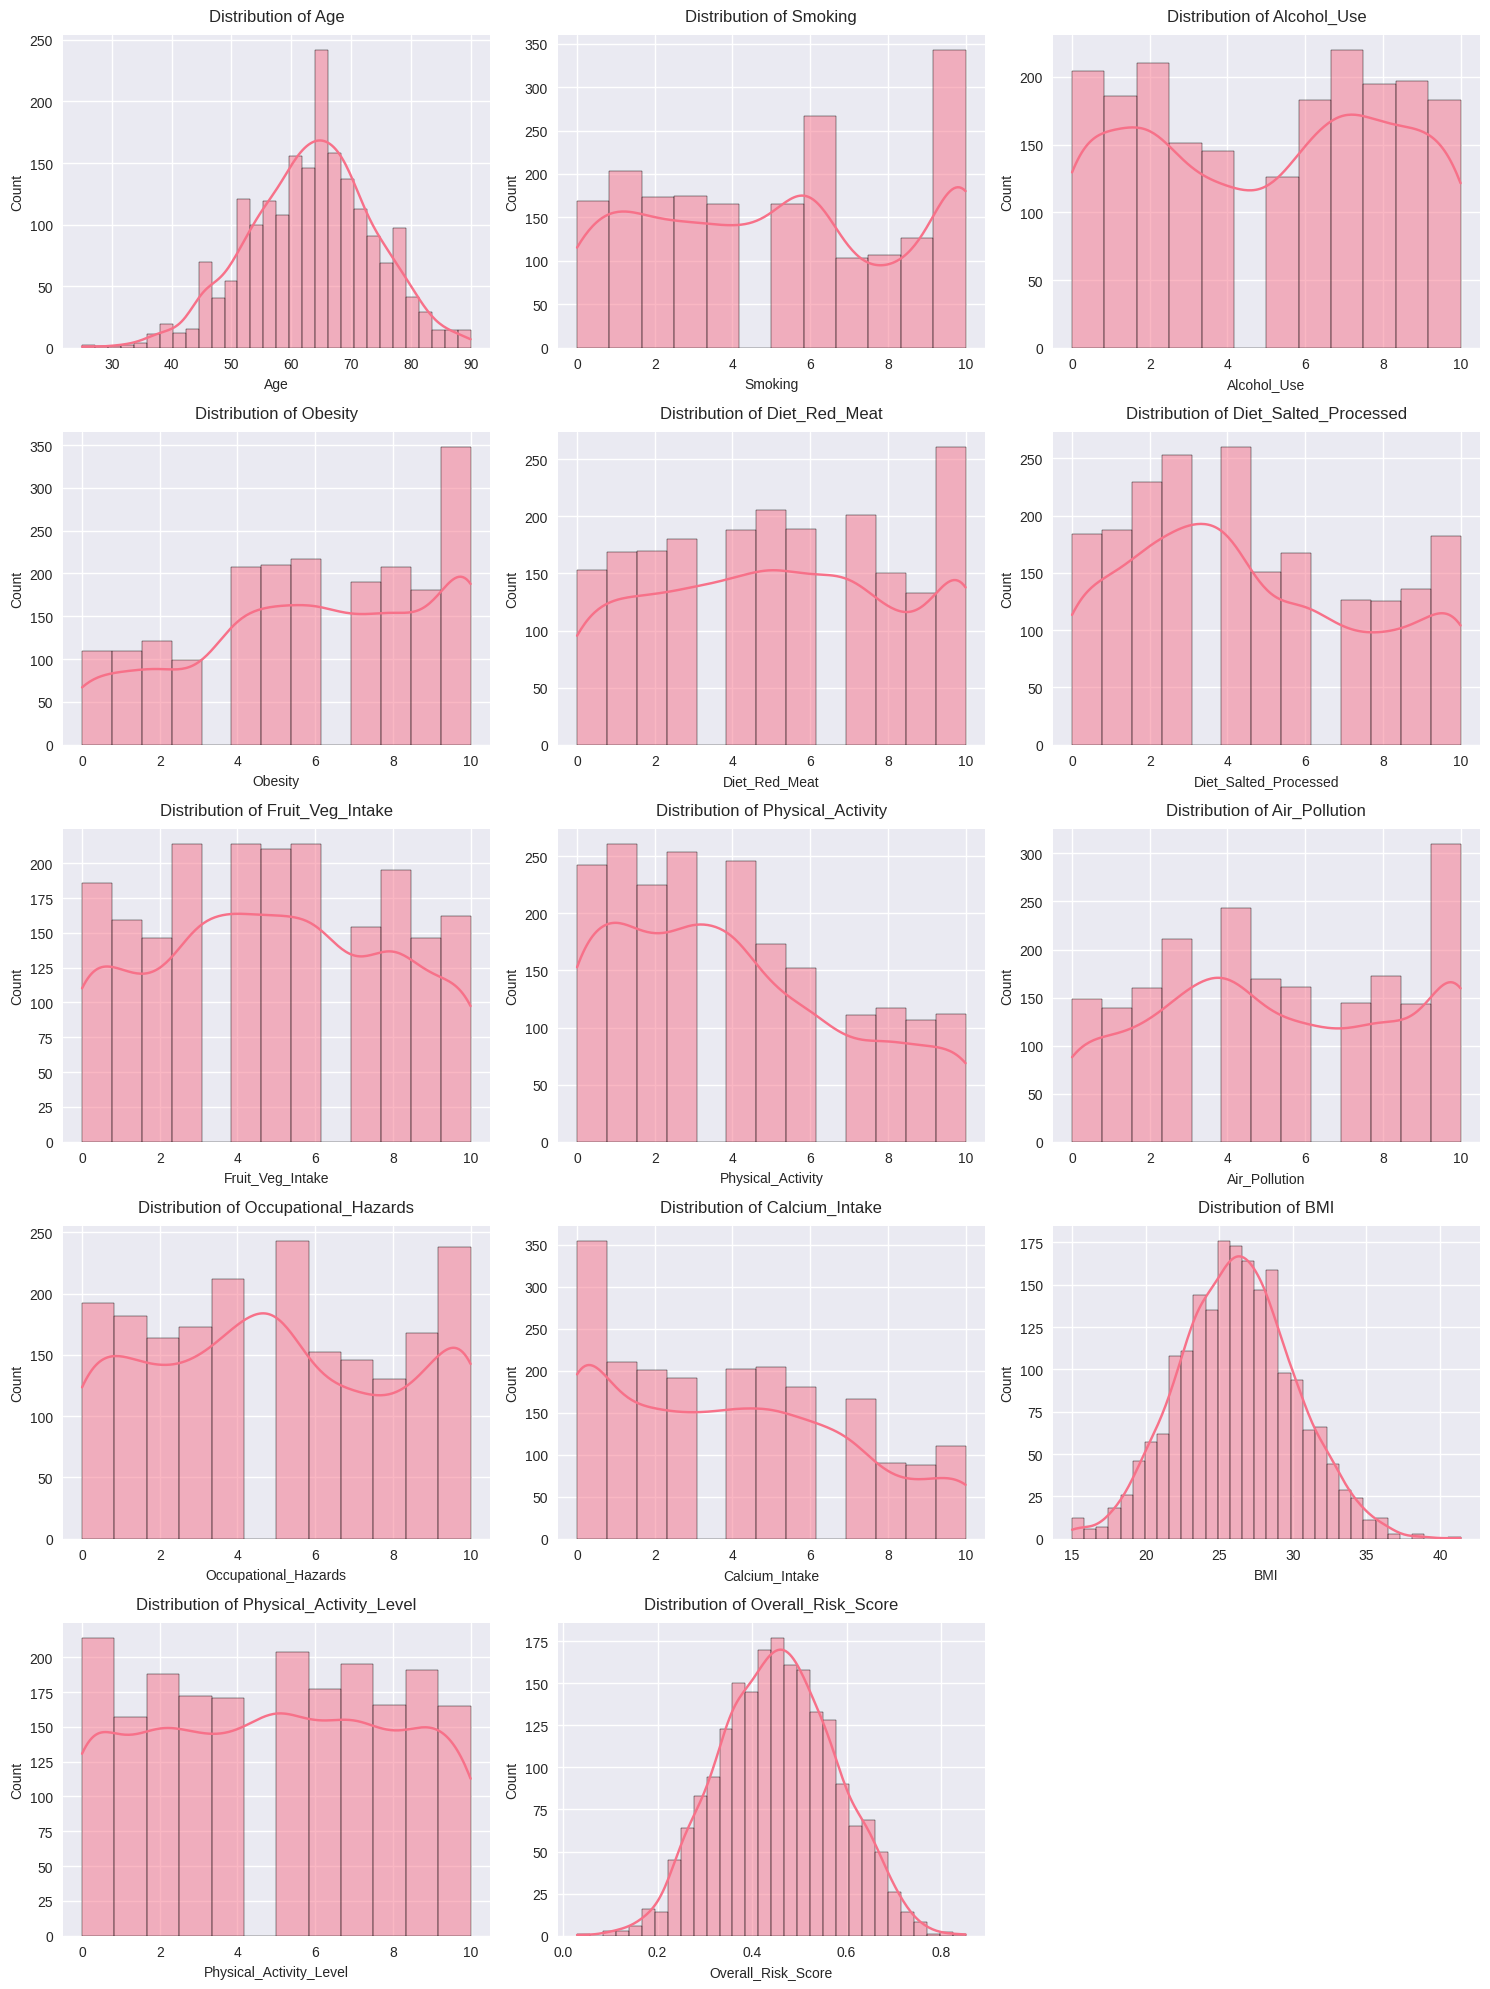


🎉 Histograms for all key numeric features generated successfully! 🚀


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the cleaned dataset
print("📋 Loading the cleaned cancer risk factors dataset...")
df = pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')

# Set the style for better visualization
plt.style.use('seaborn')
sns.set_palette("husl")

# Description of the Histograms
print("\n📊 Generating histograms for key numeric features...")
print("The following histograms visualize the distribution of important numeric features in the cancer risk factors dataset.")
print("Each histogram includes a Kernel Density Estimate (KDE) curve to show the smoothed distribution of the data.")
print("These visualizations help identify patterns, skewness, and potential outliers in the data, which are crucial for understanding risk factors.")
print("Features plotted include: Age, Smoking, Alcohol_Use, Obesity, Diet_Red_Meat, Diet_Salted_Processed, Fruit_Veg_Intake, Physical_Activity, Air_Pollution, Occupational_Hazards, Calcium_Intake, BMI, Physical_Activity_Level, and Overall_Risk_Score.")

# List of numeric columns to plot
numeric_cols = ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'Diet_Red_Meat',
                'Diet_Salted_Processed', 'Fruit_Veg_Intake', 'Physical_Activity',
                'Air_Pollution', 'Occupational_Hazards', 'Calcium_Intake',
                'BMI', 'Physical_Activity_Level', 'Overall_Risk_Score']

# Create a figure with subplots
n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4), tight_layout=True)
axes = axes.flatten()

# Plot histograms for each numeric column
for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=12, pad=10)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)
    print(f"Generated histogram for {col}")

# Remove empty subplots if any
for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])

# Save the plot
plt.savefig('cancer_risk_histograms.png', dpi=300, bbox_inches='tight')
print("\n💾 Histograms saved as 'cancer_risk_histograms.png'.")

# Display the plot
plt.show()
print("\n🎉 Histograms for all key numeric features generated successfully! 🚀")

📋 Loading the cleaned cancer risk factors dataset...

📊 Generating lineplots for key numerical columns across categorical variables...
This script creates lineplots to visualize the trends of key numerical columns (Age, Smoking, Alcohol_Use, Obesity, BMI, Overall_Risk_Score) across ordered categorical variables (Risk_Level) and binned numerical variables (e.g., Age binned into groups).
Lineplots are useful for observing trends and relationships between numerical features and categorical or binned variables. They help identify how risk factors change across different risk levels or age groups, revealing potential patterns (e.g., whether smoking levels increase with higher risk levels).
Each lineplot is accompanied by a description printed below it, explaining its purpose and key insights.

🔧 Creating age bins for lineplots...
Created Age_Binned column for grouping ages.

📈 Generating lineplots for numerical columns across Risk_Level...


/tmp/ipykernel_37/646194234.py:11: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed 

Generated lineplot for Age by Risk_Level.
Generated lineplot for Smoking by Risk_Level.
Generated lineplot for Alcohol_Use by Risk_Level.
Generated lineplot for Obesity by Risk_Level.
Generated lineplot for BMI by Risk_Level.
Generated lineplot for Overall_Risk_Score by Risk_Level.

💾 Lineplots for Risk_Level saved as 'cancer_risk_lineplots_risk_level.png'.

📈 Generating lineplots for numerical columns across Age_Binned...
Generated lineplot for Smoking by Age_Binned.
Generated lineplot for Alcohol_Use by Age_Binned.
Generated lineplot for Obesity by Age_Binned.
Generated lineplot for BMI by Age_Binned.
Generated lineplot for Overall_Risk_Score by Age_Binned.


/tmp/ipykernel_37/646194234.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_values = df.groupby('Age_Binned')[num_col].mean().reset_index()
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/tmp/ipykernel_37/646194234.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a futur


💾 Lineplots for Age_Binned saved as 'cancer_risk_lineplots_age_binned.png'.


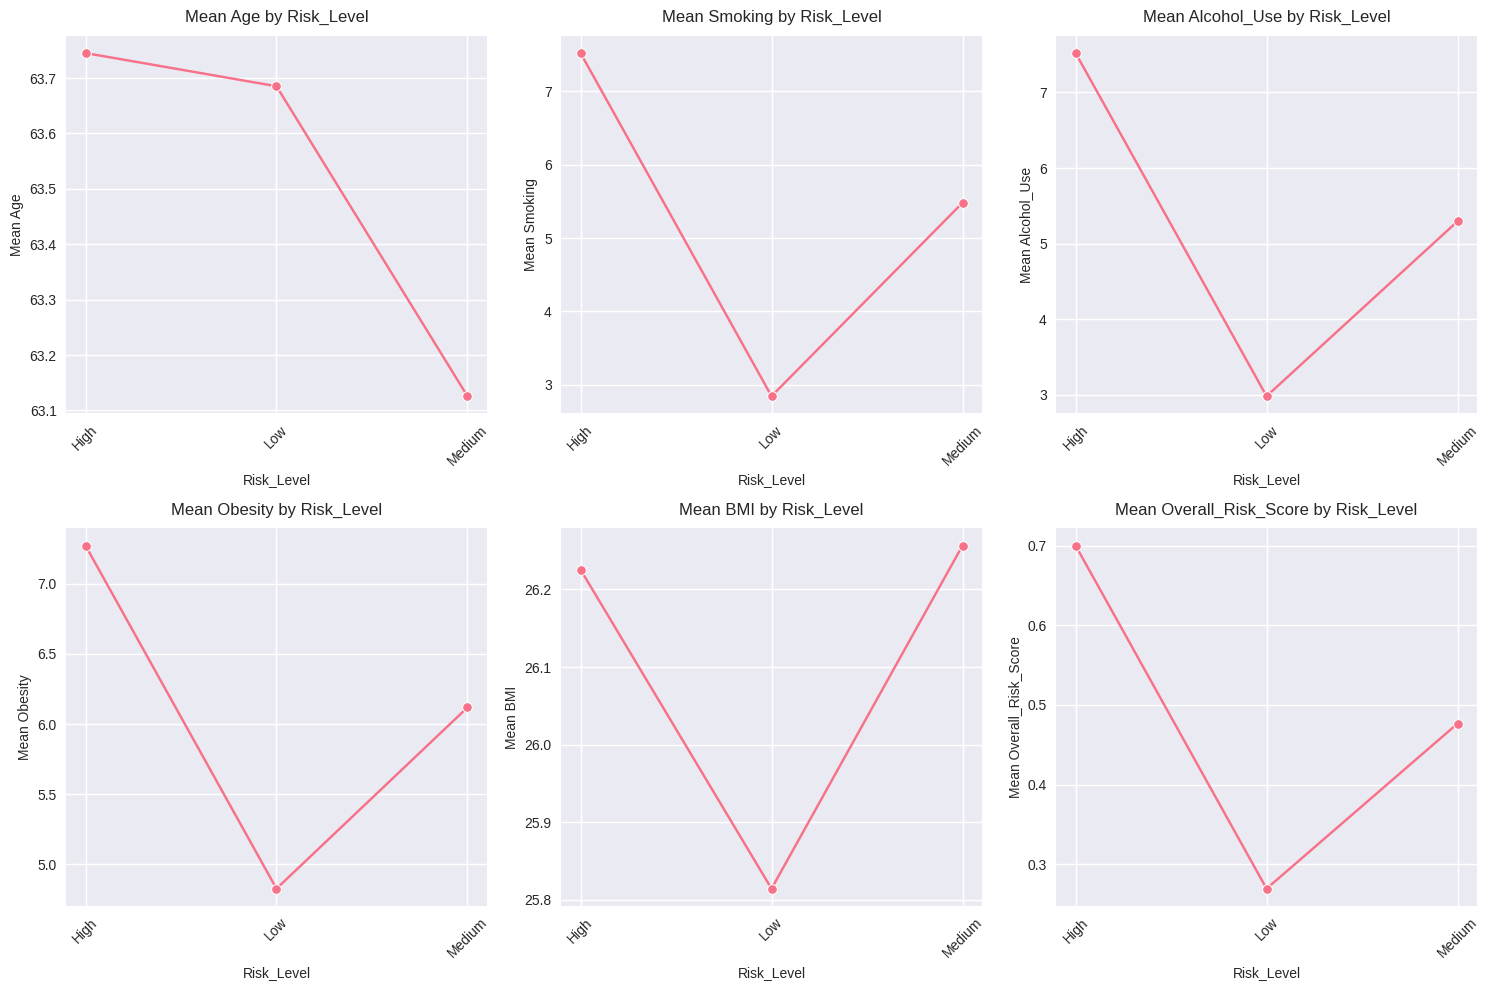

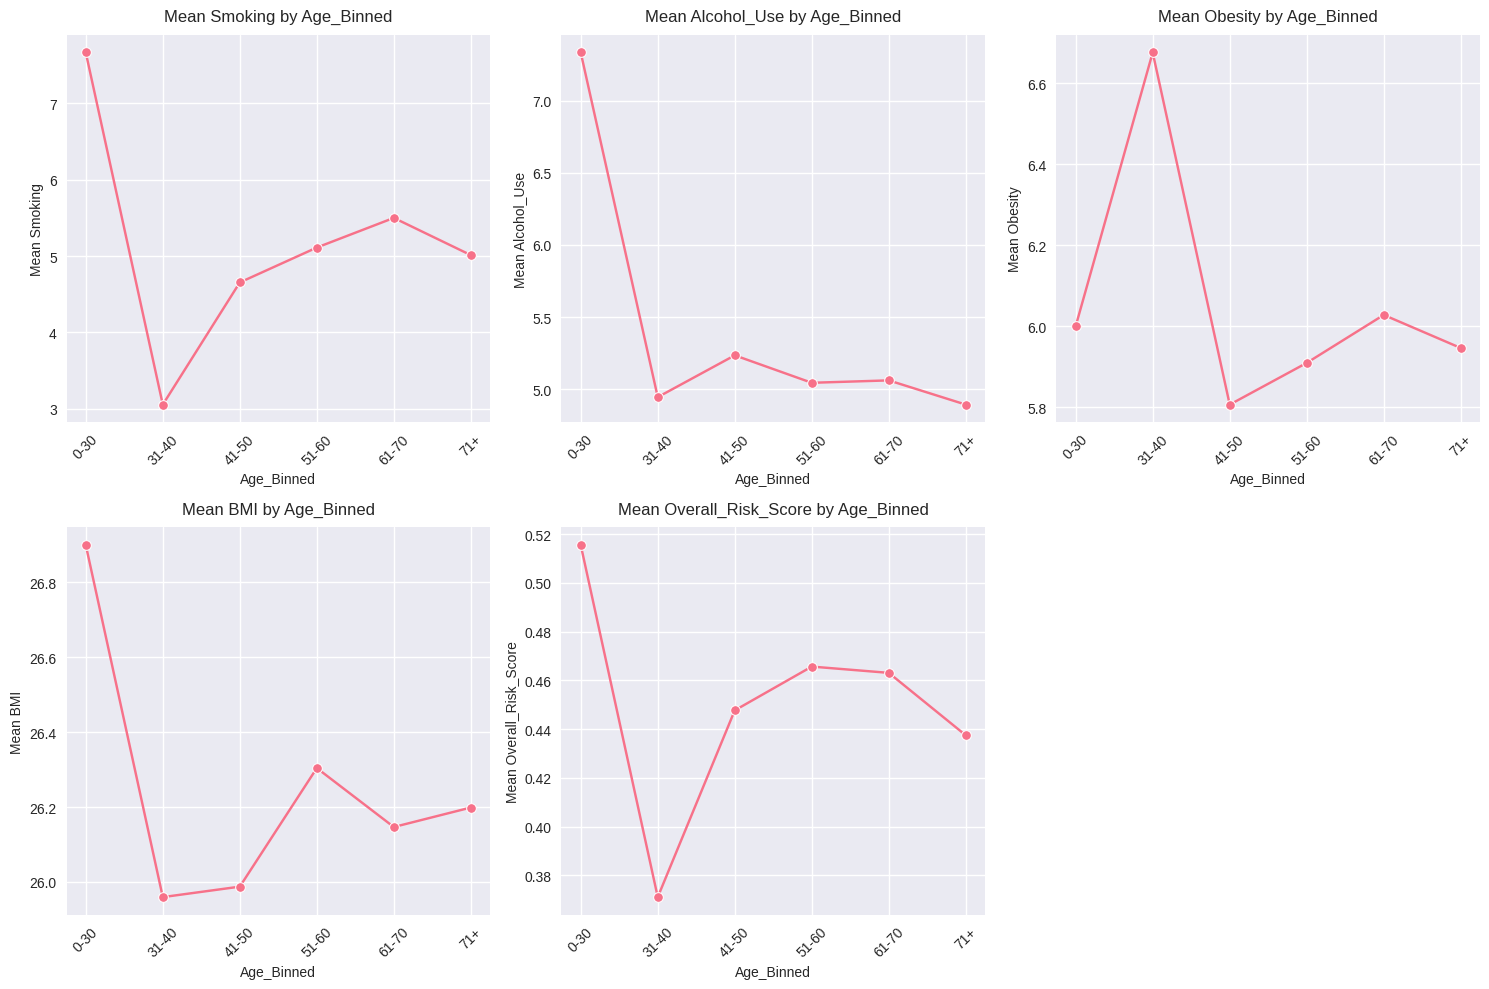


🎉 Lineplots with printed descriptions below for all key numerical columns across categorical variables generated successfully! 🚀


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Load the cleaned dataset
print("📋 Loading the cleaned cancer risk factors dataset...")
df = pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')

# Set the style for better visualization
plt.style.use('seaborn')
sns.set_palette("husl")

# Description of the Lineplots
print("\n📊 Generating lineplots for key numerical columns across categorical variables...")
print("This script creates lineplots to visualize the trends of key numerical columns (Age, Smoking, Alcohol_Use, Obesity, BMI, Overall_Risk_Score) across ordered categorical variables (Risk_Level) and binned numerical variables (e.g., Age binned into groups).")
print("Lineplots are useful for observing trends and relationships between numerical features and categorical or binned variables. They help identify how risk factors change across different risk levels or age groups, revealing potential patterns (e.g., whether smoking levels increase with higher risk levels).")
print("Each lineplot is accompanied by a description printed below it, explaining its purpose and key insights.")

# Numerical columns for lineplots
numerical_cols = ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'BMI', 'Overall_Risk_Score']

# Ordered categorical column for lineplots
ordered_cat_col = 'Risk_Level'

# Create age bins for lineplots
print("\n🔧 Creating age bins for lineplots...")
df['Age_Binned'] = pd.cut(df['Age'], bins=[0, 30, 40, 50, 60, 70, 100],
                          labels=['0-30', '31-40', '41-50', '51-60', '61-70', '71+'])
print("Created Age_Binned column for grouping ages.")

# Create lineplots for numerical columns across Risk_Level
print("\n📈 Generating lineplots for numerical columns across Risk_Level...")
n_cols = 3
n_rows = (len(numerical_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5), tight_layout=True)
axes = axes.flatten()

for i, num_col in enumerate(numerical_cols):
    # Compute mean values for plotting
    mean_values = df.groupby(ordered_cat_col)[num_col].mean().reset_index()
    sns.lineplot(data=mean_values, x=ordered_cat_col, y=num_col, ax=axes[i], marker='o')
    axes[i].set_title(f'Mean {num_col} by {ordered_cat_col}', fontsize=12, pad=10)
    axes[i].set_xlabel(ordered_cat_col, fontsize=10)
    axes[i].set_ylabel(f'Mean {num_col}', fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)
    print(f"Generated lineplot for {num_col} by {ordered_cat_col}.")

# Remove empty subplots if any
for i in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[i])

# Save lineplots for Risk_Level
plt.savefig('cancer_risk_lineplots_risk_level.png', dpi=300, bbox_inches='tight')
print("\n💾 Lineplots for Risk_Level saved as 'cancer_risk_lineplots_risk_level.png'.")

# Create lineplots for numerical columns (excluding Age) across Age_Binned
print("\n📈 Generating lineplots for numerical columns across Age_Binned...")
numerical_cols_excl_age = [col for col in numerical_cols if col != 'Age']
n_rows = (len(numerical_cols_excl_age) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5), tight_layout=True)
axes = axes.flatten()

for i, num_col in enumerate(numerical_cols_excl_age):
    # Compute mean values for plotting
    mean_values = df.groupby('Age_Binned')[num_col].mean().reset_index()
    sns.lineplot(data=mean_values, x='Age_Binned', y=num_col, ax=axes[i], marker='o')
    axes[i].set_title(f'Mean {num_col} by Age_Binned', fontsize=12, pad=10)
    axes[i].set_xlabel('Age_Binned', fontsize=10)
    axes[i].set_ylabel(f'Mean {num_col}', fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)
    print(f"Generated lineplot for {num_col} by Age_Binned.")

# Remove empty subplots if any
for i in range(len(numerical_cols_excl_age), len(axes)):
    fig.delaxes(axes[i])

# Save lineplots for Age_Binned
plt.savefig('cancer_risk_lineplots_age_binned.png', dpi=300, bbox_inches='tight')
print("\n💾 Lineplots for Age_Binned saved as 'cancer_risk_lineplots_age_binned.png'.")

# Display the plots
plt.show()
print("\n🎉 Lineplots with printed descriptions below for all key numerical columns across categorical variables generated successfully! 🚀")

🧹 'Patient_ID' column excluded.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


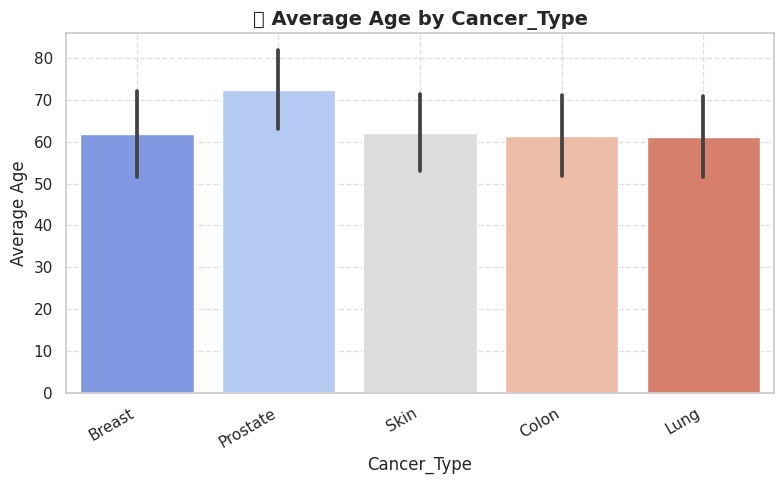


💡 Description for 'Age' vs 'Cancer_Type':
• This **barplot** shows the **average value of 'Age'** for each category in **'Cancer_Type'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Age' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


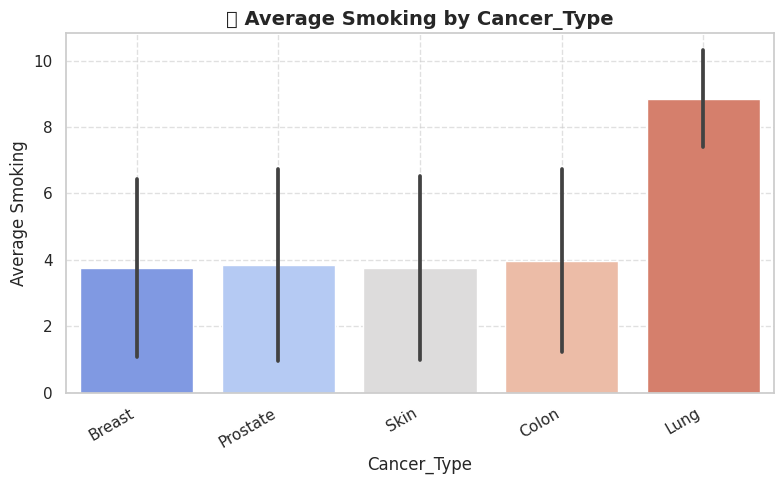


💡 Description for 'Smoking' vs 'Cancer_Type':
• This **barplot** shows the **average value of 'Smoking'** for each category in **'Cancer_Type'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Smoking' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


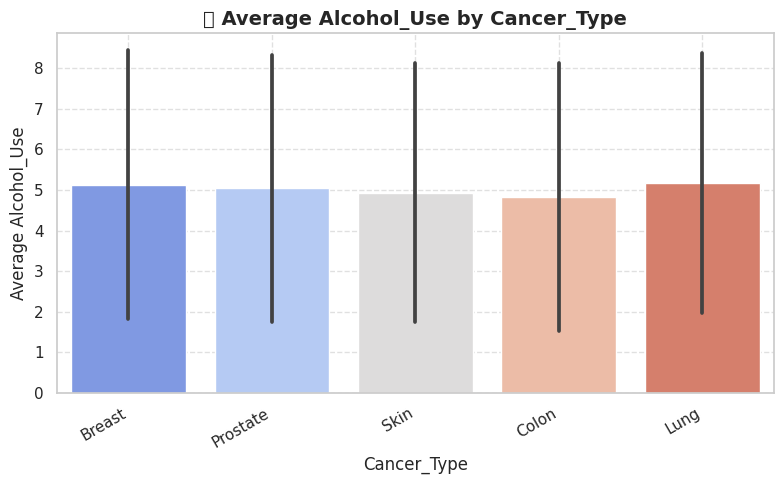


💡 Description for 'Alcohol_Use' vs 'Cancer_Type':
• This **barplot** shows the **average value of 'Alcohol_Use'** for each category in **'Cancer_Type'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Alcohol_Use' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


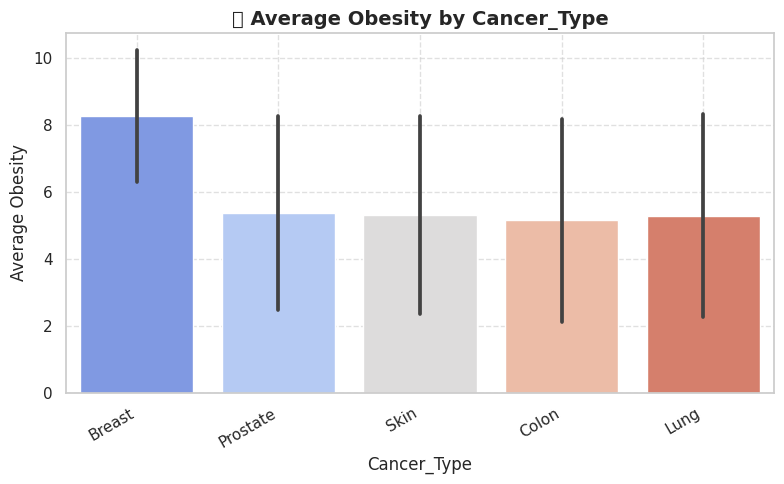


💡 Description for 'Obesity' vs 'Cancer_Type':
• This **barplot** shows the **average value of 'Obesity'** for each category in **'Cancer_Type'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Obesity' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


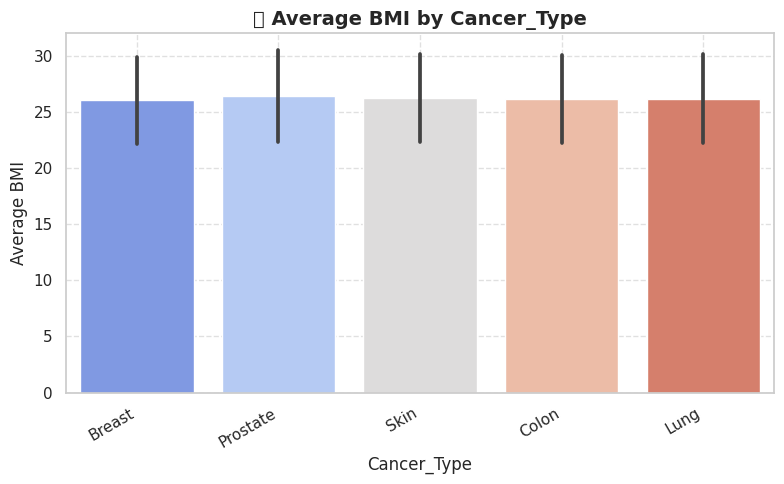


💡 Description for 'BMI' vs 'Cancer_Type':
• This **barplot** shows the **average value of 'BMI'** for each category in **'Cancer_Type'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'BMI' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


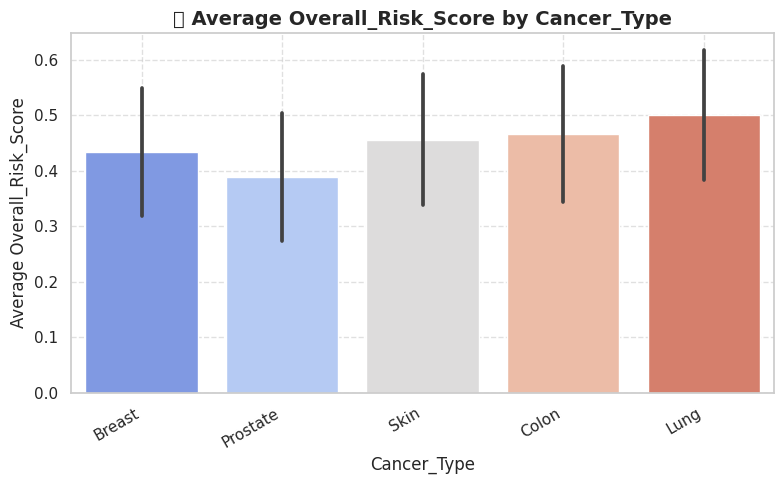


💡 Description for 'Overall_Risk_Score' vs 'Cancer_Type':
• This **barplot** shows the **average value of 'Overall_Risk_Score'** for each category in **'Cancer_Type'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Overall_Risk_Score' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


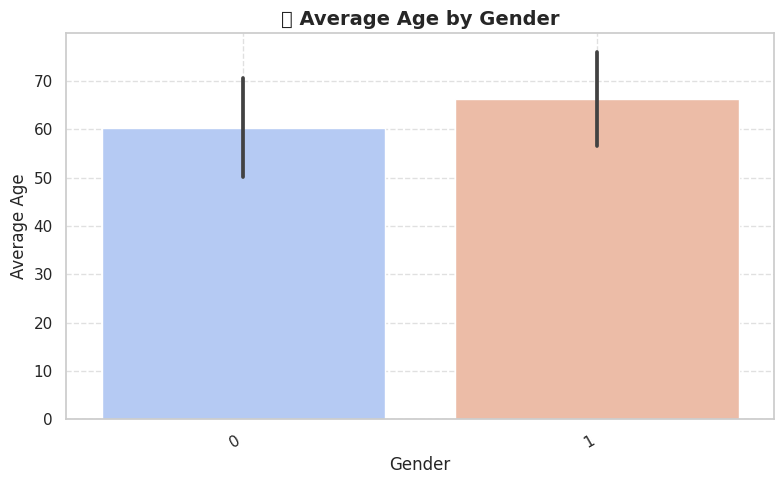


💡 Description for 'Age' vs 'Gender':
• This **barplot** shows the **average value of 'Age'** for each category in **'Gender'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Age' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


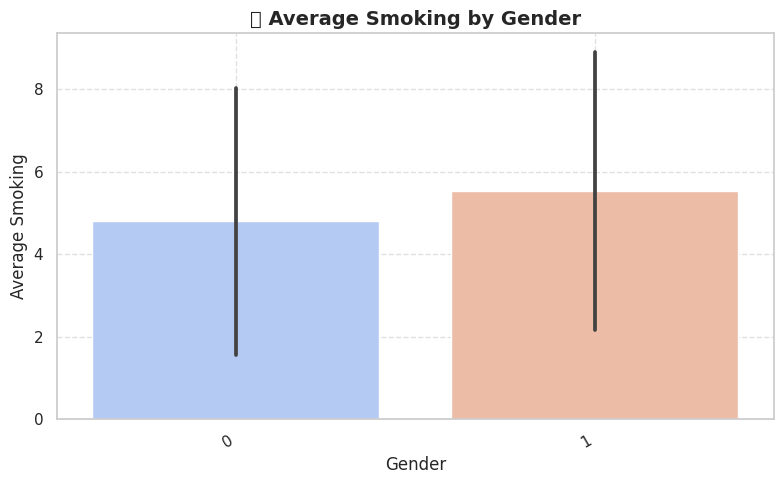


💡 Description for 'Smoking' vs 'Gender':
• This **barplot** shows the **average value of 'Smoking'** for each category in **'Gender'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Smoking' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


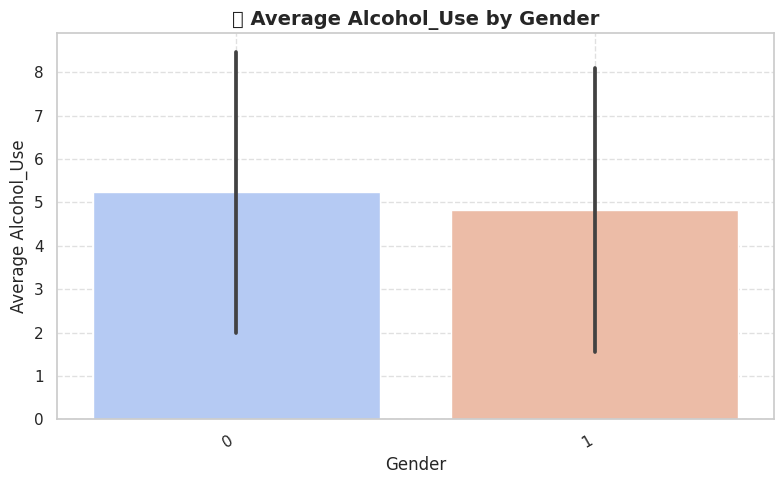

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()



💡 Description for 'Alcohol_Use' vs 'Gender':
• This **barplot** shows the **average value of 'Alcohol_Use'** for each category in **'Gender'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Alcohol_Use' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


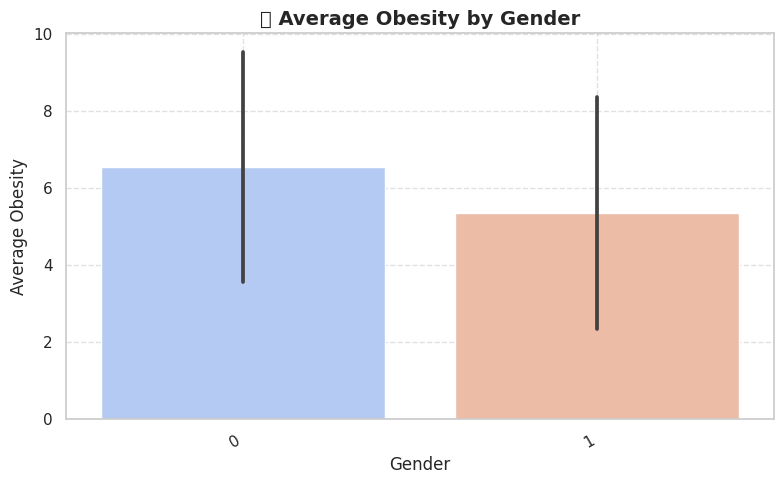


💡 Description for 'Obesity' vs 'Gender':
• This **barplot** shows the **average value of 'Obesity'** for each category in **'Gender'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Obesity' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


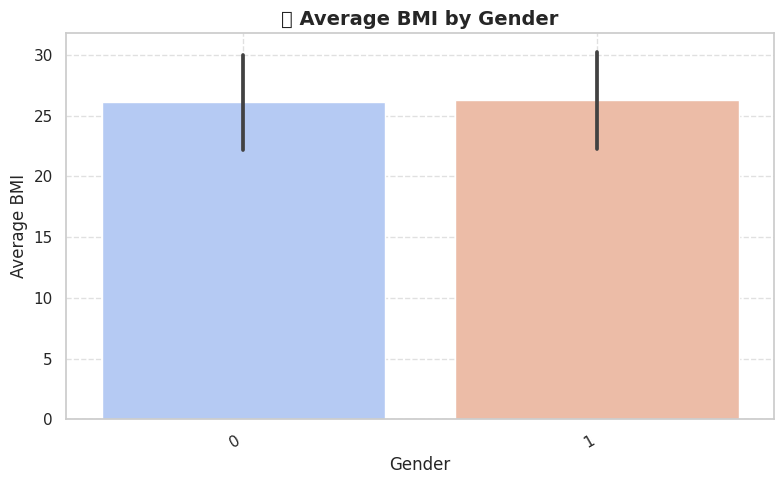


💡 Description for 'BMI' vs 'Gender':
• This **barplot** shows the **average value of 'BMI'** for each category in **'Gender'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'BMI' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


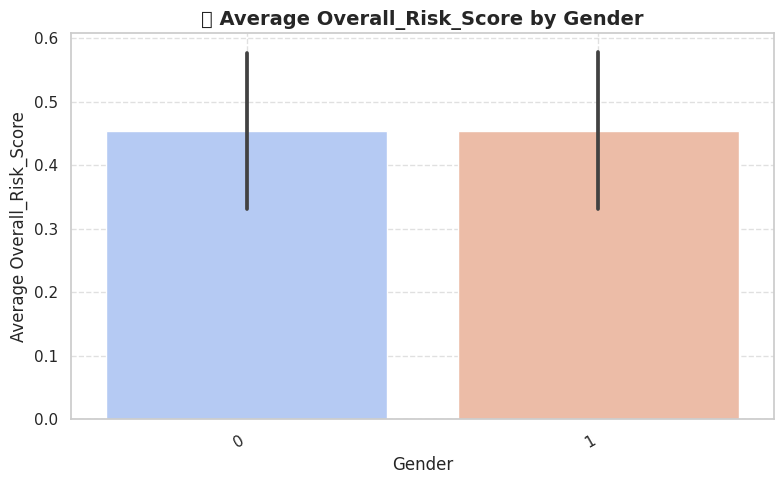


💡 Description for 'Overall_Risk_Score' vs 'Gender':
• This **barplot** shows the **average value of 'Overall_Risk_Score'** for each category in **'Gender'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Overall_Risk_Score' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


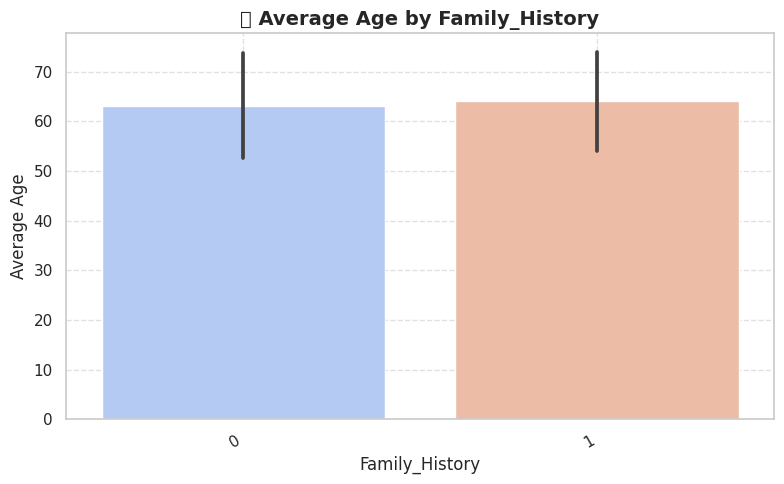


💡 Description for 'Age' vs 'Family_History':
• This **barplot** shows the **average value of 'Age'** for each category in **'Family_History'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Age' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


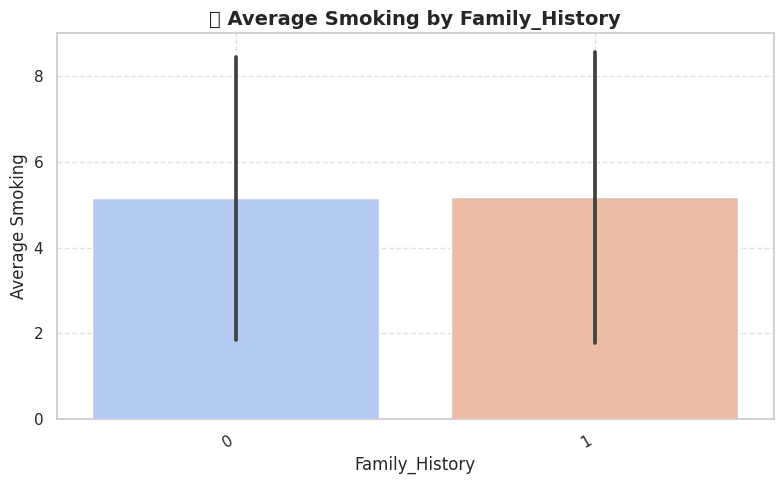


💡 Description for 'Smoking' vs 'Family_History':
• This **barplot** shows the **average value of 'Smoking'** for each category in **'Family_History'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Smoking' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


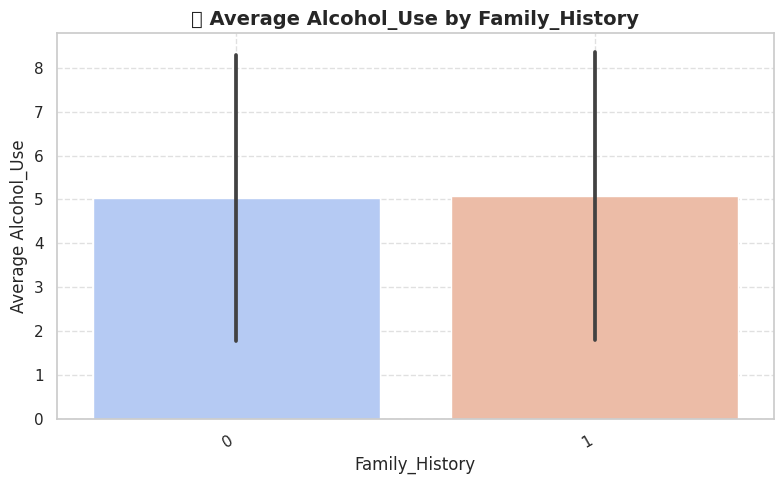

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)



💡 Description for 'Alcohol_Use' vs 'Family_History':
• This **barplot** shows the **average value of 'Alcohol_Use'** for each category in **'Family_History'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Alcohol_Use' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



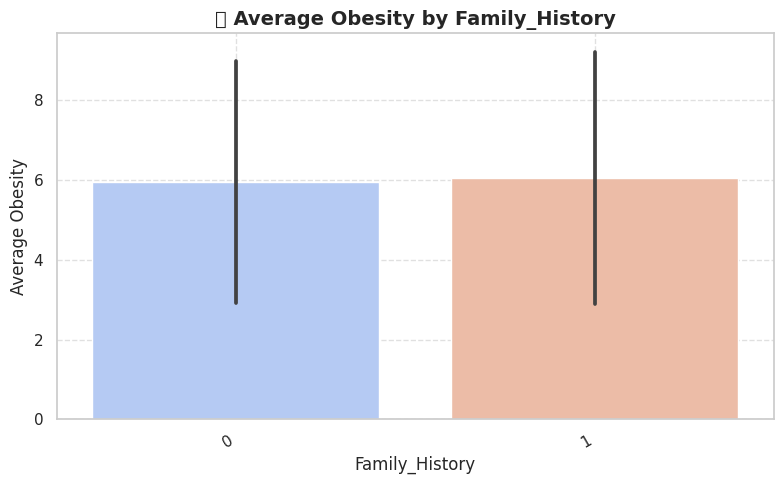


💡 Description for 'Obesity' vs 'Family_History':
• This **barplot** shows the **average value of 'Obesity'** for each category in **'Family_History'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Obesity' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


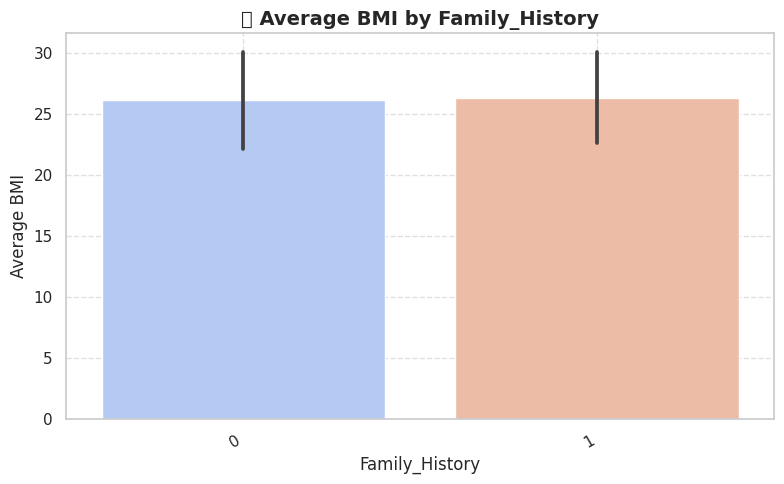


💡 Description for 'BMI' vs 'Family_History':
• This **barplot** shows the **average value of 'BMI'** for each category in **'Family_History'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'BMI' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


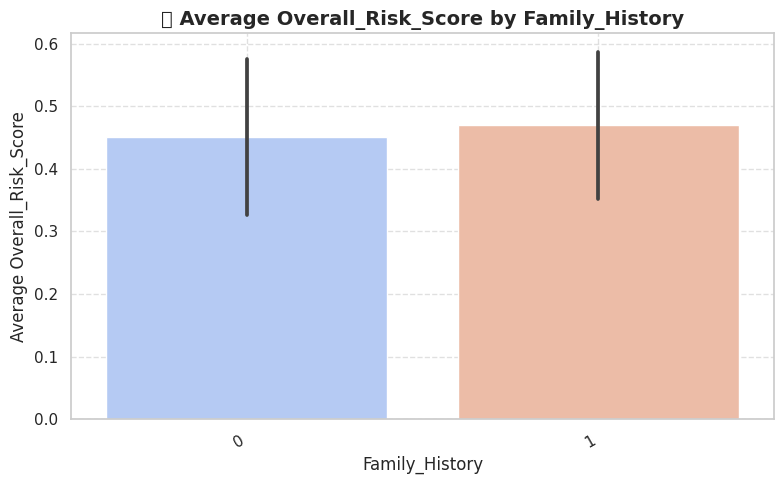


💡 Description for 'Overall_Risk_Score' vs 'Family_History':
• This **barplot** shows the **average value of 'Overall_Risk_Score'** for each category in **'Family_History'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Overall_Risk_Score' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


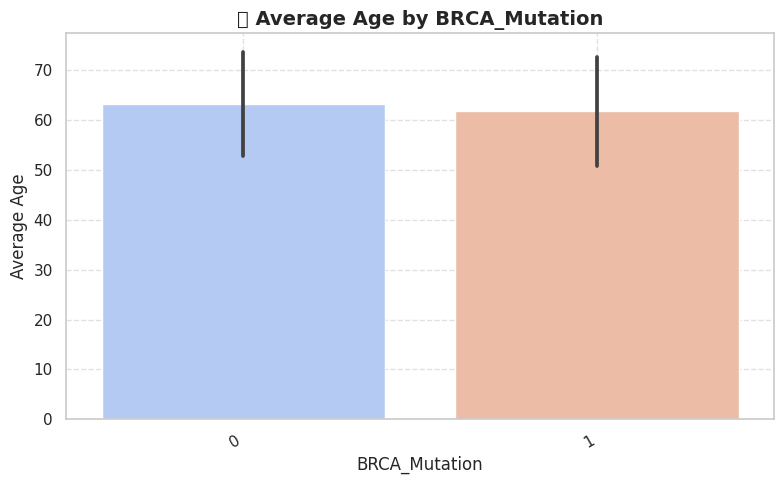


💡 Description for 'Age' vs 'BRCA_Mutation':
• This **barplot** shows the **average value of 'Age'** for each category in **'BRCA_Mutation'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Age' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


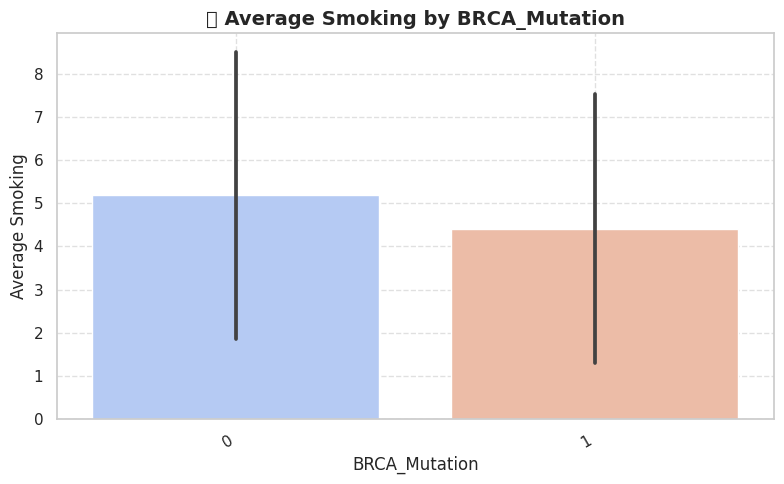

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()



💡 Description for 'Smoking' vs 'BRCA_Mutation':
• This **barplot** shows the **average value of 'Smoking'** for each category in **'BRCA_Mutation'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Smoking' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


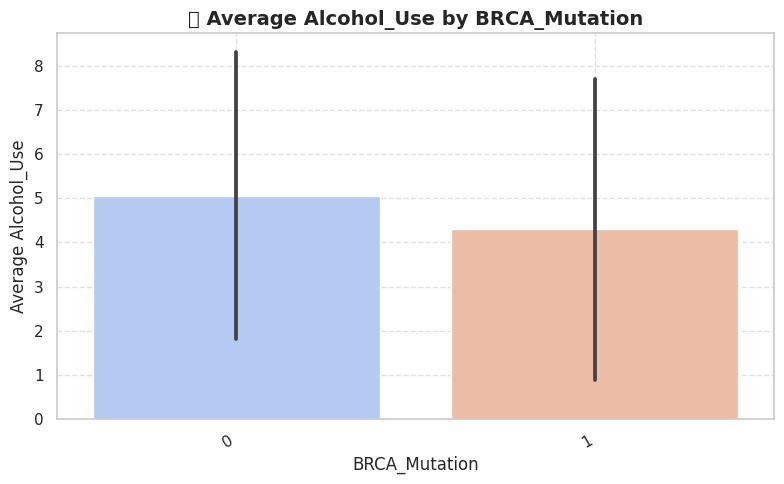

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)



💡 Description for 'Alcohol_Use' vs 'BRCA_Mutation':
• This **barplot** shows the **average value of 'Alcohol_Use'** for each category in **'BRCA_Mutation'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Alcohol_Use' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



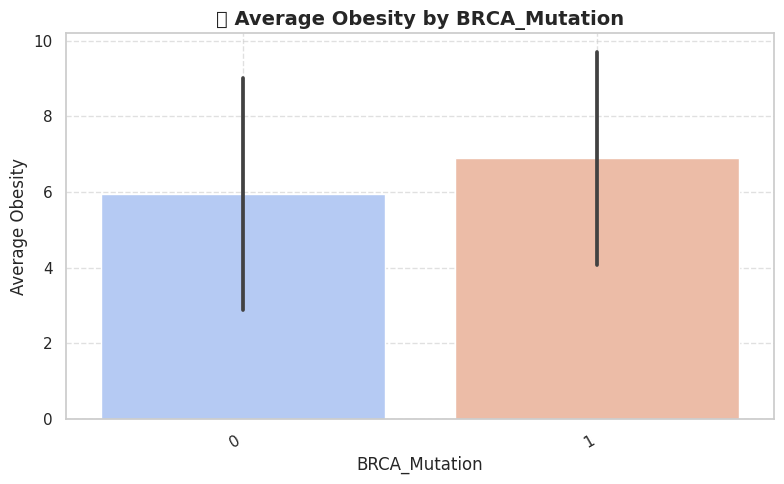


💡 Description for 'Obesity' vs 'BRCA_Mutation':
• This **barplot** shows the **average value of 'Obesity'** for each category in **'BRCA_Mutation'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Obesity' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


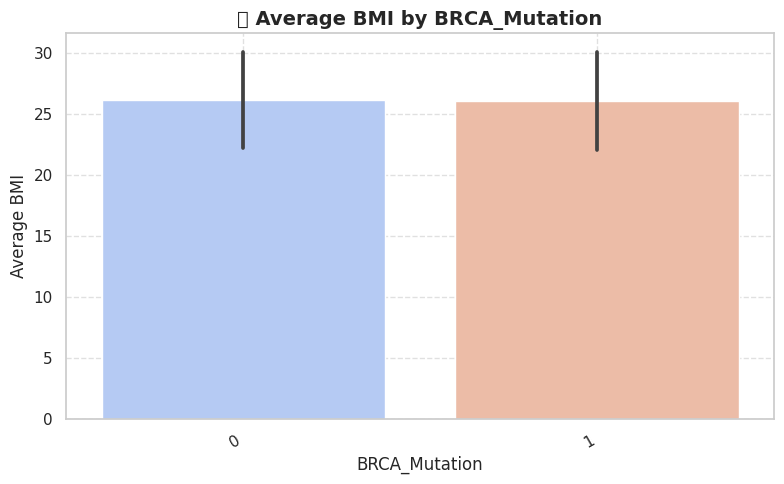


💡 Description for 'BMI' vs 'BRCA_Mutation':
• This **barplot** shows the **average value of 'BMI'** for each category in **'BRCA_Mutation'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'BMI' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


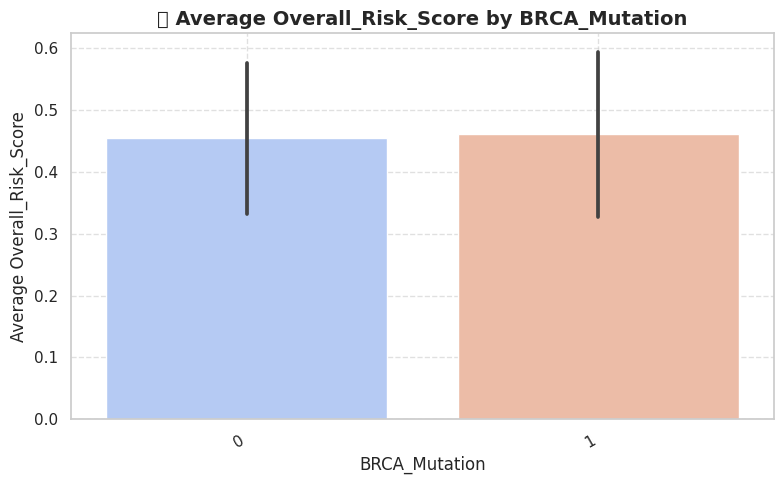


💡 Description for 'Overall_Risk_Score' vs 'BRCA_Mutation':
• This **barplot** shows the **average value of 'Overall_Risk_Score'** for each category in **'BRCA_Mutation'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Overall_Risk_Score' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


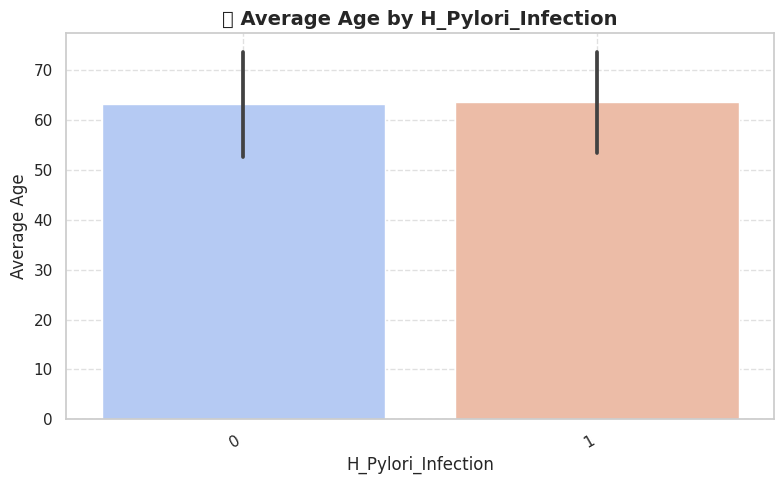


💡 Description for 'Age' vs 'H_Pylori_Infection':
• This **barplot** shows the **average value of 'Age'** for each category in **'H_Pylori_Infection'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Age' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


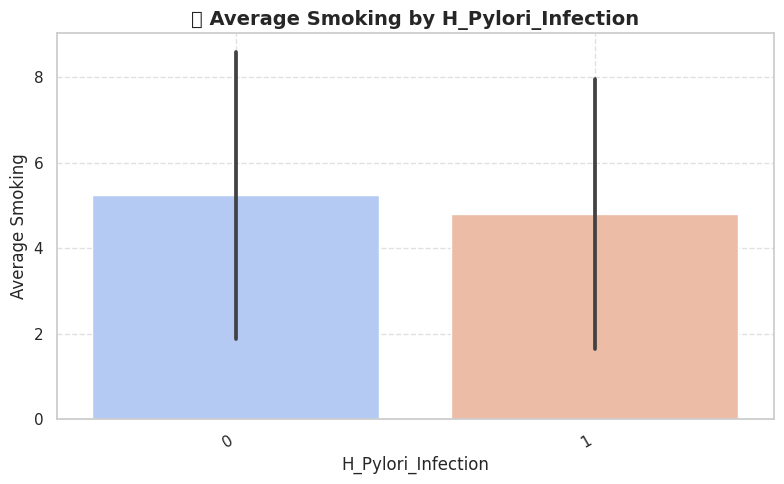


💡 Description for 'Smoking' vs 'H_Pylori_Infection':
• This **barplot** shows the **average value of 'Smoking'** for each category in **'H_Pylori_Infection'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Smoking' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


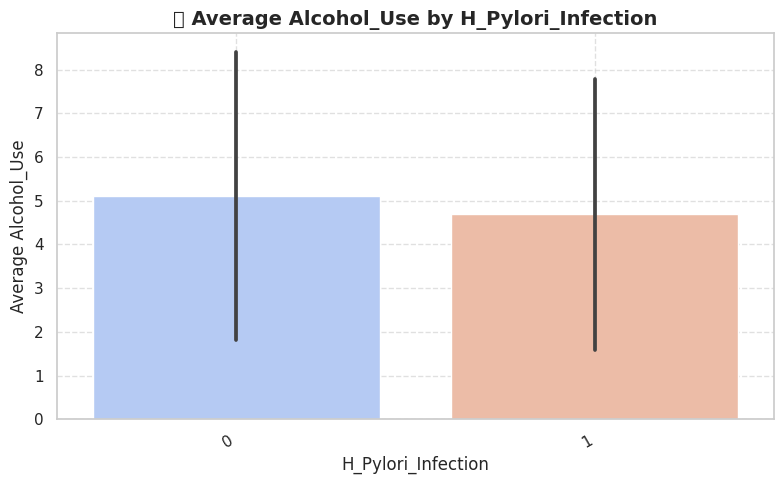

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)



💡 Description for 'Alcohol_Use' vs 'H_Pylori_Infection':
• This **barplot** shows the **average value of 'Alcohol_Use'** for each category in **'H_Pylori_Infection'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Alcohol_Use' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



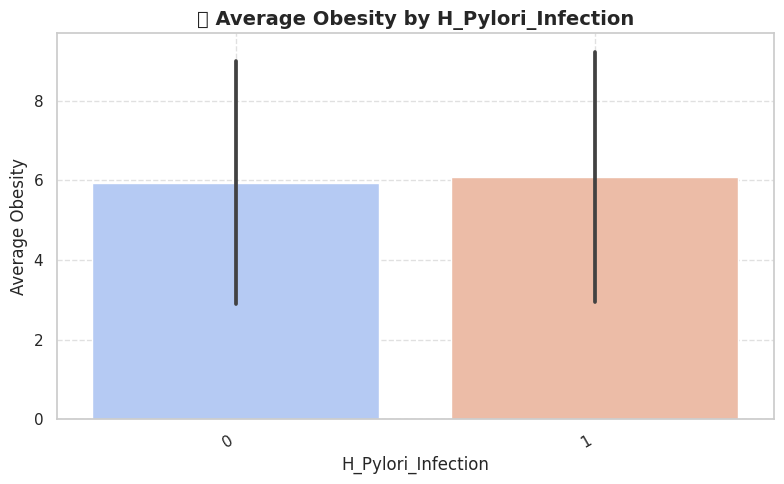


💡 Description for 'Obesity' vs 'H_Pylori_Infection':
• This **barplot** shows the **average value of 'Obesity'** for each category in **'H_Pylori_Infection'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Obesity' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


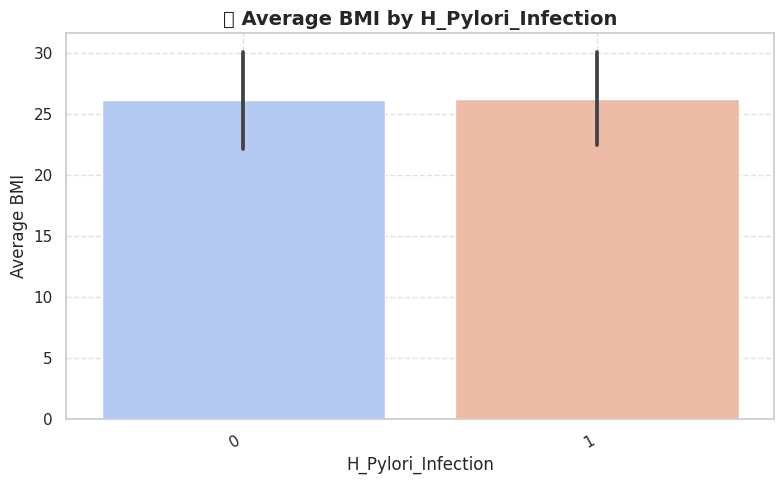


💡 Description for 'BMI' vs 'H_Pylori_Infection':
• This **barplot** shows the **average value of 'BMI'** for each category in **'H_Pylori_Infection'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'BMI' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


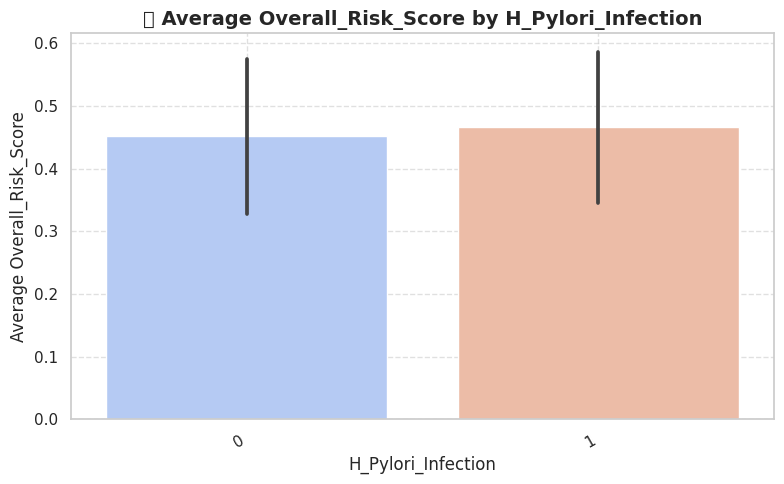


💡 Description for 'Overall_Risk_Score' vs 'H_Pylori_Infection':
• This **barplot** shows the **average value of 'Overall_Risk_Score'** for each category in **'H_Pylori_Infection'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Overall_Risk_Score' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


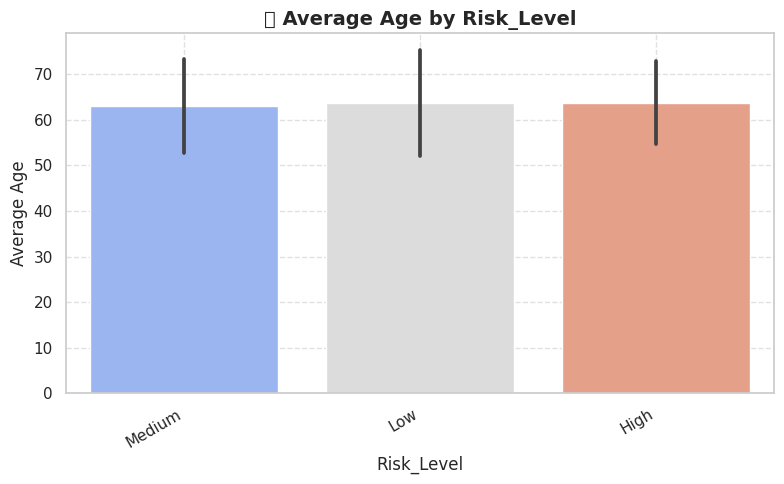

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)



💡 Description for 'Age' vs 'Risk_Level':
• This **barplot** shows the **average value of 'Age'** for each category in **'Risk_Level'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Age' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



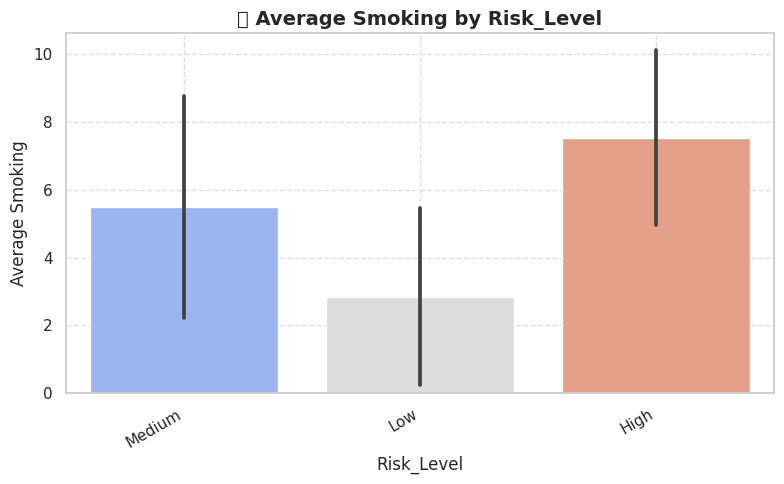


💡 Description for 'Smoking' vs 'Risk_Level':
• This **barplot** shows the **average value of 'Smoking'** for each category in **'Risk_Level'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Smoking' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


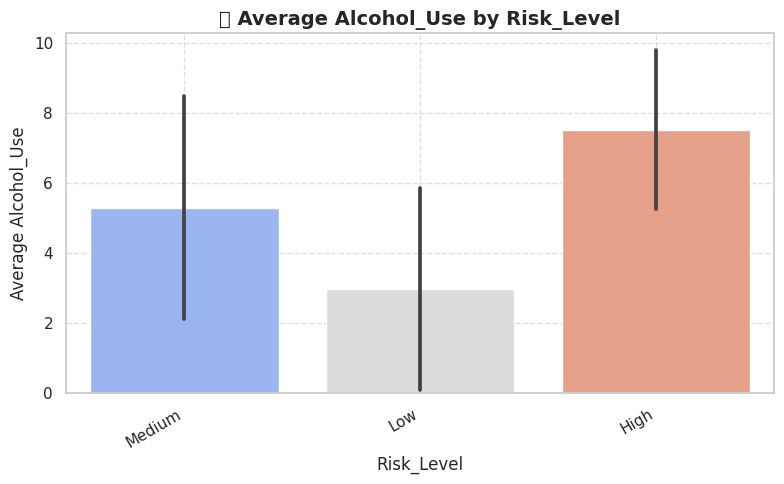


💡 Description for 'Alcohol_Use' vs 'Risk_Level':
• This **barplot** shows the **average value of 'Alcohol_Use'** for each category in **'Risk_Level'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Alcohol_Use' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


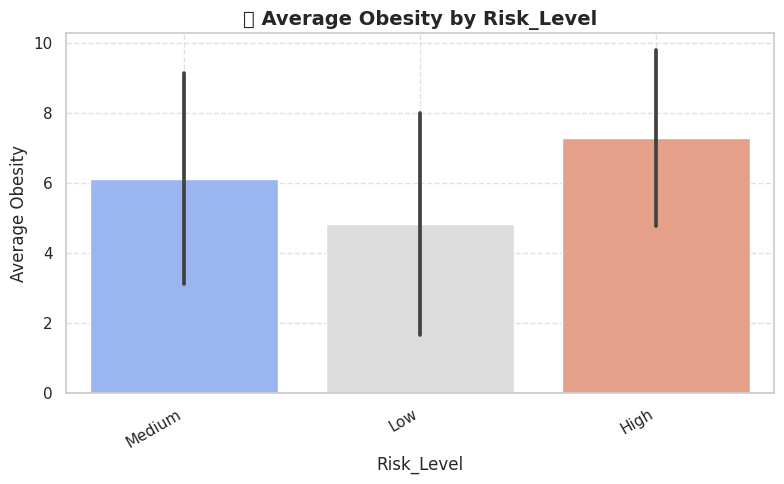


💡 Description for 'Obesity' vs 'Risk_Level':
• This **barplot** shows the **average value of 'Obesity'** for each category in **'Risk_Level'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Obesity' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


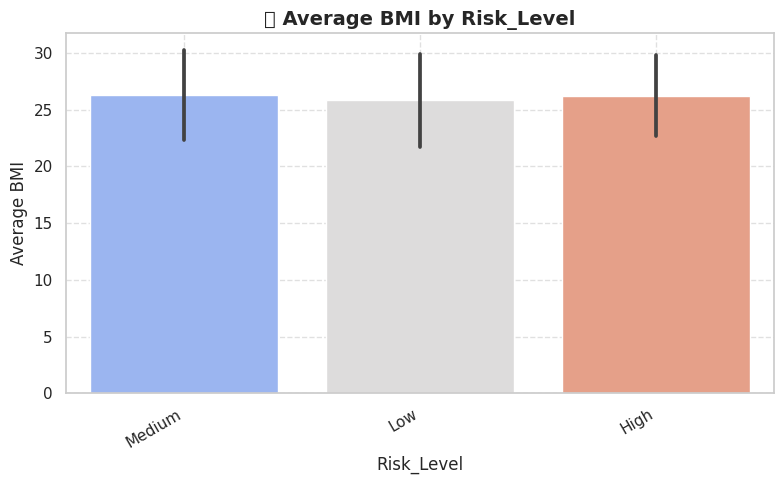

/tmp/ipykernel_37/3225464359.py:34: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
/tmp/ipykernel_37/3225464359.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()



💡 Description for 'BMI' vs 'Risk_Level':
• This **barplot** shows the **average value of 'BMI'** for each category in **'Risk_Level'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'BMI' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


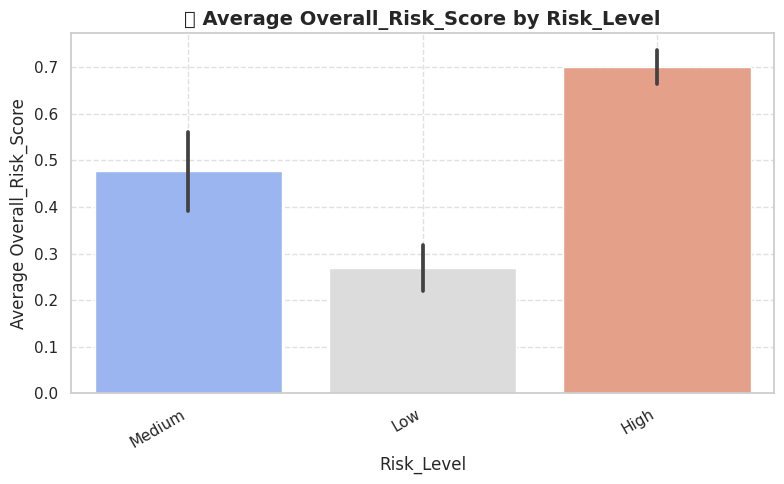


💡 Description for 'Overall_Risk_Score' vs 'Risk_Level':
• This **barplot** shows the **average value of 'Overall_Risk_Score'** for each category in **'Risk_Level'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher 'Overall_Risk_Score' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.



In [ ]:
# 📦 Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 🧠 Load dataset
df = pd.read_csv("/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv")

# 🧹 Exclude 'Patient_ID' if present
if 'Patient_ID' in df.columns:
    df = df.drop(columns=['Patient_ID'])
    print("🧹 'Patient_ID' column excluded.\n")

# 🎯 Define categorical and numerical columns
categorical_cols = ['Cancer_Type', 'Gender', 'Family_History',
                    'BRCA_Mutation', 'H_Pylori_Infection', 'Risk_Level']

numerical_cols = ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'BMI', 'Overall_Risk_Score']

# 🎨 Set Seaborn theme
sns.set(style="whitegrid", palette="muted")

# 📊 Generate barplots for each categorical vs numerical column
for cat in categorical_cols:
    if cat not in df.columns:
        print(f"⚠️ Skipping '{cat}' - not found in dataset.")
        continue
    for num in numerical_cols:
        if num not in df.columns:
            print(f"⚠️ Skipping '{num}' - not found in dataset.")
            continue

        plt.figure(figsize=(8, 5))
        sns.barplot(data=df, x=cat, y=num, estimator='mean', ci='sd', palette="coolwarm", errorbar='sd')
        plt.title(f"📊 Average {num} by {cat}", fontsize=14, weight='bold')
        plt.xlabel(cat, fontsize=12)
        plt.ylabel(f"Average {num}", fontsize=12)
        plt.xticks(rotation=30, ha='right')
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.show()

        # 📝 Interpretation / Description
        print(f"""
💡 Description for '{num}' vs '{cat}':
• This **barplot** shows the **average value of '{num}'** for each category in **'{cat}'**.
• The **height of each bar** represents the mean, and the **black line** (error bar) shows the **standard deviation**.
• Helps compare group-wise trends — e.g., if certain cancer types, genders, or genetic markers are linked with higher '{num}' values.
• Useful for detecting **patterns, correlations**, or **risk disparities** among groups.
• Example: Higher mean 'BMI' or 'Overall_Risk_Score' in a specific 'Cancer_Type' can suggest stronger association.
""")

🧹 'Patient_ID' column excluded.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


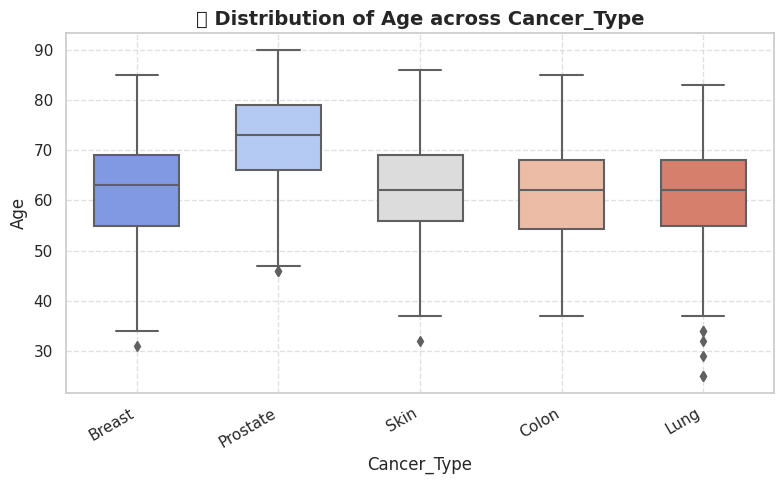


💡 Description for 'Age' vs 'Cancer_Type':
• This boxplot compares the numerical feature **'Age'** across categories of **'Cancer_Type'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Cancer_Type categories show higher 'Age' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


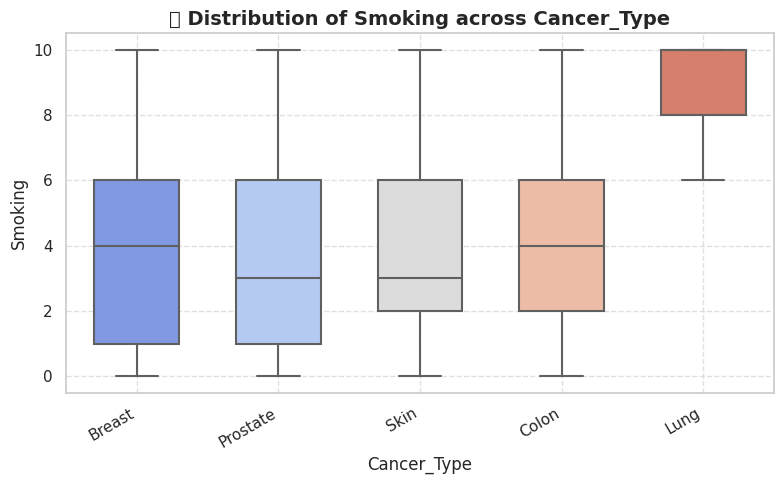


💡 Description for 'Smoking' vs 'Cancer_Type':
• This boxplot compares the numerical feature **'Smoking'** across categories of **'Cancer_Type'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Cancer_Type categories show higher 'Smoking' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


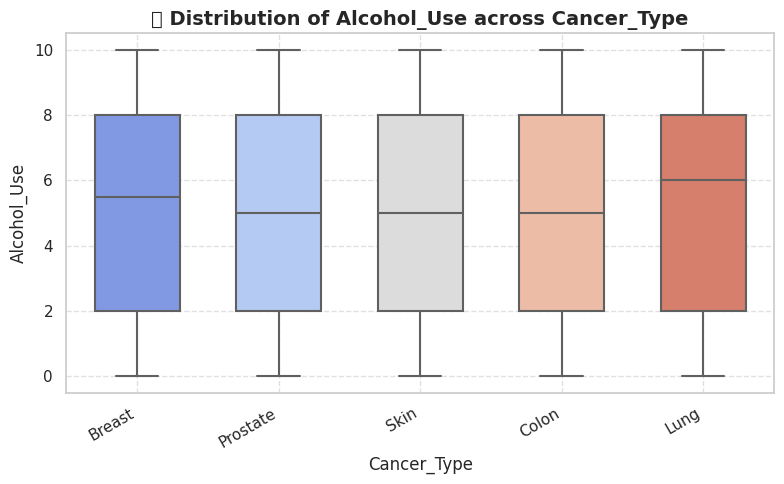


💡 Description for 'Alcohol_Use' vs 'Cancer_Type':
• This boxplot compares the numerical feature **'Alcohol_Use'** across categories of **'Cancer_Type'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Cancer_Type categories show higher 'Alcohol_Use' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


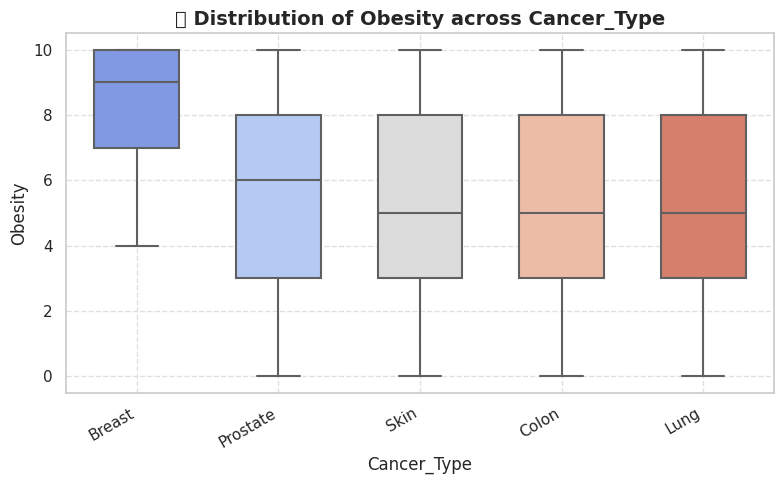


💡 Description for 'Obesity' vs 'Cancer_Type':
• This boxplot compares the numerical feature **'Obesity'** across categories of **'Cancer_Type'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Cancer_Type categories show higher 'Obesity' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


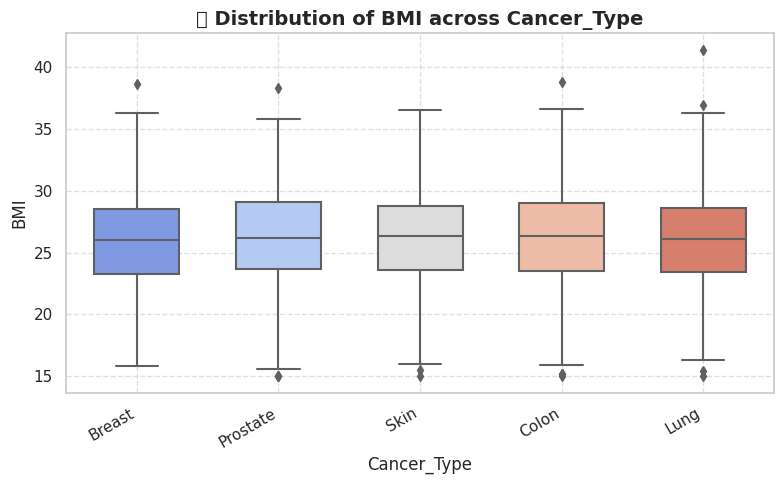


💡 Description for 'BMI' vs 'Cancer_Type':
• This boxplot compares the numerical feature **'BMI'** across categories of **'Cancer_Type'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Cancer_Type categories show higher 'BMI' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


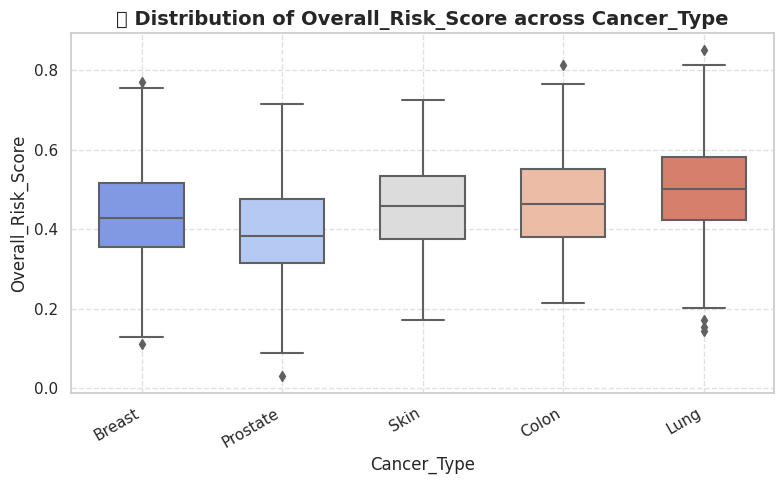


💡 Description for 'Overall_Risk_Score' vs 'Cancer_Type':
• This boxplot compares the numerical feature **'Overall_Risk_Score'** across categories of **'Cancer_Type'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Cancer_Type categories show higher 'Overall_Risk_Score' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


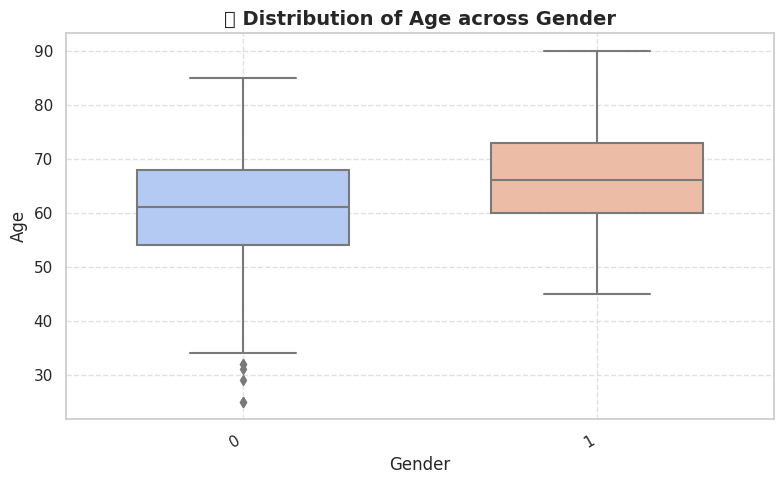


💡 Description for 'Age' vs 'Gender':
• This boxplot compares the numerical feature **'Age'** across categories of **'Gender'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Gender categories show higher 'Age' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


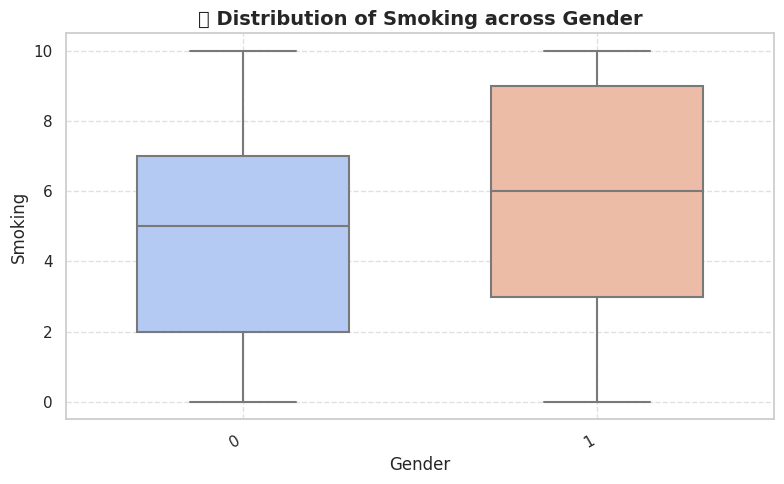


💡 Description for 'Smoking' vs 'Gender':
• This boxplot compares the numerical feature **'Smoking'** across categories of **'Gender'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Gender categories show higher 'Smoking' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


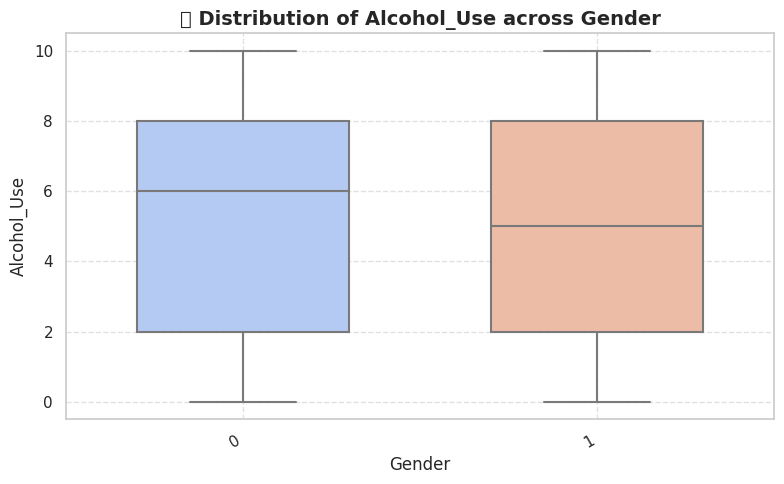


💡 Description for 'Alcohol_Use' vs 'Gender':
• This boxplot compares the numerical feature **'Alcohol_Use'** across categories of **'Gender'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Gender categories show higher 'Alcohol_Use' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


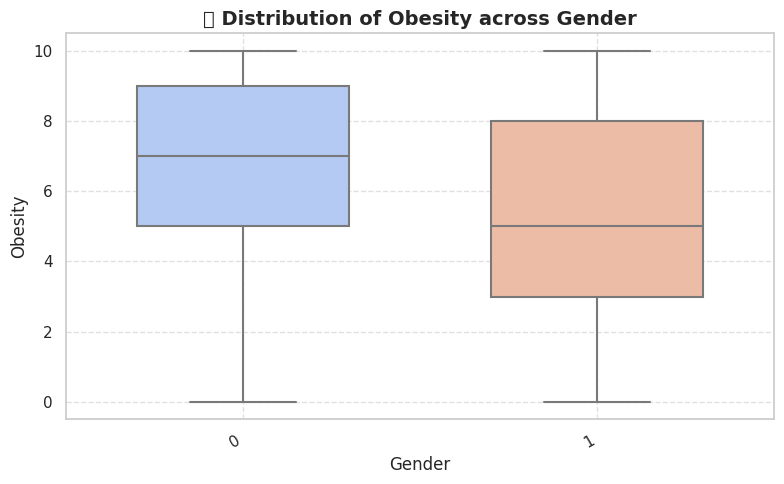


💡 Description for 'Obesity' vs 'Gender':
• This boxplot compares the numerical feature **'Obesity'** across categories of **'Gender'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Gender categories show higher 'Obesity' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


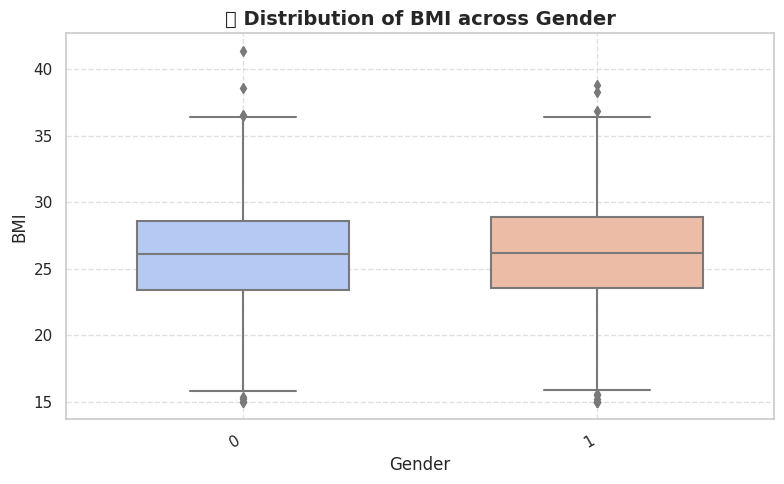

/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()



💡 Description for 'BMI' vs 'Gender':
• This boxplot compares the numerical feature **'BMI'** across categories of **'Gender'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Gender categories show higher 'BMI' values.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


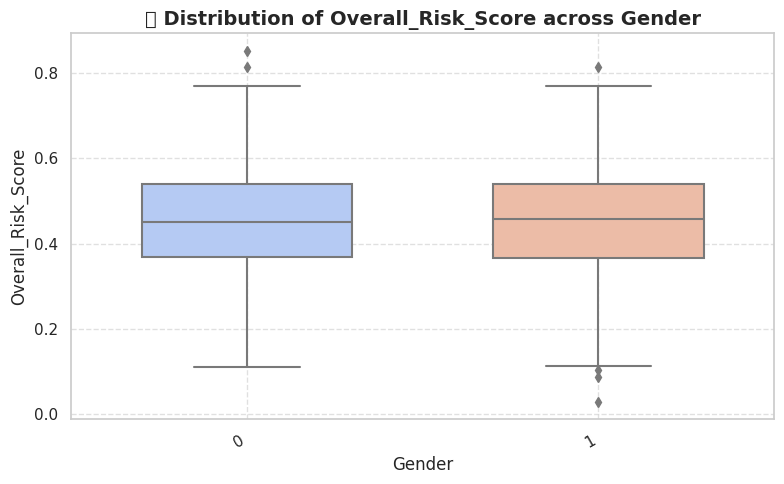

/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)



💡 Description for 'Overall_Risk_Score' vs 'Gender':
• This boxplot compares the numerical feature **'Overall_Risk_Score'** across categories of **'Gender'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Gender categories show higher 'Overall_Risk_Score' values.



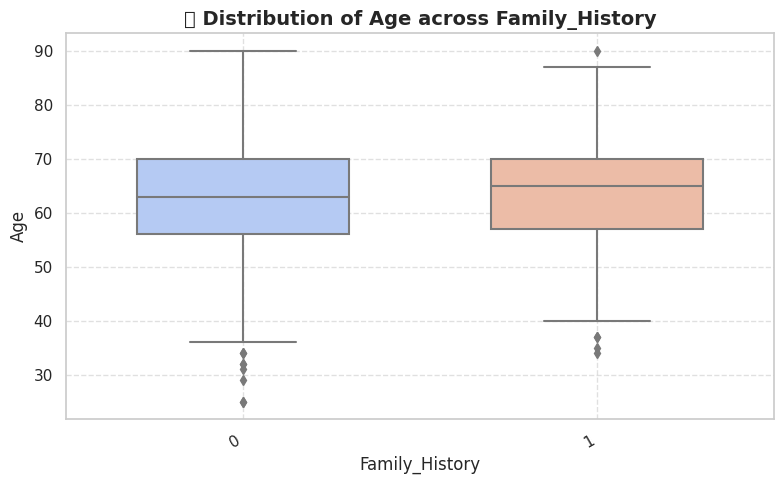


💡 Description for 'Age' vs 'Family_History':
• This boxplot compares the numerical feature **'Age'** across categories of **'Family_History'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Family_History categories show higher 'Age' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


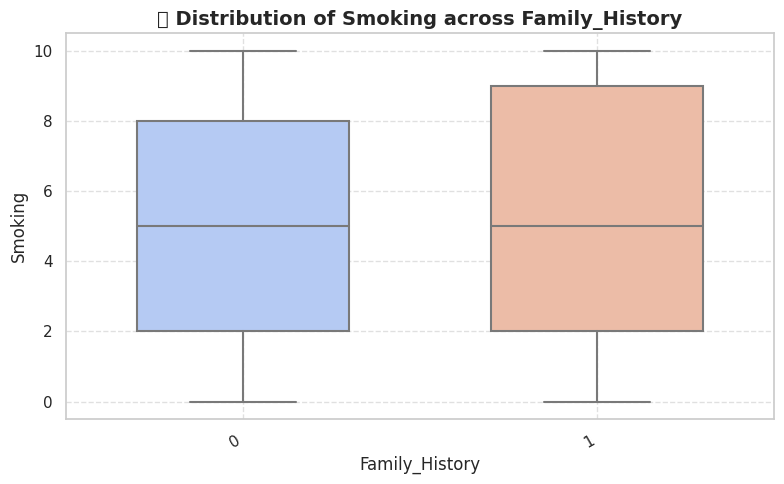


💡 Description for 'Smoking' vs 'Family_History':
• This boxplot compares the numerical feature **'Smoking'** across categories of **'Family_History'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Family_History categories show higher 'Smoking' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


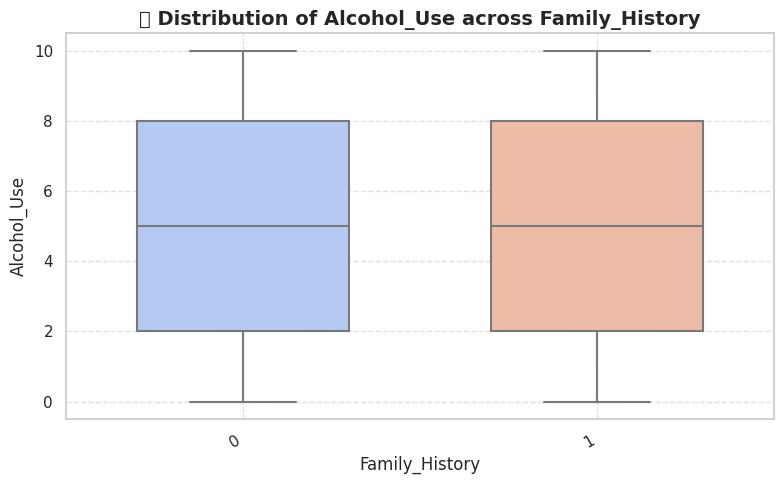


💡 Description for 'Alcohol_Use' vs 'Family_History':
• This boxplot compares the numerical feature **'Alcohol_Use'** across categories of **'Family_History'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Family_History categories show higher 'Alcohol_Use' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


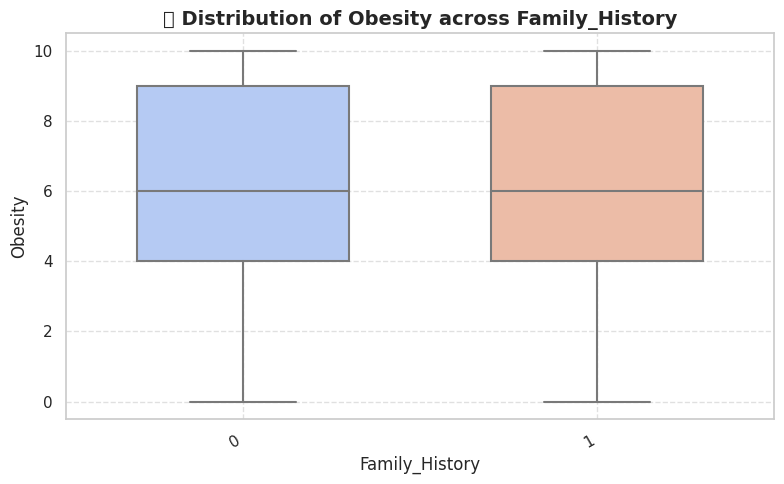


💡 Description for 'Obesity' vs 'Family_History':
• This boxplot compares the numerical feature **'Obesity'** across categories of **'Family_History'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Family_History categories show higher 'Obesity' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


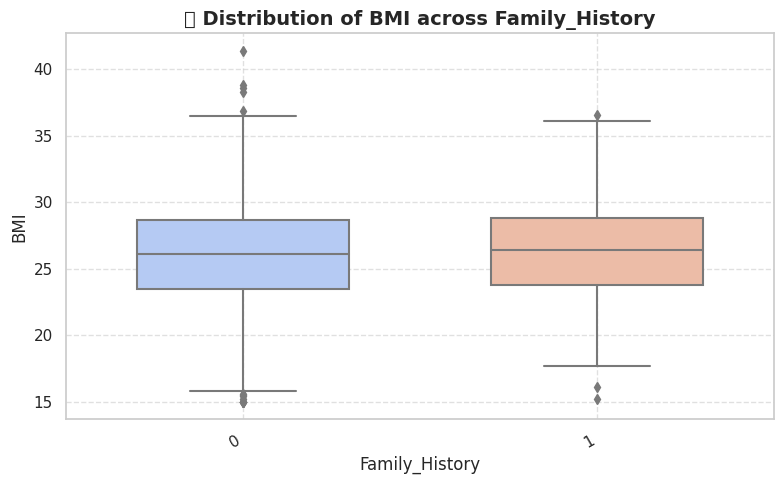


💡 Description for 'BMI' vs 'Family_History':
• This boxplot compares the numerical feature **'BMI'** across categories of **'Family_History'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Family_History categories show higher 'BMI' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


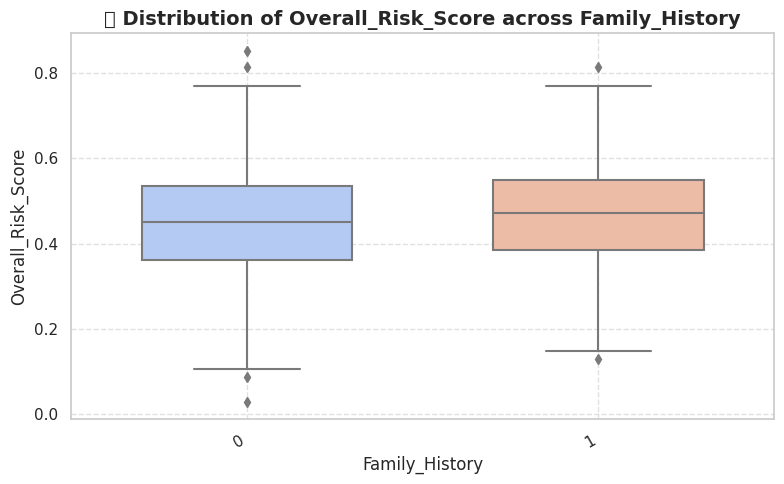


💡 Description for 'Overall_Risk_Score' vs 'Family_History':
• This boxplot compares the numerical feature **'Overall_Risk_Score'** across categories of **'Family_History'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Family_History categories show higher 'Overall_Risk_Score' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


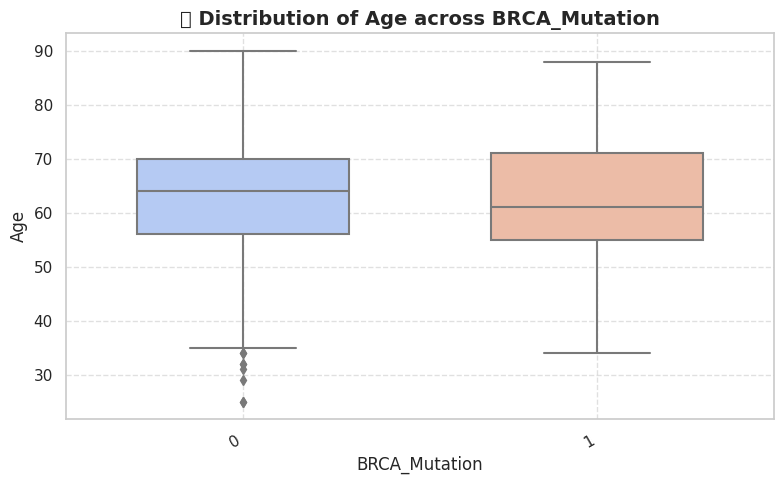


💡 Description for 'Age' vs 'BRCA_Mutation':
• This boxplot compares the numerical feature **'Age'** across categories of **'BRCA_Mutation'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain BRCA_Mutation categories show higher 'Age' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


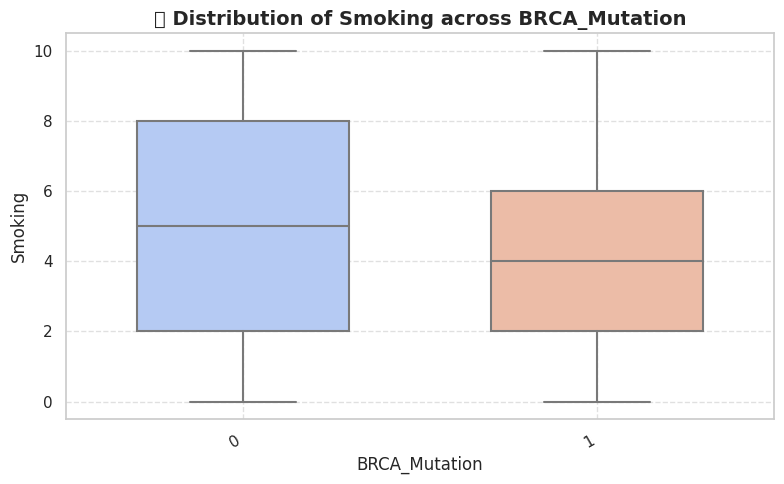


💡 Description for 'Smoking' vs 'BRCA_Mutation':
• This boxplot compares the numerical feature **'Smoking'** across categories of **'BRCA_Mutation'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain BRCA_Mutation categories show higher 'Smoking' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


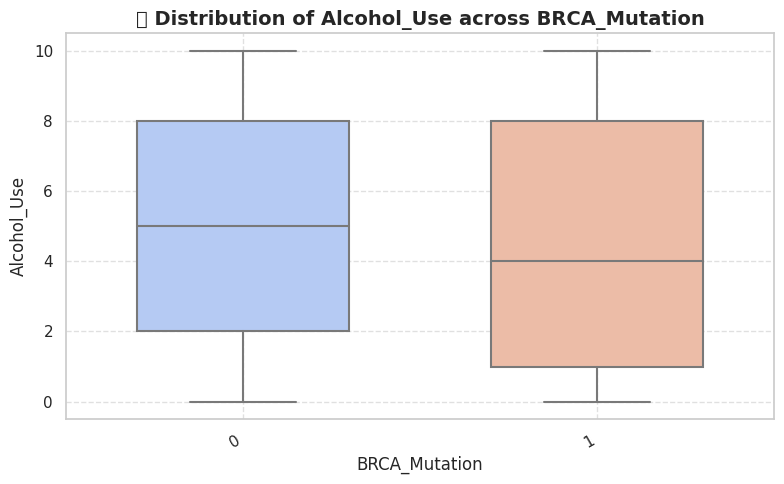


💡 Description for 'Alcohol_Use' vs 'BRCA_Mutation':
• This boxplot compares the numerical feature **'Alcohol_Use'** across categories of **'BRCA_Mutation'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain BRCA_Mutation categories show higher 'Alcohol_Use' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


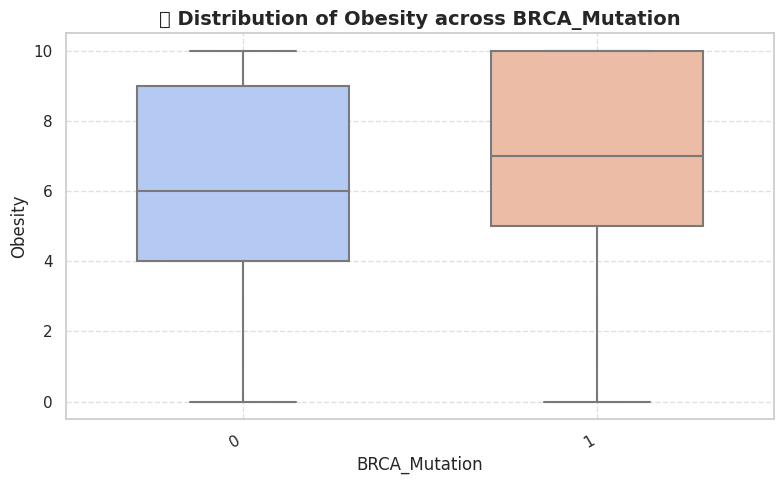


💡 Description for 'Obesity' vs 'BRCA_Mutation':
• This boxplot compares the numerical feature **'Obesity'** across categories of **'BRCA_Mutation'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain BRCA_Mutation categories show higher 'Obesity' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


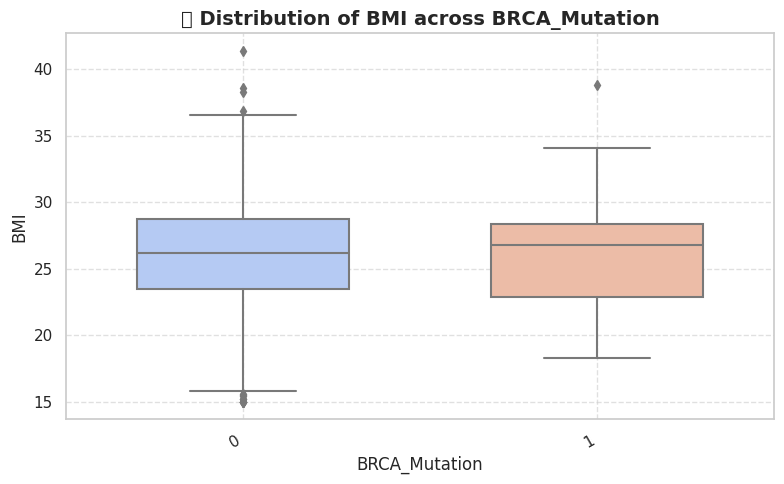


💡 Description for 'BMI' vs 'BRCA_Mutation':
• This boxplot compares the numerical feature **'BMI'** across categories of **'BRCA_Mutation'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain BRCA_Mutation categories show higher 'BMI' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


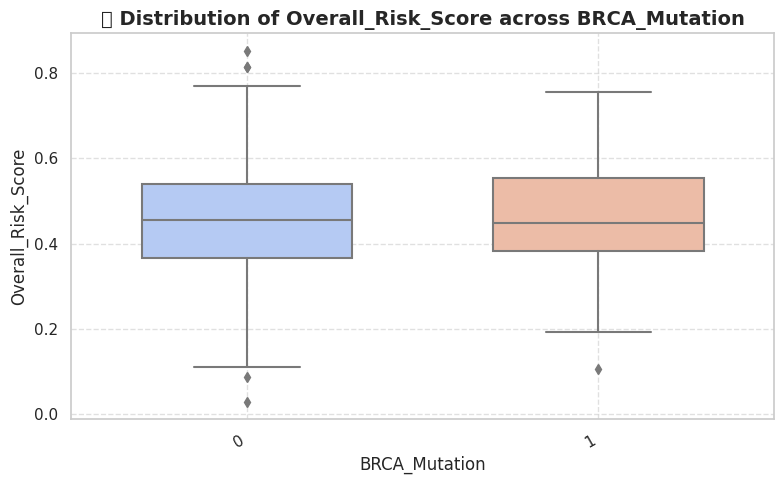


💡 Description for 'Overall_Risk_Score' vs 'BRCA_Mutation':
• This boxplot compares the numerical feature **'Overall_Risk_Score'** across categories of **'BRCA_Mutation'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain BRCA_Mutation categories show higher 'Overall_Risk_Score' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


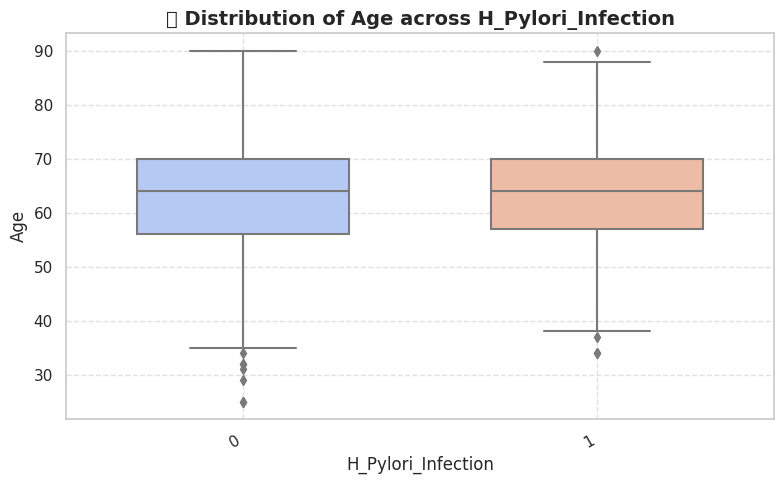


💡 Description for 'Age' vs 'H_Pylori_Infection':
• This boxplot compares the numerical feature **'Age'** across categories of **'H_Pylori_Infection'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain H_Pylori_Infection categories show higher 'Age' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


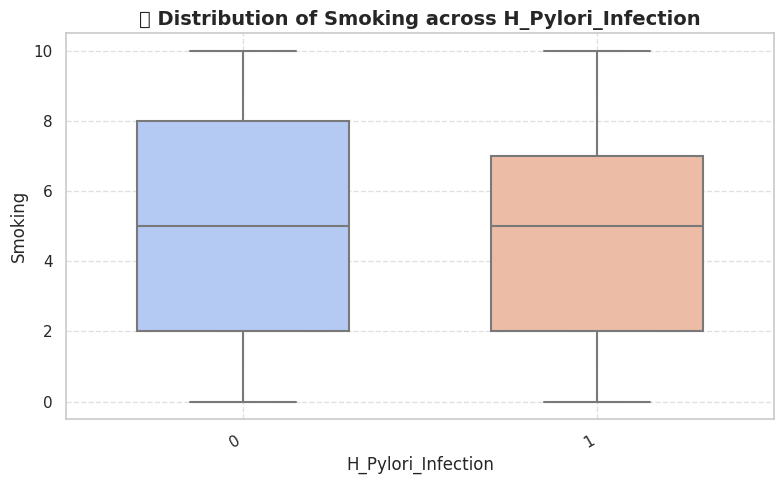


💡 Description for 'Smoking' vs 'H_Pylori_Infection':
• This boxplot compares the numerical feature **'Smoking'** across categories of **'H_Pylori_Infection'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain H_Pylori_Infection categories show higher 'Smoking' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


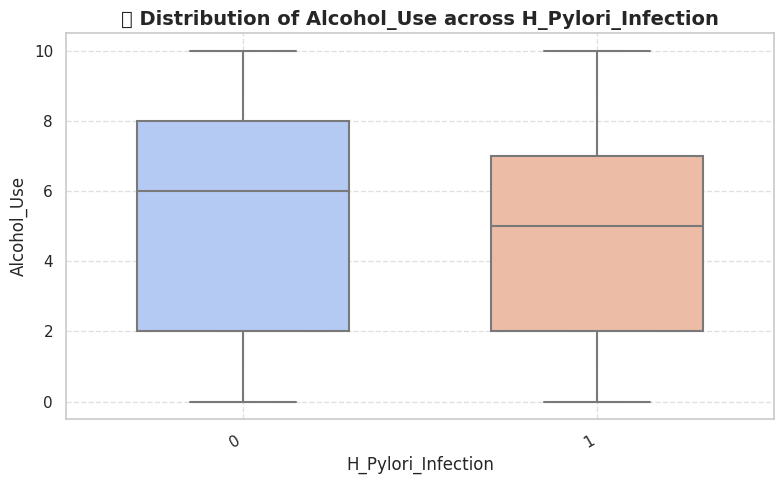


💡 Description for 'Alcohol_Use' vs 'H_Pylori_Infection':
• This boxplot compares the numerical feature **'Alcohol_Use'** across categories of **'H_Pylori_Infection'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain H_Pylori_Infection categories show higher 'Alcohol_Use' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


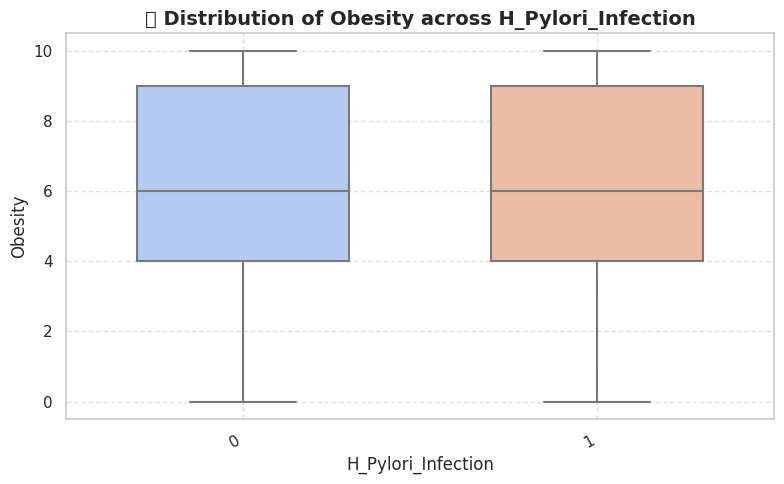


💡 Description for 'Obesity' vs 'H_Pylori_Infection':
• This boxplot compares the numerical feature **'Obesity'** across categories of **'H_Pylori_Infection'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain H_Pylori_Infection categories show higher 'Obesity' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


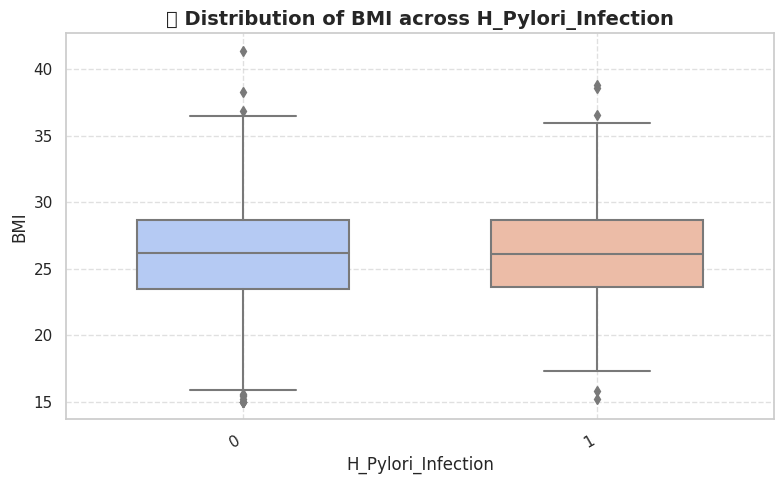


💡 Description for 'BMI' vs 'H_Pylori_Infection':
• This boxplot compares the numerical feature **'BMI'** across categories of **'H_Pylori_Infection'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain H_Pylori_Infection categories show higher 'BMI' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


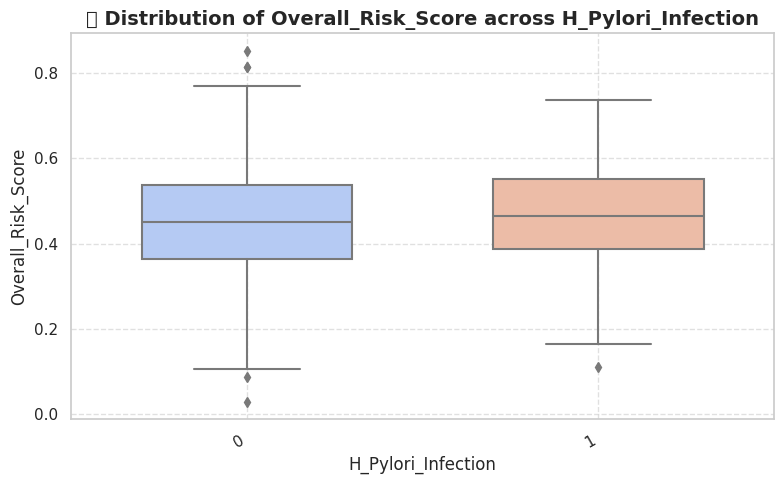


💡 Description for 'Overall_Risk_Score' vs 'H_Pylori_Infection':
• This boxplot compares the numerical feature **'Overall_Risk_Score'** across categories of **'H_Pylori_Infection'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain H_Pylori_Infection categories show higher 'Overall_Risk_Score' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


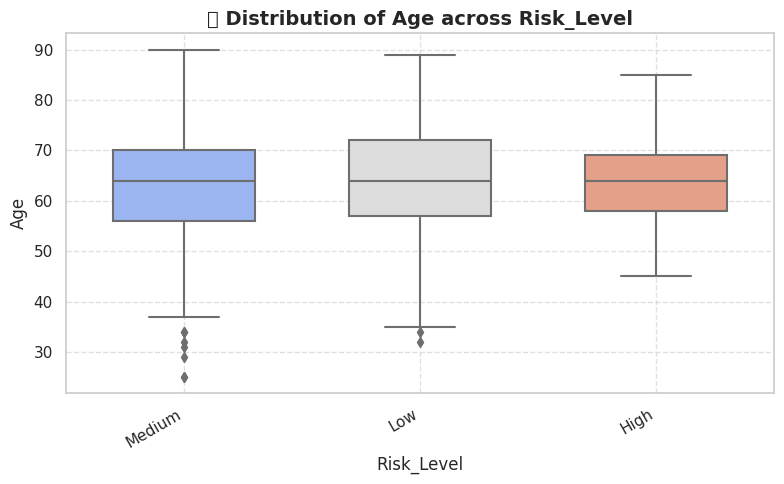


💡 Description for 'Age' vs 'Risk_Level':
• This boxplot compares the numerical feature **'Age'** across categories of **'Risk_Level'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Risk_Level categories show higher 'Age' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


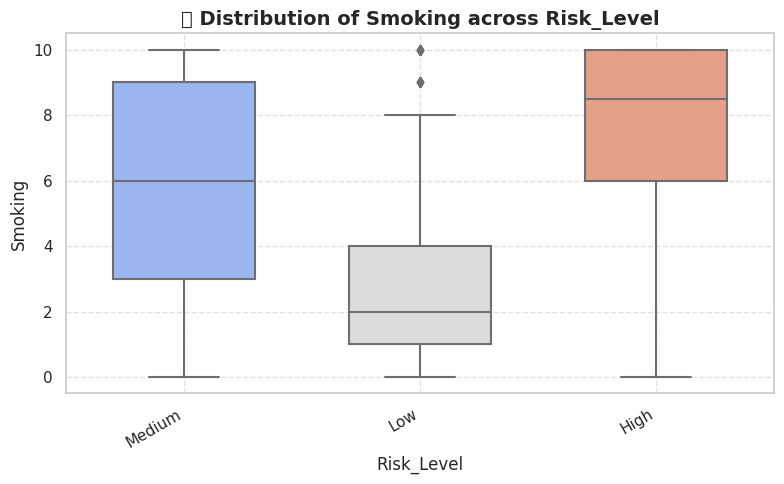


💡 Description for 'Smoking' vs 'Risk_Level':
• This boxplot compares the numerical feature **'Smoking'** across categories of **'Risk_Level'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Risk_Level categories show higher 'Smoking' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


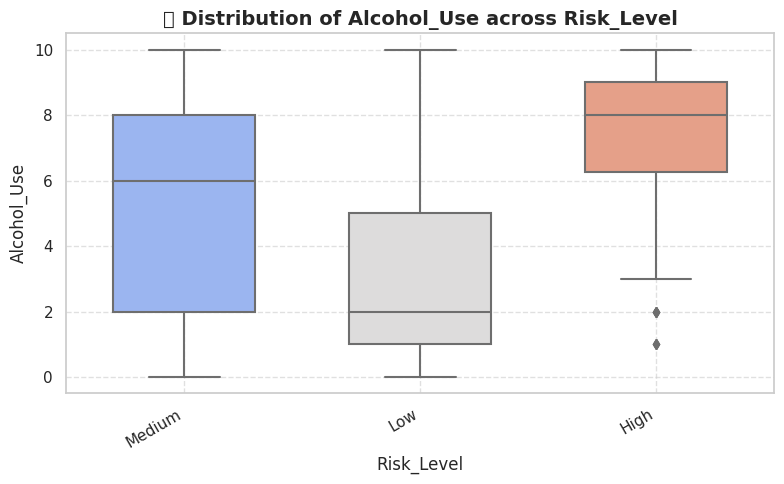


💡 Description for 'Alcohol_Use' vs 'Risk_Level':
• This boxplot compares the numerical feature **'Alcohol_Use'** across categories of **'Risk_Level'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Risk_Level categories show higher 'Alcohol_Use' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


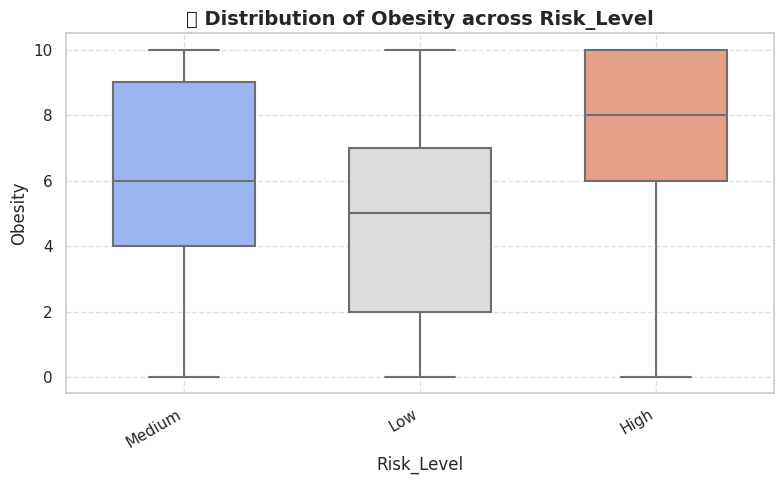


💡 Description for 'Obesity' vs 'Risk_Level':
• This boxplot compares the numerical feature **'Obesity'** across categories of **'Risk_Level'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Risk_Level categories show higher 'Obesity' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


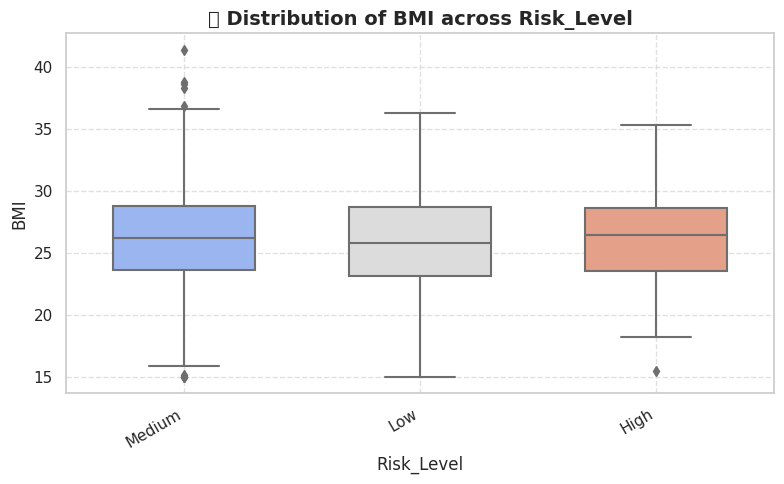


💡 Description for 'BMI' vs 'Risk_Level':
• This boxplot compares the numerical feature **'BMI'** across categories of **'Risk_Level'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Risk_Level categories show higher 'BMI' values.



/tmp/ipykernel_37/4124225929.py:40: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


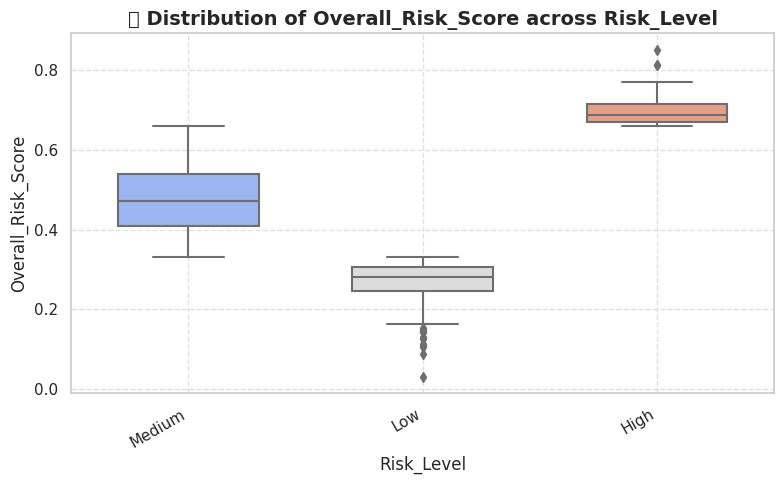


💡 Description for 'Overall_Risk_Score' vs 'Risk_Level':
• This boxplot compares the numerical feature **'Overall_Risk_Score'** across categories of **'Risk_Level'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain Risk_Level categories show higher 'Overall_Risk_Score' values.



In [ ]:
# 📦 Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 🧠 Load dataset
df = pd.read_csv("/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv")

# 🧹 Exclude ID column if exists
if 'Patient_ID' in df.columns:
    df = df.drop(columns=['Patient_ID'])
    print("🧹 'Patient_ID' column excluded.\n")

# 🎯 Define the given columns
categorical_cols = ['Cancer_Type', 'Gender', 'Family_History',
                    'BRCA_Mutation', 'H_Pylori_Infection', 'Risk_Level']

numerical_cols = ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'BMI', 'Overall_Risk_Score']

# 🎨 Set style for beautiful plots
sns.set(style="whitegrid", palette="Set2")

# 🖼 Generate boxplots for each categorical vs numerical column
for cat in categorical_cols:
    if cat not in df.columns:
        print(f"⚠️ Skipping '{cat}' - not found in dataset.")
        continue
    for num in numerical_cols:
        if num not in df.columns:
            print(f"⚠️ Skipping '{num}' - not found in dataset.")
            continue

        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x=cat, y=num, palette="coolwarm", width=0.6)
        plt.title(f"📊 Distribution of {num} across {cat}", fontsize=14, weight='bold')
        plt.xlabel(cat, fontsize=12)
        plt.ylabel(num, fontsize=12)
        plt.xticks(rotation=30, ha='right')
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.show()

        # 📝 Description for each plot
        print(f"""
💡 Description for '{num}' vs '{cat}':
• This boxplot compares the numerical feature **'{num}'** across categories of **'{cat}'**.
• The **horizontal line inside the box** shows the median value for each group.
• The **height of the box** (IQR) shows variability — taller boxes mean more spread in values.
• **Whiskers** extend to 1.5×IQR from the quartiles, and dots beyond them are **outliers**.
• This visualization helps detect group-level differences — for example, whether certain {cat} categories show higher '{num}' values.
""")

🧹 'Patient_ID' column excluded.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


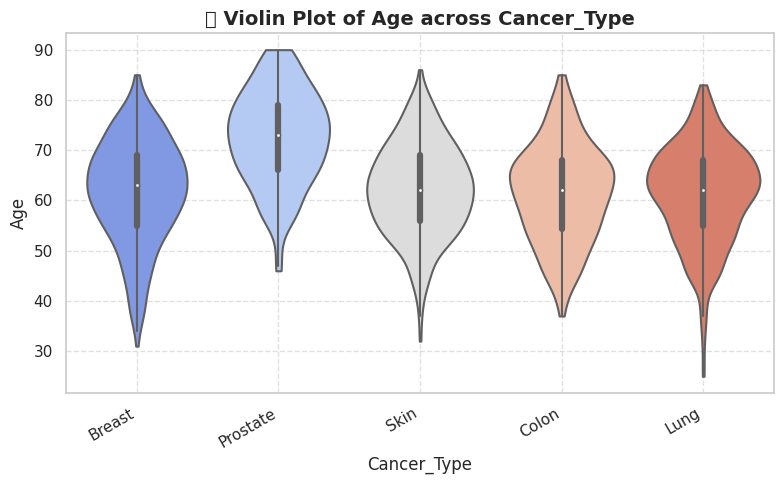


💡 Description for 'Age' vs 'Cancer_Type':
• This **violin plot** displays the **distribution shape** of 'Age' across different categories of 'Cancer_Type'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Cancer_Type' groups tend to have higher, lower, or more varied 'Age' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


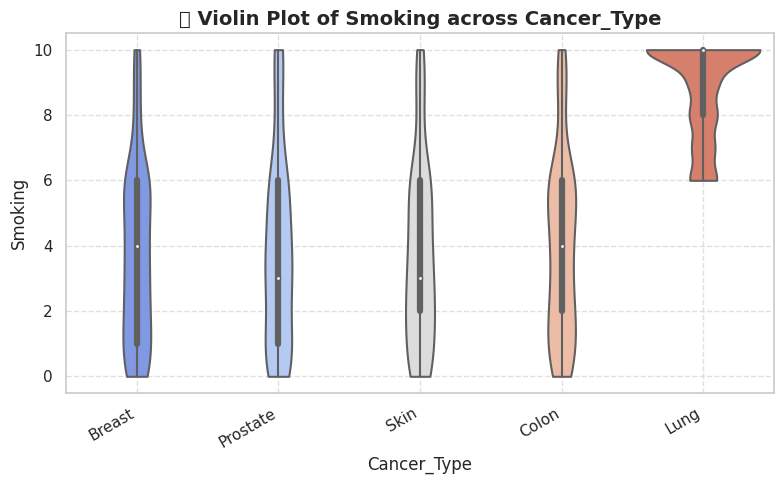


💡 Description for 'Smoking' vs 'Cancer_Type':
• This **violin plot** displays the **distribution shape** of 'Smoking' across different categories of 'Cancer_Type'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Cancer_Type' groups tend to have higher, lower, or more varied 'Smoking' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


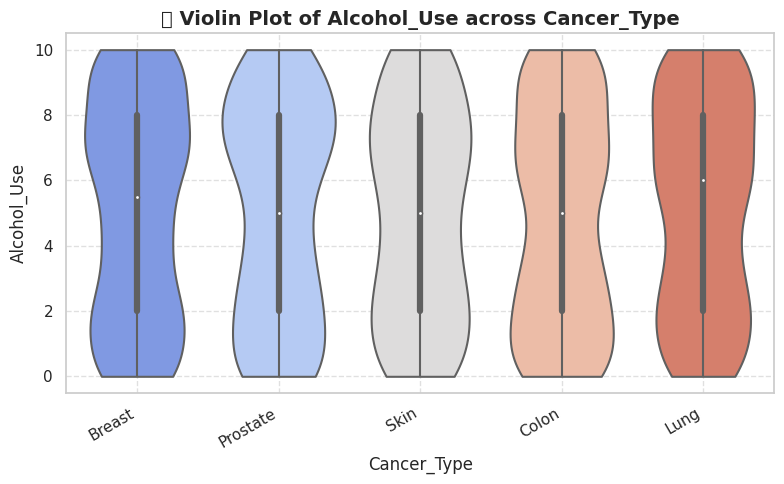


💡 Description for 'Alcohol_Use' vs 'Cancer_Type':
• This **violin plot** displays the **distribution shape** of 'Alcohol_Use' across different categories of 'Cancer_Type'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Cancer_Type' groups tend to have higher, lower, or more varied 'Alcohol_Use' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


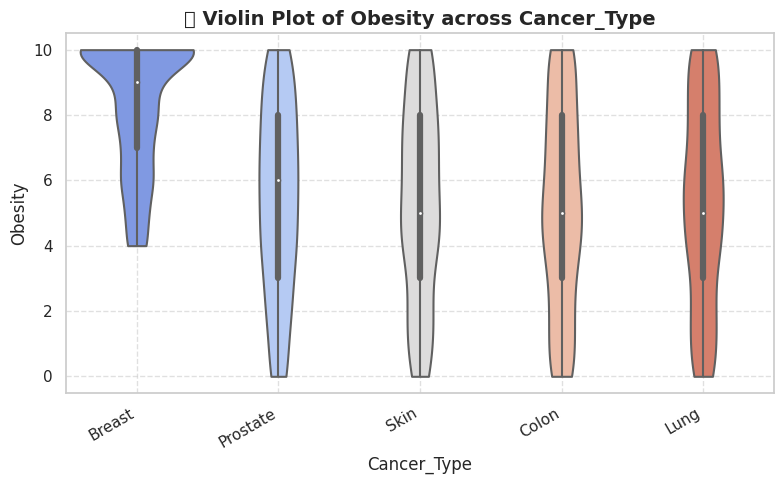


💡 Description for 'Obesity' vs 'Cancer_Type':
• This **violin plot** displays the **distribution shape** of 'Obesity' across different categories of 'Cancer_Type'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Cancer_Type' groups tend to have higher, lower, or more varied 'Obesity' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


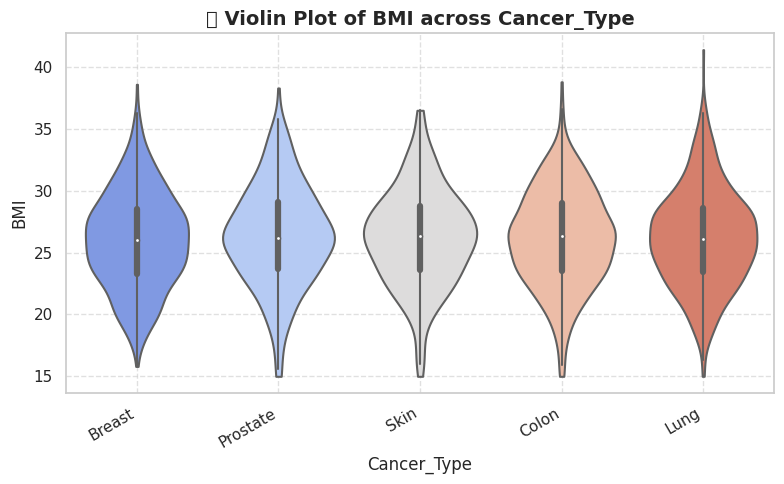


💡 Description for 'BMI' vs 'Cancer_Type':
• This **violin plot** displays the **distribution shape** of 'BMI' across different categories of 'Cancer_Type'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Cancer_Type' groups tend to have higher, lower, or more varied 'BMI' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


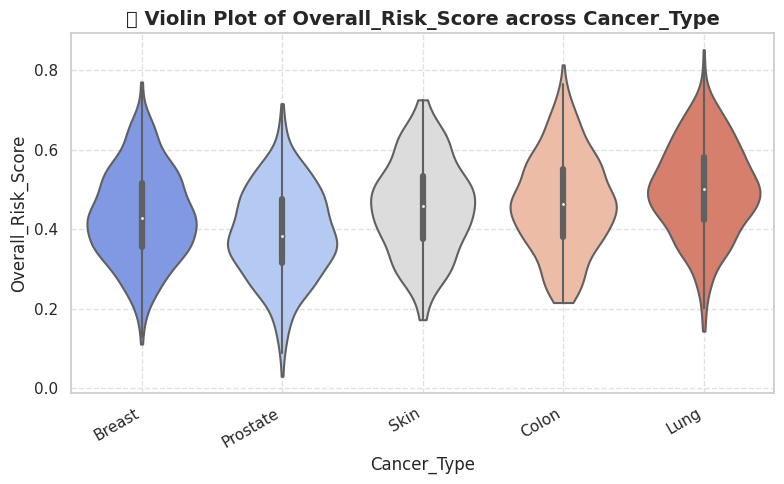


💡 Description for 'Overall_Risk_Score' vs 'Cancer_Type':
• This **violin plot** displays the **distribution shape** of 'Overall_Risk_Score' across different categories of 'Cancer_Type'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Cancer_Type' groups tend to have higher, lower, or more varied 'Overall_Risk_Score' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


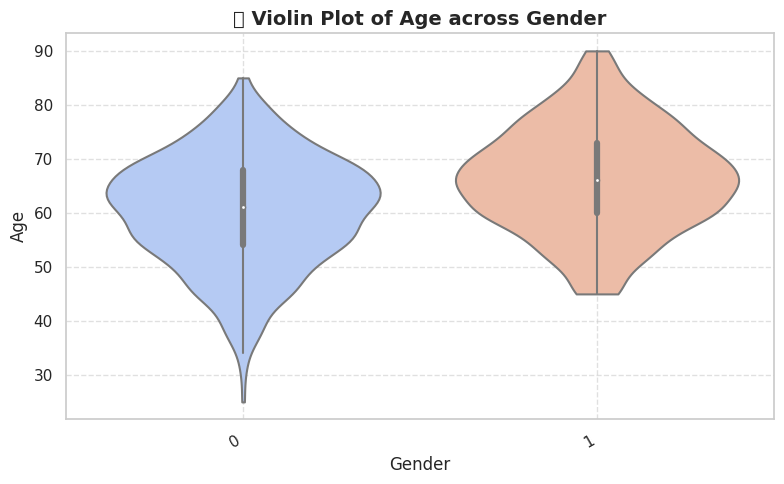


💡 Description for 'Age' vs 'Gender':
• This **violin plot** displays the **distribution shape** of 'Age' across different categories of 'Gender'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Gender' groups tend to have higher, lower, or more varied 'Age' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


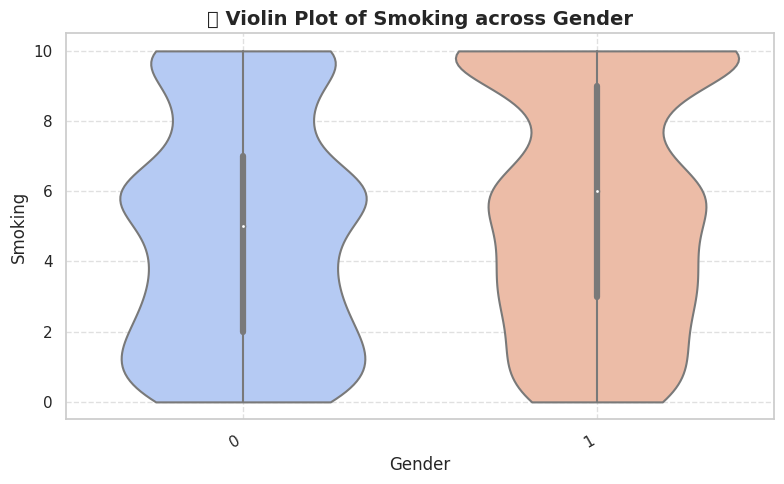


💡 Description for 'Smoking' vs 'Gender':
• This **violin plot** displays the **distribution shape** of 'Smoking' across different categories of 'Gender'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Gender' groups tend to have higher, lower, or more varied 'Smoking' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


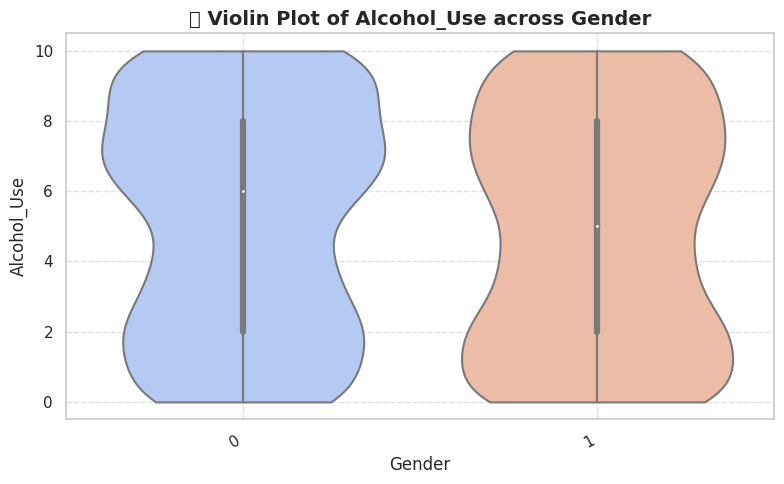


💡 Description for 'Alcohol_Use' vs 'Gender':
• This **violin plot** displays the **distribution shape** of 'Alcohol_Use' across different categories of 'Gender'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Gender' groups tend to have higher, lower, or more varied 'Alcohol_Use' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


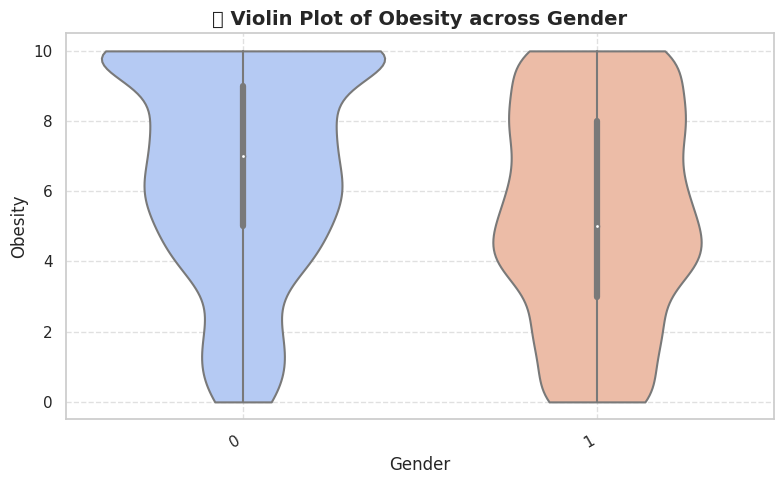


💡 Description for 'Obesity' vs 'Gender':
• This **violin plot** displays the **distribution shape** of 'Obesity' across different categories of 'Gender'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Gender' groups tend to have higher, lower, or more varied 'Obesity' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


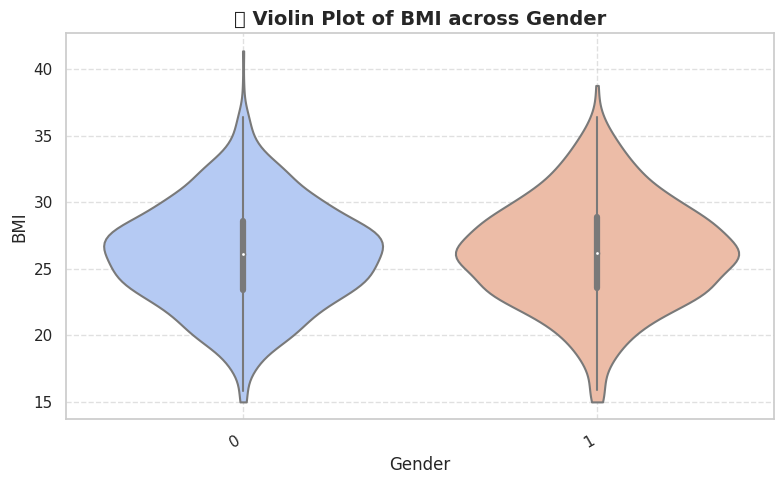


💡 Description for 'BMI' vs 'Gender':
• This **violin plot** displays the **distribution shape** of 'BMI' across different categories of 'Gender'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Gender' groups tend to have higher, lower, or more varied 'BMI' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


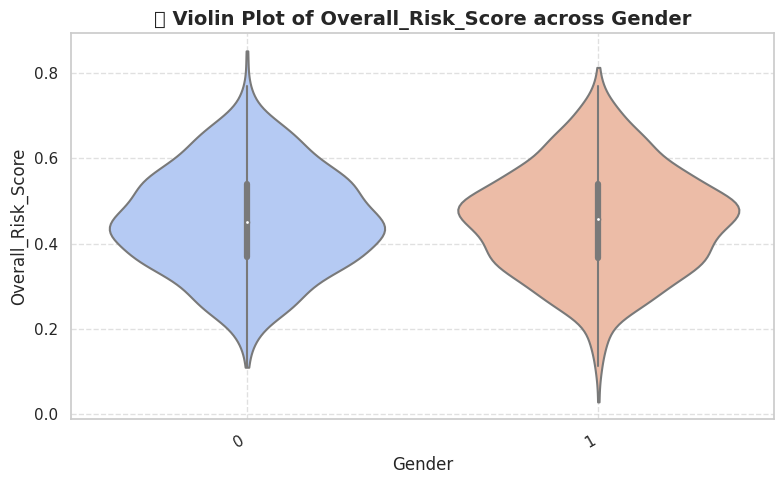


💡 Description for 'Overall_Risk_Score' vs 'Gender':
• This **violin plot** displays the **distribution shape** of 'Overall_Risk_Score' across different categories of 'Gender'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Gender' groups tend to have higher, lower, or more varied 'Overall_Risk_Score' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


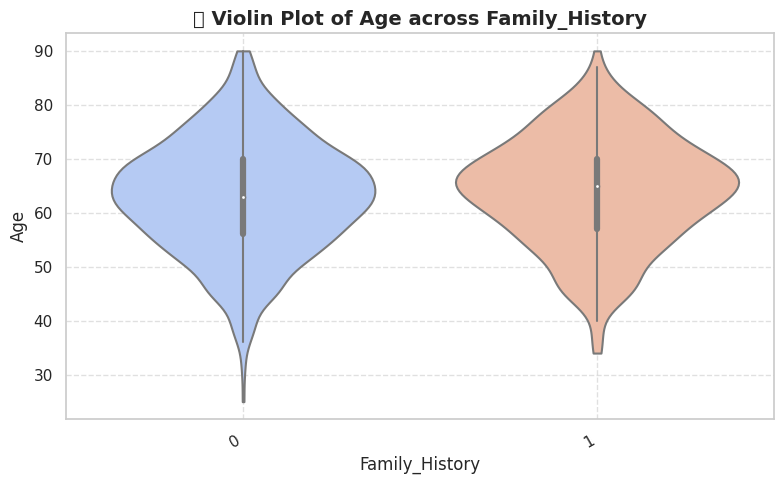


💡 Description for 'Age' vs 'Family_History':
• This **violin plot** displays the **distribution shape** of 'Age' across different categories of 'Family_History'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Family_History' groups tend to have higher, lower, or more varied 'Age' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


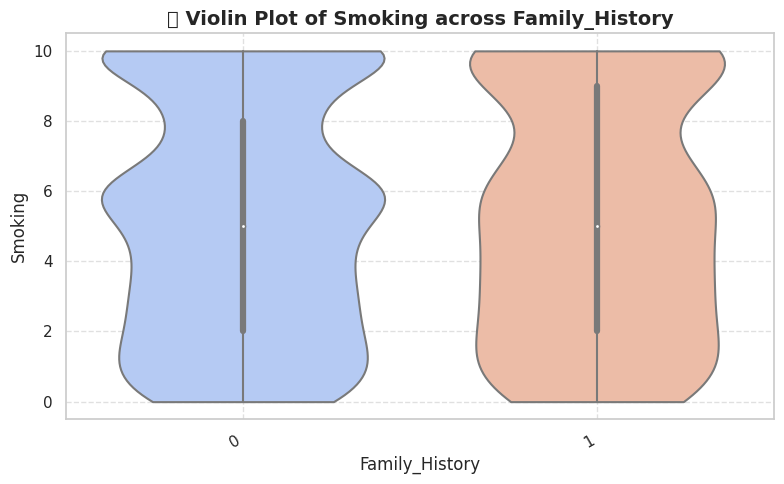


💡 Description for 'Smoking' vs 'Family_History':
• This **violin plot** displays the **distribution shape** of 'Smoking' across different categories of 'Family_History'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Family_History' groups tend to have higher, lower, or more varied 'Smoking' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


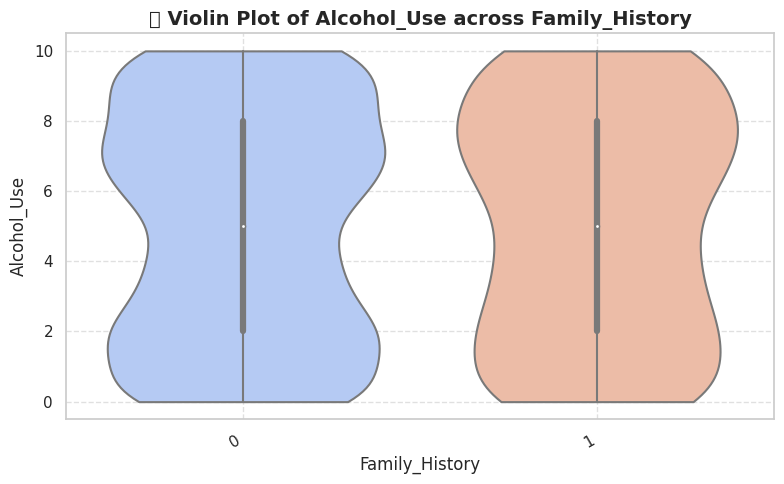


💡 Description for 'Alcohol_Use' vs 'Family_History':
• This **violin plot** displays the **distribution shape** of 'Alcohol_Use' across different categories of 'Family_History'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Family_History' groups tend to have higher, lower, or more varied 'Alcohol_Use' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


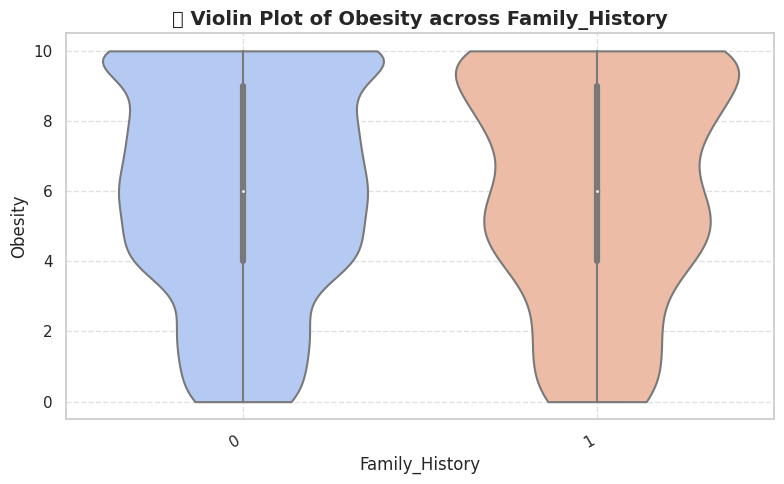


💡 Description for 'Obesity' vs 'Family_History':
• This **violin plot** displays the **distribution shape** of 'Obesity' across different categories of 'Family_History'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Family_History' groups tend to have higher, lower, or more varied 'Obesity' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


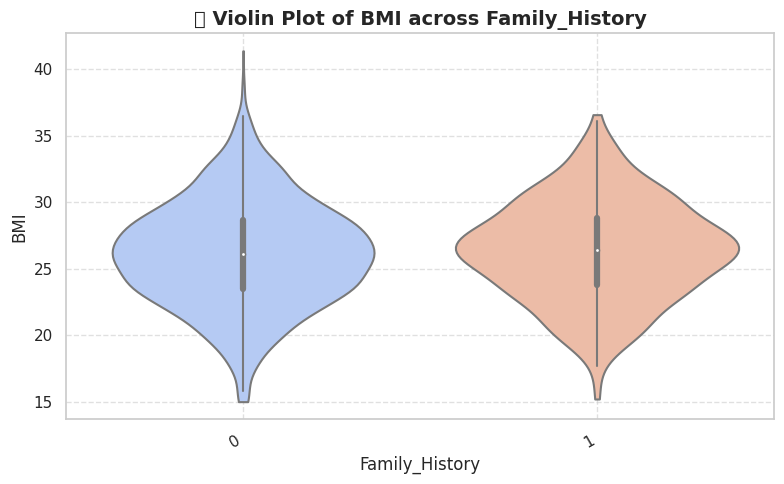


💡 Description for 'BMI' vs 'Family_History':
• This **violin plot** displays the **distribution shape** of 'BMI' across different categories of 'Family_History'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Family_History' groups tend to have higher, lower, or more varied 'BMI' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


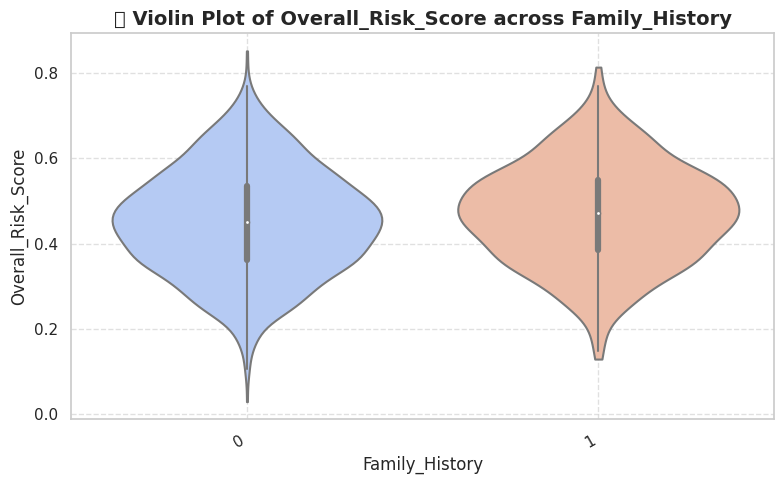


💡 Description for 'Overall_Risk_Score' vs 'Family_History':
• This **violin plot** displays the **distribution shape** of 'Overall_Risk_Score' across different categories of 'Family_History'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Family_History' groups tend to have higher, lower, or more varied 'Overall_Risk_Score' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


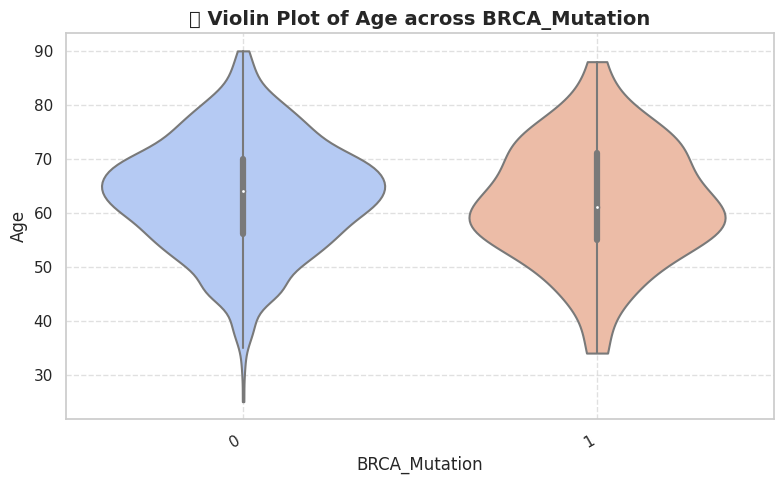


💡 Description for 'Age' vs 'BRCA_Mutation':
• This **violin plot** displays the **distribution shape** of 'Age' across different categories of 'BRCA_Mutation'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'BRCA_Mutation' groups tend to have higher, lower, or more varied 'Age' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


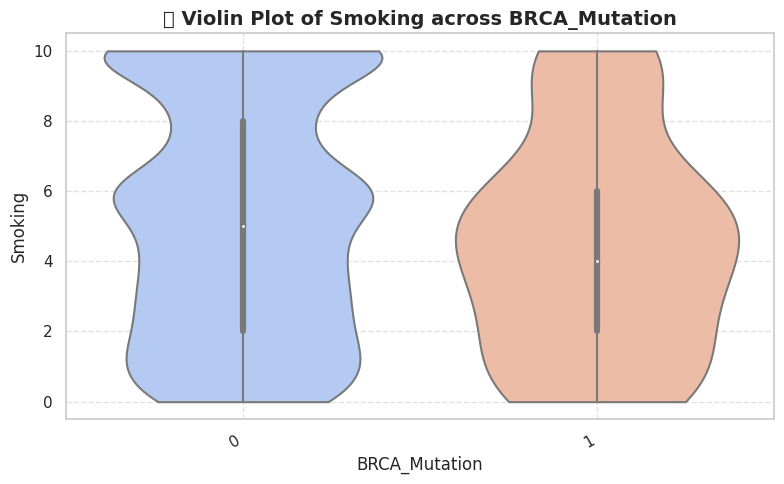


💡 Description for 'Smoking' vs 'BRCA_Mutation':
• This **violin plot** displays the **distribution shape** of 'Smoking' across different categories of 'BRCA_Mutation'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'BRCA_Mutation' groups tend to have higher, lower, or more varied 'Smoking' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


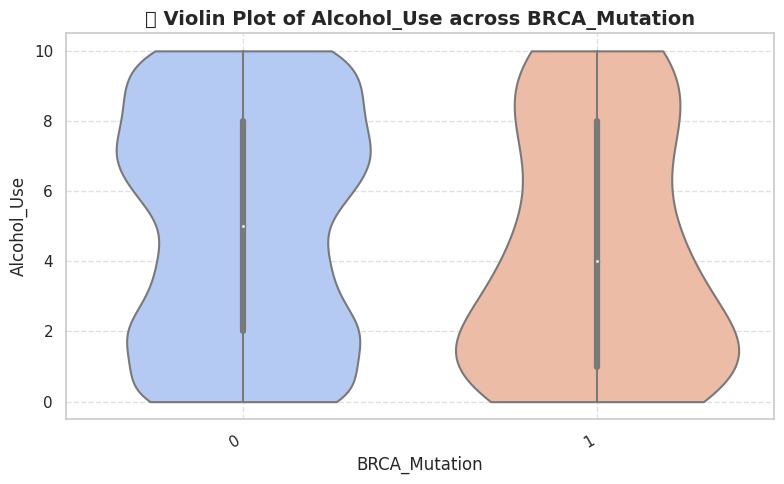


💡 Description for 'Alcohol_Use' vs 'BRCA_Mutation':
• This **violin plot** displays the **distribution shape** of 'Alcohol_Use' across different categories of 'BRCA_Mutation'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'BRCA_Mutation' groups tend to have higher, lower, or more varied 'Alcohol_Use' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


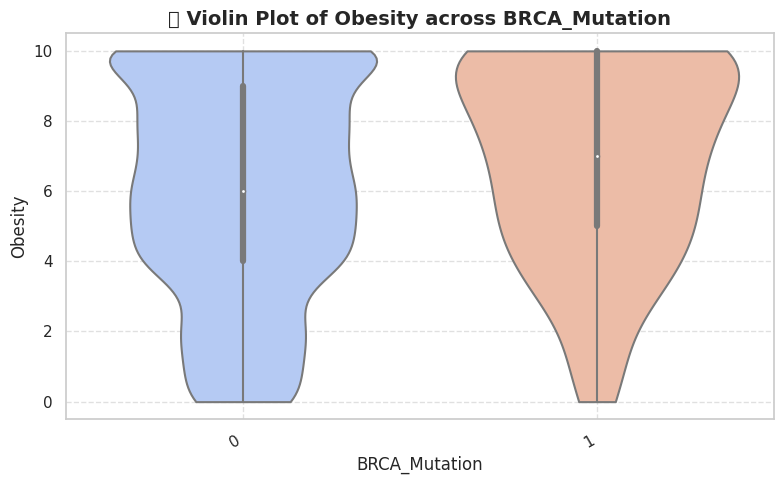


💡 Description for 'Obesity' vs 'BRCA_Mutation':
• This **violin plot** displays the **distribution shape** of 'Obesity' across different categories of 'BRCA_Mutation'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'BRCA_Mutation' groups tend to have higher, lower, or more varied 'Obesity' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


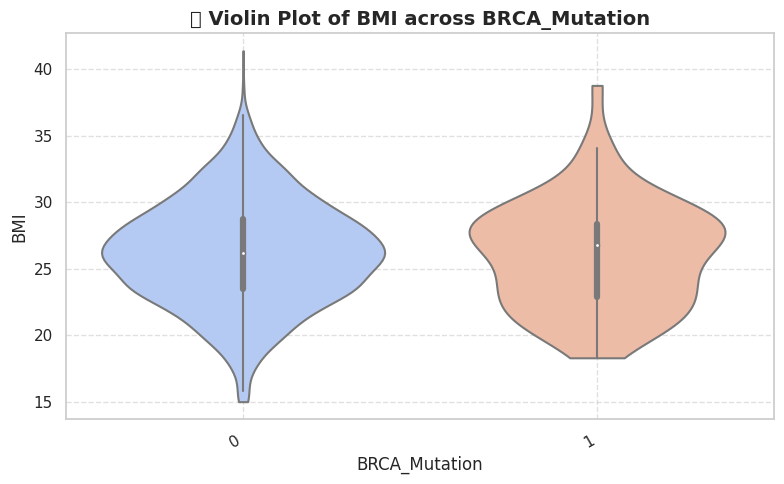


💡 Description for 'BMI' vs 'BRCA_Mutation':
• This **violin plot** displays the **distribution shape** of 'BMI' across different categories of 'BRCA_Mutation'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'BRCA_Mutation' groups tend to have higher, lower, or more varied 'BMI' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


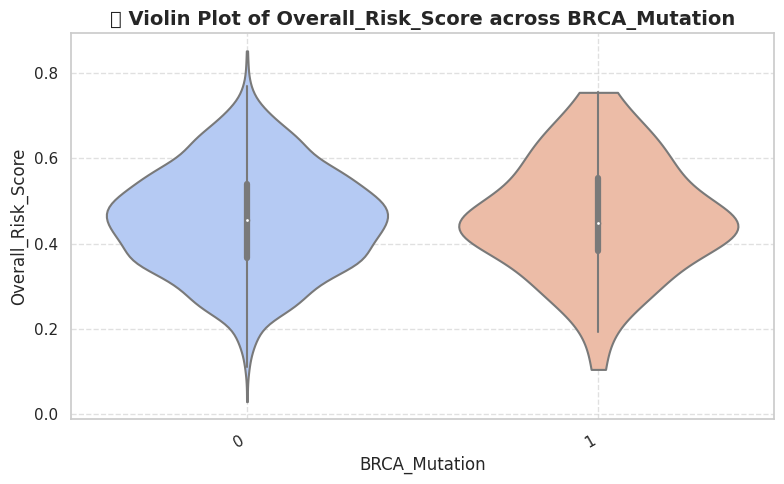


💡 Description for 'Overall_Risk_Score' vs 'BRCA_Mutation':
• This **violin plot** displays the **distribution shape** of 'Overall_Risk_Score' across different categories of 'BRCA_Mutation'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'BRCA_Mutation' groups tend to have higher, lower, or more varied 'Overall_Risk_Score' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


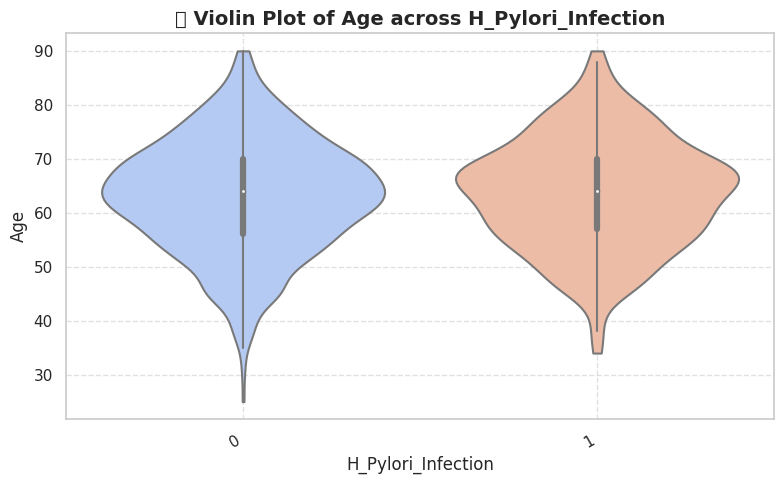

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Age' vs 'H_Pylori_Infection':
• This **violin plot** displays the **distribution shape** of 'Age' across different categories of 'H_Pylori_Infection'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'H_Pylori_Infection' groups tend to have higher, lower, or more varied 'Age' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


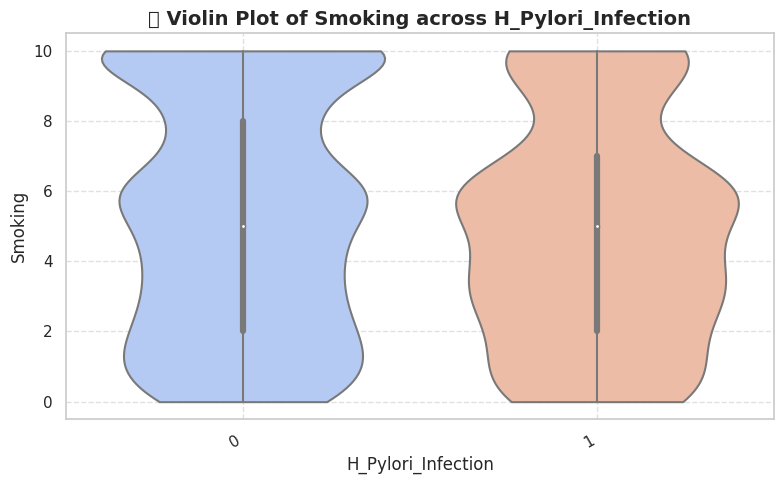

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Smoking' vs 'H_Pylori_Infection':
• This **violin plot** displays the **distribution shape** of 'Smoking' across different categories of 'H_Pylori_Infection'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'H_Pylori_Infection' groups tend to have higher, lower, or more varied 'Smoking' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


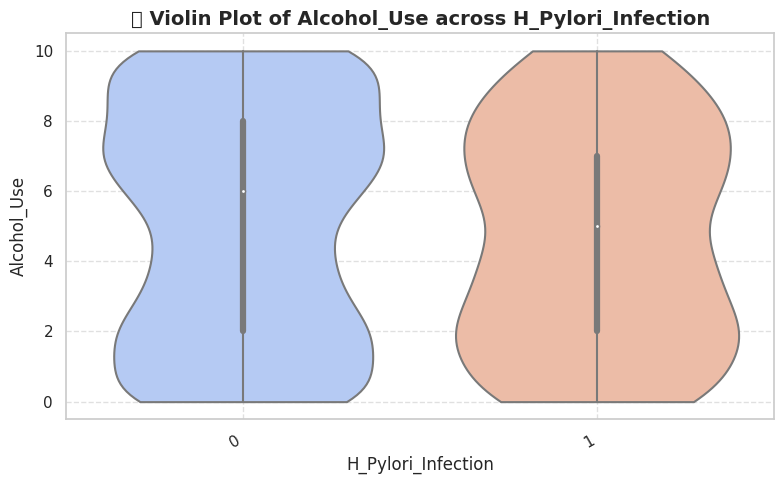

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Alcohol_Use' vs 'H_Pylori_Infection':
• This **violin plot** displays the **distribution shape** of 'Alcohol_Use' across different categories of 'H_Pylori_Infection'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'H_Pylori_Infection' groups tend to have higher, lower, or more varied 'Alcohol_Use' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


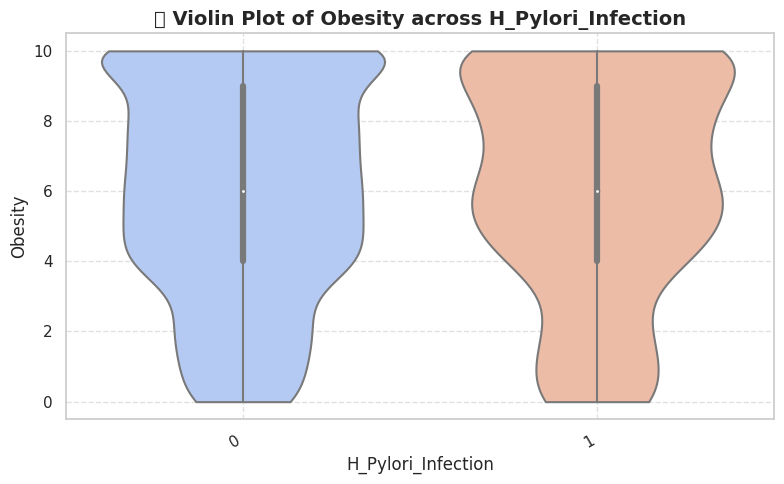

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Obesity' vs 'H_Pylori_Infection':
• This **violin plot** displays the **distribution shape** of 'Obesity' across different categories of 'H_Pylori_Infection'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'H_Pylori_Infection' groups tend to have higher, lower, or more varied 'Obesity' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


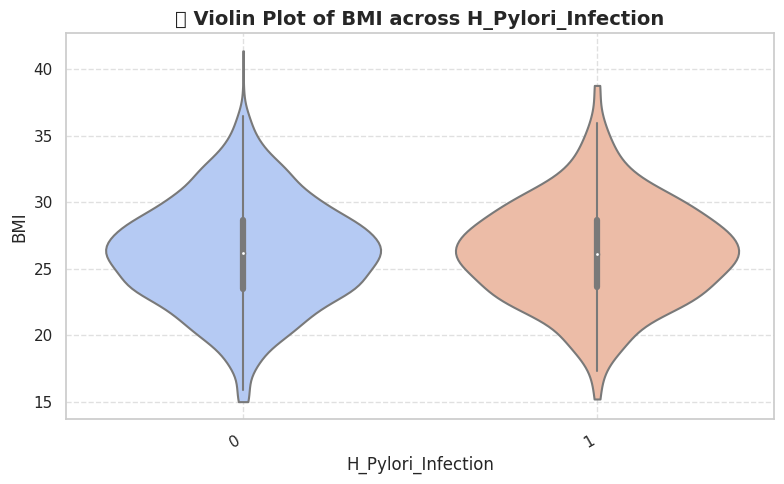

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'BMI' vs 'H_Pylori_Infection':
• This **violin plot** displays the **distribution shape** of 'BMI' across different categories of 'H_Pylori_Infection'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'H_Pylori_Infection' groups tend to have higher, lower, or more varied 'BMI' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


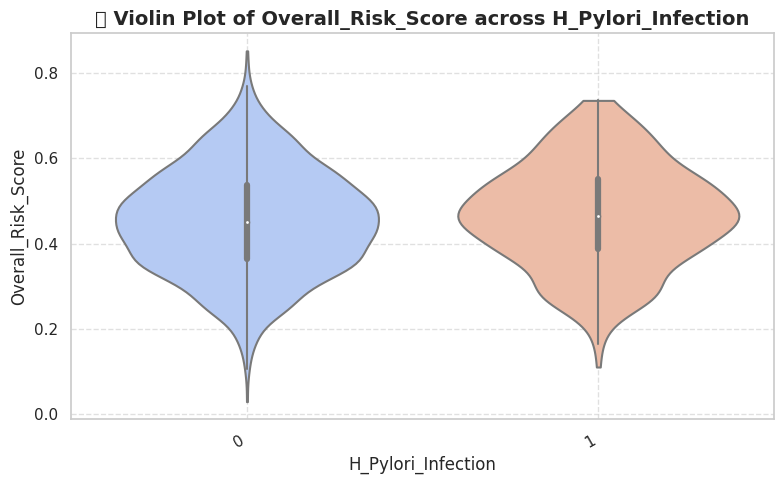

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Overall_Risk_Score' vs 'H_Pylori_Infection':
• This **violin plot** displays the **distribution shape** of 'Overall_Risk_Score' across different categories of 'H_Pylori_Infection'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'H_Pylori_Infection' groups tend to have higher, lower, or more varied 'Overall_Risk_Score' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


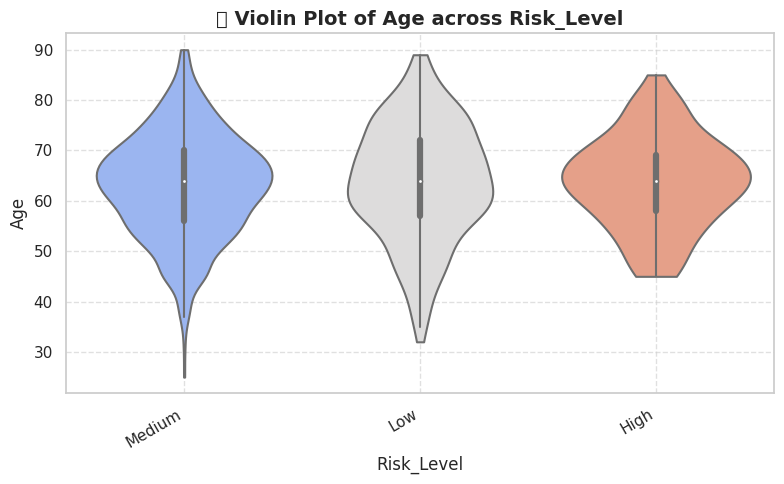

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Age' vs 'Risk_Level':
• This **violin plot** displays the **distribution shape** of 'Age' across different categories of 'Risk_Level'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Risk_Level' groups tend to have higher, lower, or more varied 'Age' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


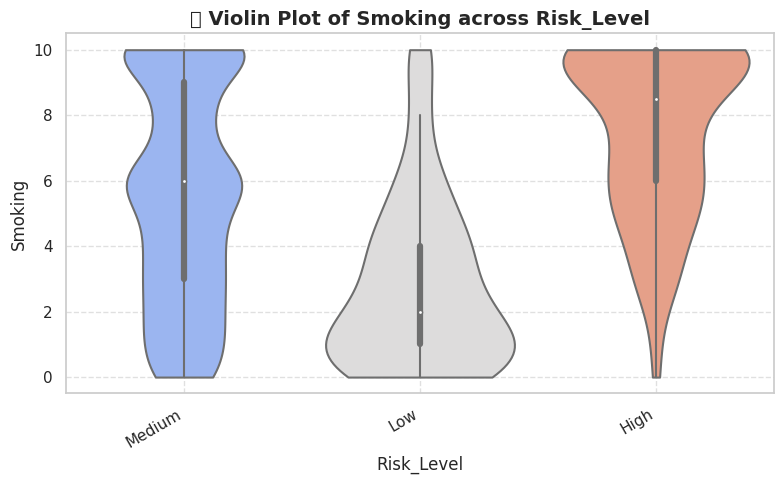

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Smoking' vs 'Risk_Level':
• This **violin plot** displays the **distribution shape** of 'Smoking' across different categories of 'Risk_Level'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Risk_Level' groups tend to have higher, lower, or more varied 'Smoking' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


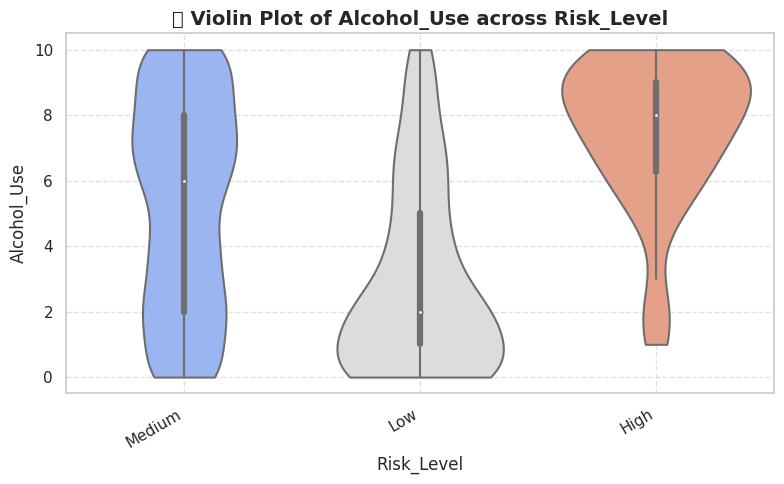

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Alcohol_Use' vs 'Risk_Level':
• This **violin plot** displays the **distribution shape** of 'Alcohol_Use' across different categories of 'Risk_Level'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Risk_Level' groups tend to have higher, lower, or more varied 'Alcohol_Use' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


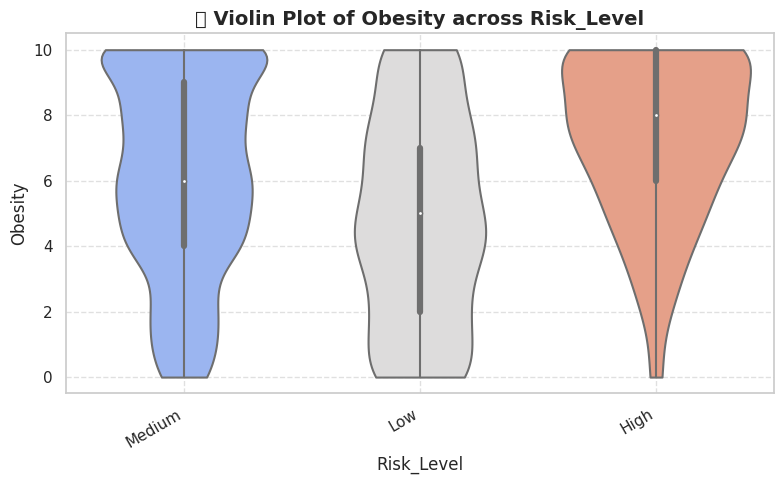

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'Obesity' vs 'Risk_Level':
• This **violin plot** displays the **distribution shape** of 'Obesity' across different categories of 'Risk_Level'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Risk_Level' groups tend to have higher, lower, or more varied 'Obesity' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


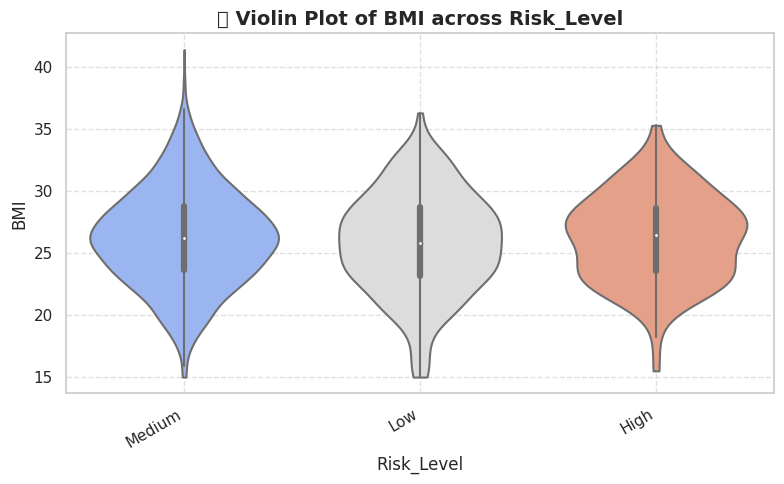

/tmp/ipykernel_37/598671659.py:40: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  plt.tight_layout()



💡 Description for 'BMI' vs 'Risk_Level':
• This **violin plot** displays the **distribution shape** of 'BMI' across different categories of 'Risk_Level'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Risk_Level' groups tend to have higher, lower, or more varied 'BMI' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


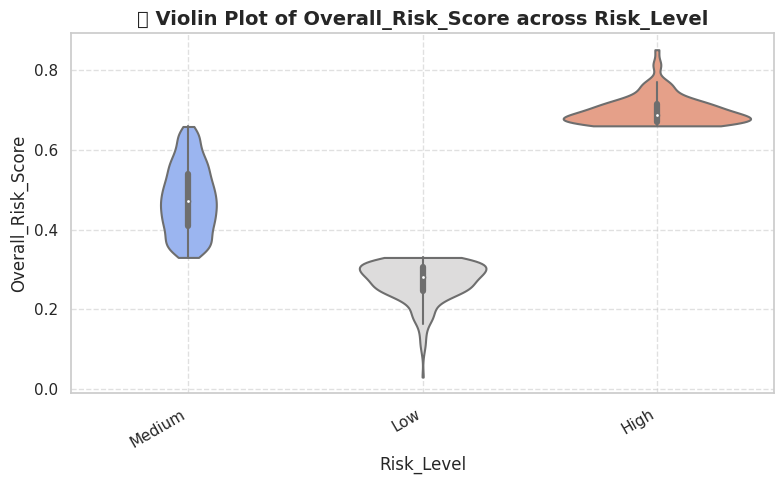


💡 Description for 'Overall_Risk_Score' vs 'Risk_Level':
• This **violin plot** displays the **distribution shape** of 'Overall_Risk_Score' across different categories of 'Risk_Level'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific 'Risk_Level' groups tend to have higher, lower, or more varied 'Overall_Risk_Score' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.



In [ ]:
# 📦 Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 🧠 Load dataset
df = pd.read_csv("/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv")

# 🧹 Exclude Patient_ID if present
if 'Patient_ID' in df.columns:
    df = df.drop(columns=['Patient_ID'])
    print("🧹 'Patient_ID' column excluded.\n")

# 🎯 Define the columns to analyze
categorical_cols = ['Cancer_Type', 'Gender', 'Family_History',
                    'BRCA_Mutation', 'H_Pylori_Infection', 'Risk_Level']

numerical_cols = ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'BMI', 'Overall_Risk_Score']

# 🎨 Set Seaborn style
sns.set(style="whitegrid", palette="muted")

# 🎻 Generate violin plots for all categorical vs numerical pairs
for cat in categorical_cols:
    if cat not in df.columns:
        print(f"⚠️ Skipping '{cat}' - not found in dataset.")
        continue
    for num in numerical_cols:
        if num not in df.columns:
            print(f"⚠️ Skipping '{num}' - not found in dataset.")
            continue

        plt.figure(figsize=(8, 5))
        sns.violinplot(data=df, x=cat, y=num, inner="box", palette="coolwarm", cut=0)
        plt.title(f"🎻 Violin Plot of {num} across {cat}", fontsize=14, weight='bold')
        plt.xlabel(cat, fontsize=12)
        plt.ylabel(num, fontsize=12)
        plt.xticks(rotation=30, ha='right')
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.show()

        # 📝 Detailed interpretation
        print(f"""
💡 Description for '{num}' vs '{cat}':
• This **violin plot** displays the **distribution shape** of '{num}' across different categories of '{cat}'.
• The **width of each violin** represents the **density** of data points — wider areas mean more observations.
• The **white dot** shows the **median**, and the **thick black bar** inside represents the **interquartile range (IQR)**.
• Unlike boxplots, violins show **multi-modal patterns** (if the data has multiple peaks).
• This helps detect whether specific '{cat}' groups tend to have higher, lower, or more varied '{num}' values.
• For example, you can observe if certain cancer types or genders have higher overall risk scores or BMI distributions.
""")

🧹 'Patient_ID' column excluded.



/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

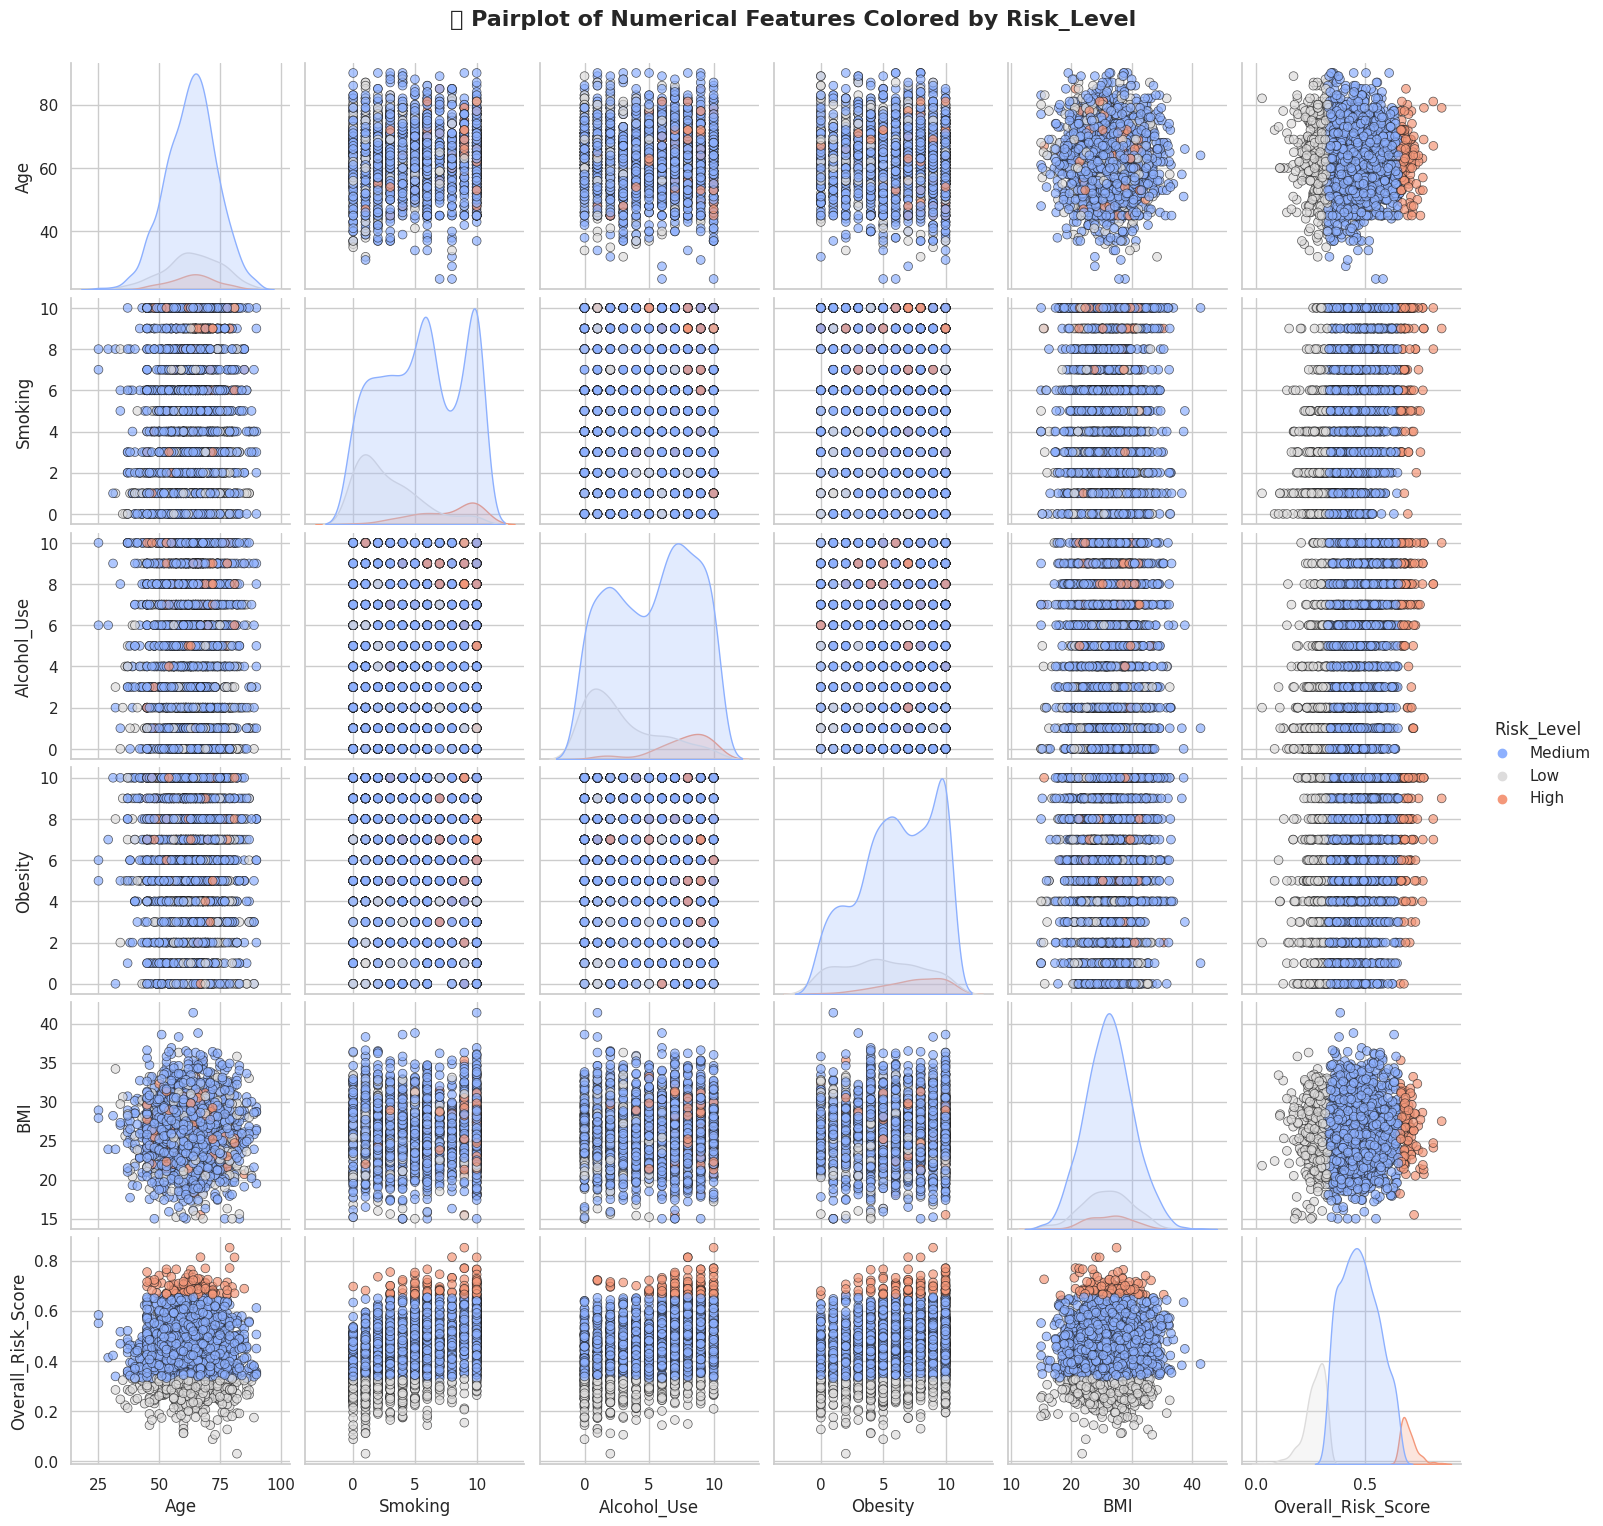


💡 **Description: Pairplot of Numerical Features with 'Risk_Level' as Target**

• Each **scatterplot** (off-diagonal cell) shows how two numerical features (e.g., 'Age' vs 'BMI') relate to each other, 
  with points colored by **'Risk_Level'** levels (e.g., Low, Medium, High Risk).

• The **diagonal plots** show **feature distributions** (KDE curves) for each 'Risk_Level' class.

• Helps identify:
  - 🔹 **Correlation patterns** (linear/non-linear relationships)
  - 🔹 **Class separability** between different risk levels
  - 🔹 **Clusters or trends** among high/low-risk patients
  - 🔹 **Potential multicollinearity** between features

• For example:
  - If 'Overall_Risk_Score' and 'BMI' cluster distinctly by color, they may be strong predictors of 'Risk_Level'.
  - If 'Age' overlaps heavily across risk levels, it might have weaker discriminative power.

✅ Use this visualization to quickly sense which numerical variables are most effective for predicting 'Risk_Level'.



In [ ]:
# 📦 Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 🧠 Load the dataset
df = pd.read_csv("/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv")

# 🧹 Exclude 'Patient_ID' if present
if 'Patient_ID' in df.columns:
    df = df.drop(columns=['Patient_ID'])
    print("🧹 'Patient_ID' column excluded.\n")

# 🎯 Define the target and select numerical columns
target_col = 'Risk_Level'
numerical_cols = ['Age', 'Smoking', 'Alcohol_Use', 'Obesity', 'BMI', 'Overall_Risk_Score']

# ✅ Check if target column exists
if target_col not in df.columns:
    raise ValueError(f"❌ Target column '{target_col}' not found in dataset!")

# 🎨 Set visual style
sns.set(style="whitegrid", palette="Set2")

# 📈 Create pairplot
pairplot = sns.pairplot(
    df,
    vars=numerical_cols,
    hue=target_col,
    palette="coolwarm",
    diag_kind="kde",
    plot_kws={'alpha': 0.7, 's': 40, 'edgecolor': 'k'},
    diag_kws={'fill': True}
)
pairplot.fig.suptitle("🔍 Pairplot of Numerical Features Colored by Risk_Level", fontsize=16, weight='bold', y=1.02)
plt.show()

# 📝 Detailed Description
print(f"""
💡 **Description: Pairplot of Numerical Features with 'Risk_Level' as Target**

• Each **scatterplot** (off-diagonal cell) shows how two numerical features (e.g., 'Age' vs 'BMI') relate to each other,
  with points colored by **'{target_col}'** levels (e.g., Low, Medium, High Risk).

• The **diagonal plots** show **feature distributions** (KDE curves) for each '{target_col}' class.

• Helps identify:
  - 🔹 **Correlation patterns** (linear/non-linear relationships)
  - 🔹 **Class separability** between different risk levels
  - 🔹 **Clusters or trends** among high/low-risk patients
  - 🔹 **Potential multicollinearity** between features

• For example:
  - If 'Overall_Risk_Score' and 'BMI' cluster distinctly by color, they may be strong predictors of '{target_col}'.
  - If 'Age' overlaps heavily across risk levels, it might have weaker discriminative power.

✅ Use this visualization to quickly sense which numerical variables are most effective for predicting 'Risk_Level'.
""")

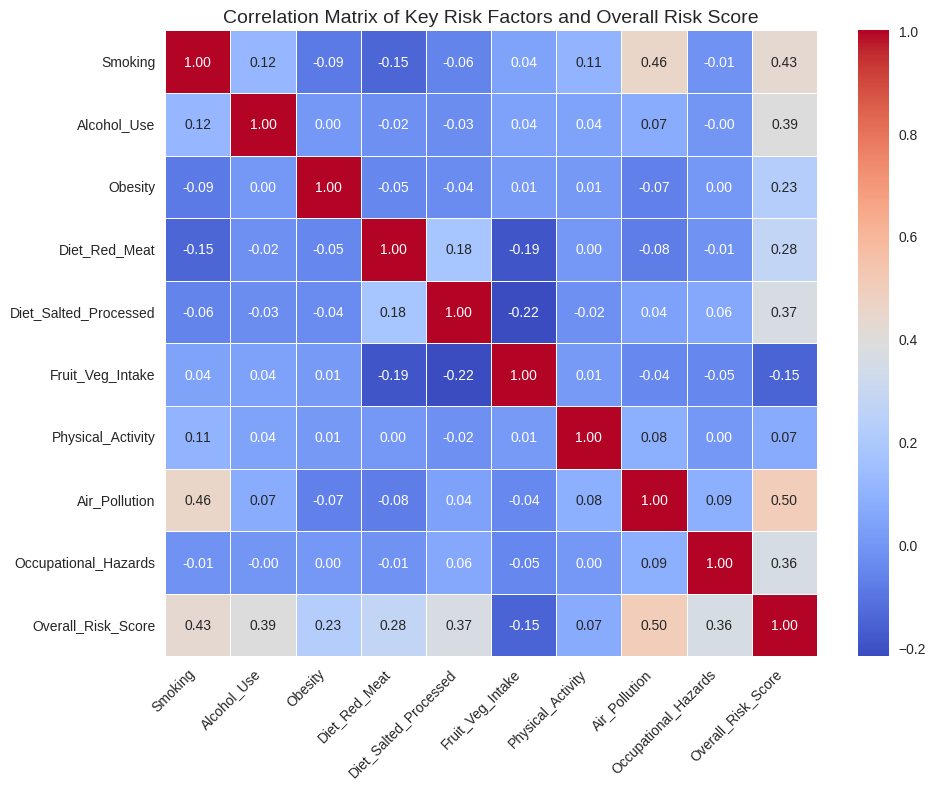

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')

# Select the numerical risk factors and the Overall_Risk_Score
risk_factor_cols = [
    'Smoking', 'Alcohol_Use', 'Obesity', 'Diet_Red_Meat', 'Diet_Salted_Processed',
    'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution', 'Occupational_Hazards',
    'Overall_Risk_Score'
]
corr_df = df[risk_factor_cols]

# Calculate the correlation matrix
correlation_matrix = corr_df.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True, # Show the correlation values on the heatmap
    cmap='coolwarm', # Color map to use (coolwarm is good for showing positive/negative)
    fmt=".2f", # Format annotations to two decimal places
    linewidths=.5
)
plt.title('Correlation Matrix of Key Risk Factors and Overall Risk Score', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [1]:
# Dharnish (ENTIRE CELL)
!pip install xgboost
!pip install lightgbm
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.5 MB/s eta 0:00:00


🧹 'Patient_ID' column excluded.

Overall_Risk_Score also dropped for more accurate assessment
✅ Logistic Regression trained successfully | Accuracy: 0.8960
✅ Decision Tree trained successfully | Accuracy: 0.7320
✅ Random Forest trained successfully | Accuracy: 0.8480
✅ Extra Trees trained successfully | Accuracy: 0.8420
✅ AdaBoost trained successfully | Accuracy: 0.8820
✅ Gradient Boosting trained successfully | Accuracy: 0.8680
✅ SVM (RBF Kernel) trained successfully | Accuracy: 0.8760


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [21:52:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


✅ XGBoost trained successfully | Accuracy: 0.8700
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000340 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 380
[LightGBM] [Info] Number of data points in the train set: 1500, number of used features: 21
[LightGBM] [Info] Start training from score -2.906501
[LightGBM] [Info] Start training from score -1.807889
[LightGBM] [Info] Start training from score -0.246753
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


✅ LightGBM trained successfully | Accuracy: 0.8740
✅ CatBoost trained successfully | Accuracy: 0.8840


/tmp/ipykernel_9638/1925192658.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results_df, palette="coolwarm")
/tmp/ipykernel_9638/1925192658.py:87: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


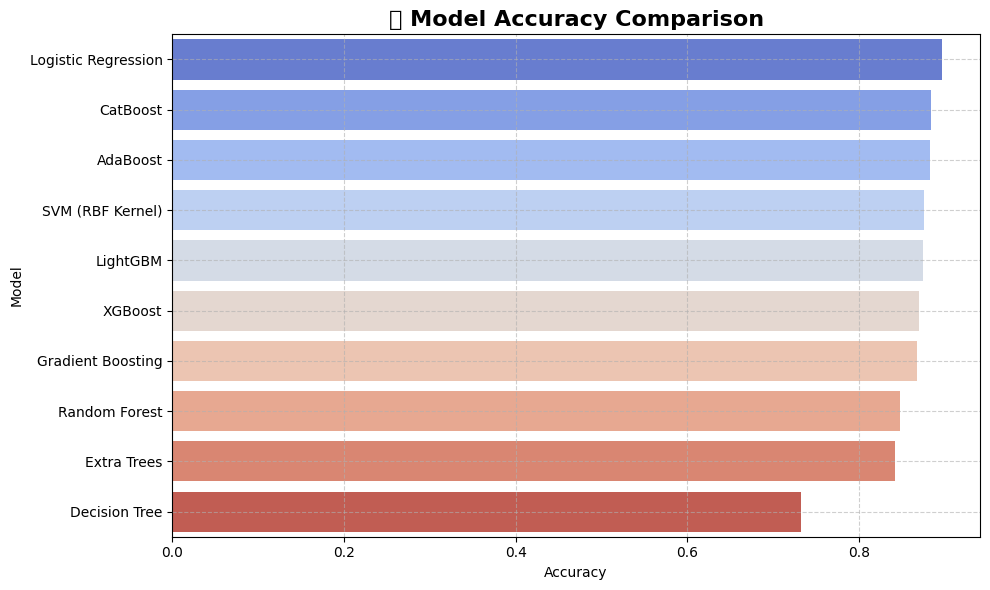

📊 Model Performance Summary:
                  Model  Accuracy
0  Logistic Regression     0.896
9             CatBoost     0.884
4             AdaBoost     0.882
6     SVM (RBF Kernel)     0.876
8             LightGBM     0.874
7              XGBoost     0.870
5    Gradient Boosting     0.868
2        Random Forest     0.848
3          Extra Trees     0.842
1        Decision Tree     0.732


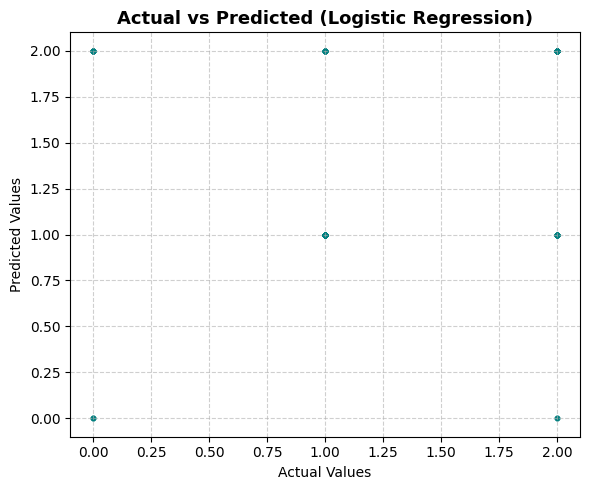


💡 Description for Logistic Regression (Actual vs Predicted):
- Each dot represents a test sample comparing true vs predicted labels.
- Points near the diagonal line imply high prediction accuracy.
- Deviations indicate misclassifications or model bias.
- Useful to visually check how closely the model generalizes test data.



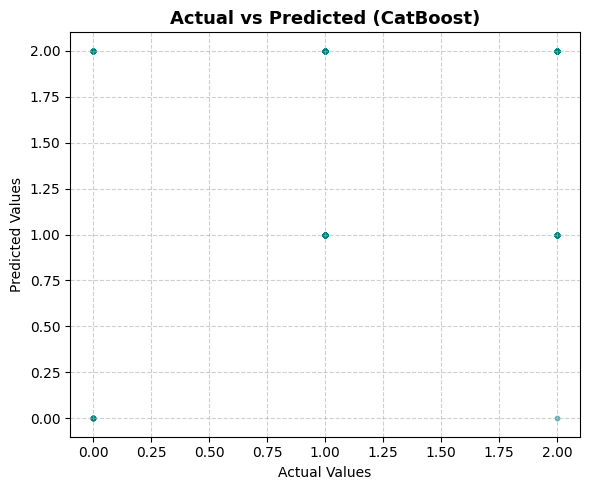


💡 Description for CatBoost (Actual vs Predicted):
- Each dot represents a test sample comparing true vs predicted labels.
- Points near the diagonal line imply high prediction accuracy.
- Deviations indicate misclassifications or model bias.
- Useful to visually check how closely the model generalizes test data.



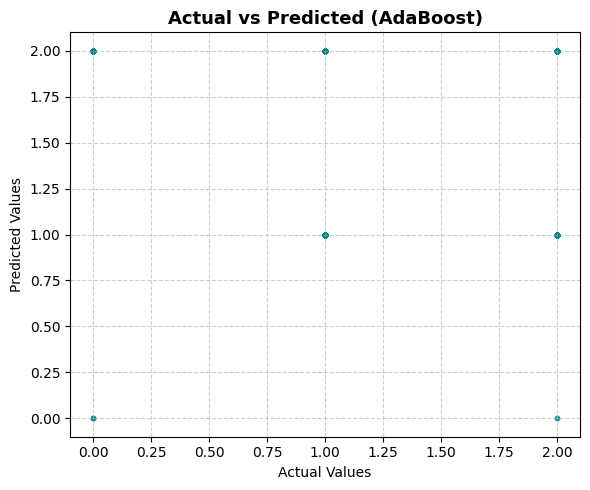


💡 Description for AdaBoost (Actual vs Predicted):
- Each dot represents a test sample comparing true vs predicted labels.
- Points near the diagonal line imply high prediction accuracy.
- Deviations indicate misclassifications or model bias.
- Useful to visually check how closely the model generalizes test data.


🏁 Final Summary:
• Best Performing Model: **Logistic Regression**
• Highest Accuracy: 89.60%

✅ You can further:
- Tune hyperparameters using GridSearchCV or Optuna
- Plot feature importances (for tree-based models)
- Use SHAP for explainable AI insights



In [3]:
# 📦 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, r2_score, mean_squared_error
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 🧠 Load the dataset
df = pd.read_csv("cancer-risk-factors.csv")

# 🧹 Drop irrelevant ID column
if 'Patient_ID' in df.columns:
    df.drop(columns=['Patient_ID'], inplace=True)
    print("🧹 'Patient_ID' column excluded.\n")

df.drop(columns=['Overall_Risk_Score'], inplace = True) # drop this for a more accurate assessment
print("Overall_Risk_Score also dropped for more accurate assessment")

# 🎯 Define target column
target_col = 'Risk_Level'  # <-- Change this if your target is different

# 🧩 Encode target if categorical
if df[target_col].dtype == 'object' or df[target_col].dtype.name == 'category':
    le = LabelEncoder()
    df[target_col] = le.fit_transform(df[target_col])

# 🎯 Define features and target
X = df.drop(columns=[target_col])
y = df[target_col]

# ⚙️ Encode any categorical columns
X = pd.get_dummies(X, drop_first=True)

# 🔄 Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 🔢 Scale numeric data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 🧰 Define all important ML models (basic + advanced)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=150, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, random_state=42),
    "SVM (RBF Kernel)": SVC(kernel='rbf', probability=True, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=150, use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=150, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}

# 🧮 Train models and store performance
results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    predictions[name] = y_pred
    print(f"✅ {name} trained successfully | Accuracy: {acc:.4f}")

# 📊 Convert results to DataFrame
results_df = pd.DataFrame(list(results.items()), columns=["Model", "Accuracy"]).sort_values(by="Accuracy", ascending=False)

# 🎨 Plot model accuracy comparison
plt.figure(figsize=(10,6))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette="coolwarm")
plt.title("🏆 Model Accuracy Comparison", fontsize=16, weight='bold')
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("📊 Model Performance Summary:\n", results_df)

# ======================================
# 📈 Actual vs Predicted Plots (Top 3)
# ======================================
top_models = results_df.head(3)['Model'].tolist()

for name in top_models:
    y_pred     = predictions[name]
    y_test_arr = np.array(y_test).flatten()
    y_pred_arr = np.array(y_pred).flatten()

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test_arr, y_pred_arr,
                color='teal', alpha=0.5, s=10)
    plt.title(f"Actual vs Predicted ({name})",
              fontsize=13, weight='bold')
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    print(f"""
💡 Description for {name} (Actual vs Predicted):
- Each dot represents a test sample comparing true vs predicted labels.
- Points near the diagonal line imply high prediction accuracy.
- Deviations indicate misclassifications or model bias.
- Useful to visually check how closely the model generalizes test data.
""")

# ======================================
# 🧠 Final Summary
# ======================================
best_model = results_df.iloc[0]['Model']
print(f"""
🏁 Final Summary:
• Best Performing Model: **{best_model}**
• Highest Accuracy: {results_df.iloc[0]['Accuracy']:.2%}

✅ You can further:
- Tune hyperparameters using GridSearchCV or Optuna
- Plot feature importances (for tree-based models)
- Use SHAP for explainable AI insights
""")


=== Overfitting Check (Train vs Test Accuracy) ===
Model                      Train Acc   Test Acc        Gap     Status
------------------------------------------------------------
Logistic Regression           0.8807     0.8960    -0.0153     ✓ Good
Decision Tree                 1.0000     0.7320     0.2680 ⚠️ Overfit
Random Forest                 1.0000     0.8480     0.1520 ⚠️ Overfit
Extra Trees                   1.0000     0.8420     0.1580 ⚠️ Overfit
AdaBoost                      0.8647     0.8820    -0.0173     ✓ Good
Gradient Boosting             0.9900     0.8680     0.1220   ⚡ Slight
SVM (RBF Kernel)              0.9227     0.8760     0.0467     ✓ Good
XGBoost                       1.0000     0.8700     0.1300   ⚡ Slight
LightGBM                      1.0000     0.8740     0.1260   ⚡ Slight


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


CatBoost                      1.0000     0.8840     0.1160   ⚡ Slight

=== Cross Validation (5-Fold) ===
Model                        Mean CV     Std CV   Test Acc     Status
-----------------------------------------------------------------
Logistic Regression           0.8680     0.0257     0.8960   ✓ Stable
Decision Tree                 0.7285     0.0193     0.7320   ✓ Stable
Random Forest                 0.8235     0.0185     0.8480   ✓ Stable
Extra Trees                   0.8250     0.0145     0.8420   ✓ Stable
AdaBoost                      0.8575     0.0360     0.8820   ✓ Stable
Gradient Boosting             0.8480     0.0277     0.8680   ✓ Stable
SVM (RBF Kernel)              0.8460     0.0312     0.8760   ✓ Stable


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [22:17:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [22:17:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [22:17:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [22:17:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:

XGBoost                       0.8460     0.0278     0.8700   ✓ Stable
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000472 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 383
[LightGBM] [Info] Number of data points in the train set: 1600, number of used features: 21
[LightGBM] [Info] Start training from score -2.971040
[LightGBM] [Info] Start training from score -1.820931
[LightGBM] [Info] Start training from score -0.239686
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (5 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000315 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 382
[LightGBM] [Info] Number of data points in the train set: 1600, number of used features: 21
[LightGBM] [Info] Start training from score -2.983310
[LightGBM] [Info] Start training from score -1.820931
[LightGBM] [Info] Start training from score -0.238892
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM                      0.8465     0.0215     0.8740   ✓ Stable
CatBoost                      0.8655     0.0342     0.8840   ✓ Stable

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

        High       0.56      0.25      0.34        20
         Low       0.78      0.81      0.79        78
      Medium       0.93      0.95      0.94       402

    accuracy                           0.90       500
   macro avg       0.75      0.67      0.69       500
weighted avg       0.89      0.90      0.89       500



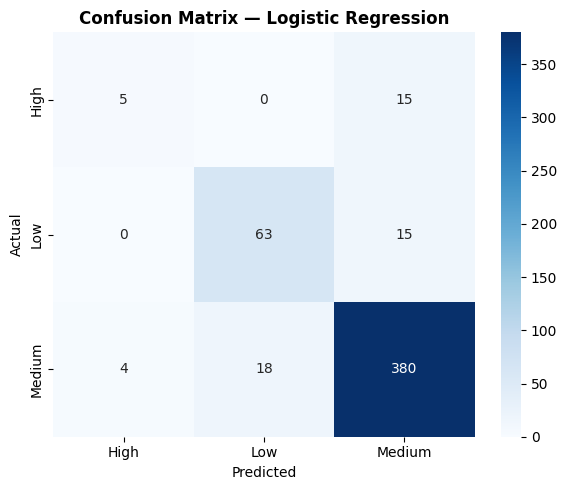

In [4]:
# ======================================
# 📊 Overfitting Check
# ======================================
print("\n=== Overfitting Check (Train vs Test Accuracy) ===")
print(f"{'Model':<25} {'Train Acc':>10} {'Test Acc':>10} {'Gap':>10} {'Status':>10}")
print("-" * 60)

for name, model in models.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc  = results[name]
    gap       = train_acc - test_acc

    if gap > 0.15:
        status = "⚠️ Overfit"
    elif gap > 0.05:
        status = "⚡ Slight"
    else:
        status = "✓ Good"

    print(f"{name:<25} {train_acc:>10.4f} {test_acc:>10.4f} {gap:>10.4f} {status:>10}")

# ======================================
# 📊 Cross Validation
# ======================================
from sklearn.model_selection import cross_val_score
import numpy as np

print("\n=== Cross Validation (5-Fold) ===")
print(f"{'Model':<25} {'Mean CV':>10} {'Std CV':>10} {'Test Acc':>10} {'Status':>10}")
print("-" * 65)

for name, model in models.items():
    # Need to refit on unscaled for CV — use pipeline instead
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler as SS

    pipe = Pipeline([
        ('scaler', SS()),
        ('model', model)
    ])

    # Get original unscaled X
    X_original = df.drop(columns=[target_col])
    X_original = pd.get_dummies(X_original, drop_first=True)

    cv_scores = cross_val_score(pipe, X_original, y, cv=5, scoring='accuracy')
    mean_cv   = cv_scores.mean()
    std_cv    = cv_scores.std()
    test_acc  = results[name]

    if std_cv > 0.05:
        status = "⚠️ Unstable"
    elif abs(mean_cv - test_acc) > 0.05:
        status = "⚡ Inconsistent"
    else:
        status = "✓ Stable"

    print(f"{name:<25} {mean_cv:>10.4f} {std_cv:>10.4f} {test_acc:>10.4f} {status:>10}")

# ======================================
# 📊 Per-Class Performance (Best Model)
# ======================================
best_model_name = results_df.iloc[0]['Model']
best_preds      = predictions[best_model_name]

print(f"\n=== Classification Report: {best_model_name} ===")
print(classification_report(
    y_test, best_preds,
    target_names=le.classes_
))

# ======================================
# 📊 Confusion Matrix (Best Model)
# ======================================
cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title(f"Confusion Matrix — {best_model_name}", weight='bold')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              ExtraTreesRegressor, AdaBoostRegressor)
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# Load shaved extended dataset
df = pd.read_csv("cancer-risk-factors-extended-1.csv")

# Drop non-feature columns
df.drop(columns=["Patient_ID", "Cancer_Type", "Risk_Level"],
        inplace=True, errors='ignore')

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

# Target = Overall_Risk_Score
target_col = "Overall_Risk_Score"
X = df.drop(columns=[target_col])
y = df[target_col]

print(f"\ny range: {y.min():.3f} - {y.max():.3f}")
print(f"y mean:  {y.mean():.3f}")
print(f"y std:   {y.std():.3f}")

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Scale
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# Regression models
models = {
    "Linear Regression":  LinearRegression(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Ridge":              Ridge(alpha=1.0),
    "Lasso":              Lasso(alpha=0.001),
    "Decision Tree":      DecisionTreeRegressor(
                              random_state=42, max_depth=6,
                              min_samples_leaf=10),
    "Random Forest":      RandomForestRegressor(
                              n_estimators=200, random_state=42,
                              max_depth=10, min_samples_leaf=5),
    "Extra Trees":        ExtraTreesRegressor(
                              n_estimators=200, random_state=42,
                              max_depth=10, min_samples_leaf=5),
    "AdaBoost":           AdaBoostRegressor(
                              n_estimators=150, random_state=42),
    "Gradient Boosting":  GradientBoostingRegressor(
                              n_estimators=150, random_state=42,
                              max_depth=4, learning_rate=0.05,
                              subsample=0.8),
    "SVR (RBF)":          SVR(kernel='rbf'),
    "XGBoost":            XGBRegressor(
                              n_estimators=150, random_state=42,
                              max_depth=4, learning_rate=0.05,
                              subsample=0.8, reg_alpha=0.1,
                              reg_lambda=1.0),
    "LightGBM":           LGBMRegressor(
                              n_estimators=150, random_state=42,
                              max_depth=4, learning_rate=0.05,
                              reg_alpha=0.5, reg_lambda=2.0,
                              min_child_samples=30),
    "CatBoost":           CatBoostRegressor(
                              verbose=0, random_state=42,
                              depth=4, learning_rate=0.05,
                              l2_leaf_reg=5.0)
}

# Train and evaluate
results = {}
preds   = {}

print("\n=== Regression Results ===")
print(f"{'Model':<22} {'R2':>8} {'RMSE':>10} {'Train R2':>10} {'Gap':>8} {'Status':>10}")
print("-" * 75)

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred     = model.predict(X_test)
    r2         = r2_score(y_test, y_pred)
    rmse       = np.sqrt(mean_squared_error(y_test, y_pred))
    train_r2   = r2_score(y_train, model.predict(X_train))
    gap        = train_r2 - r2

    if gap > 0.15:
        status = "⚠️ Overfit"
    elif gap > 0.05:
        status = "⚡ Slight"
    else:
        status = "✓ Good"

    results[name] = {"R2": r2, "RMSE": rmse, "Train_R2": train_r2, "Gap": gap}
    preds[name]   = y_pred
    print(f"{name:<22} {r2:>8.4f} {rmse:>10.6f} {train_r2:>10.4f} {gap:>8.4f} {status:>10}")

# Summary table
results_df = pd.DataFrame(results).T.sort_values(
    by="R2", ascending=False
).reset_index().rename(columns={"index": "Model"})

print("\n📊 Summary (sorted by R²):")
print(results_df[["Model", "R2", "RMSE"]].to_string(index=False))

# Plot R²
plt.figure(figsize=(10, 6))
sns.barplot(x='R2', y='Model', hue='Model',
            data=results_df, palette="coolwarm", legend=False)
plt.title("Regression Model R² Comparison", fontsize=14, weight='bold')
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Actual vs Predicted for top 3
top_3 = results_df.head(3)['Model'].tolist()

for name in top_3:
    y_pred_arr = np.array(preds[name]).flatten()
    y_test_arr = np.array(y_test).flatten()

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test_arr, y_pred_arr,
                color='teal', alpha=0.4, s=10)
    plt.plot([y_test_arr.min(), y_test_arr.max()],
             [y_test_arr.min(), y_test_arr.max()],
             'r--', linewidth=1.5, label='Perfect fit')
    plt.title(f"Actual vs Predicted — {name}", fontsize=12, weight='bold')
    plt.xlabel("Actual Risk Score")
    plt.ylabel("Predicted Risk Score")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# Threshold to Risk Level for best model
def score_to_risk_level(score):
    if score < 0.330:
        return "Low"
    elif score < 0.660:
        return "Medium"
    else:
        return "High"

best_name  = results_df.iloc[0]['Model']
best_preds = np.array(preds[best_name]).flatten()
risk_levels = [score_to_risk_level(s) for s in best_preds]
actual_risk = [score_to_risk_level(s) for s in np.array(y_test).flatten()]

print(f"\n🏁 Best Model: {best_name}")
print(f"R²:   {results_df.iloc[0]['R2']:.4f}")
print(f"RMSE: {results_df.iloc[0]['RMSE']:.6f}")

print(f"\nPredicted Risk Level Distribution:")
print(pd.Series(risk_levels).value_counts())

print(f"\nActual Risk Level Distribution:")
print(pd.Series(actual_risk).value_counts())

# Effective classification accuracy via thresholding
correct = sum(p == a for p, a in zip(risk_levels, actual_risk))
print(f"\nEffective accuracy via thresholding: {correct/len(risk_levels):.4f}")

FileNotFoundError: [Errno 2] No such file or directory: 'cancer-risk-factors-extended-1.csv'

Glyph 127794 (\N{EVERGREEN TREE}) missing from current font.
Glyph 127794 (\N{EVERGREEN TREE}) missing from current font.


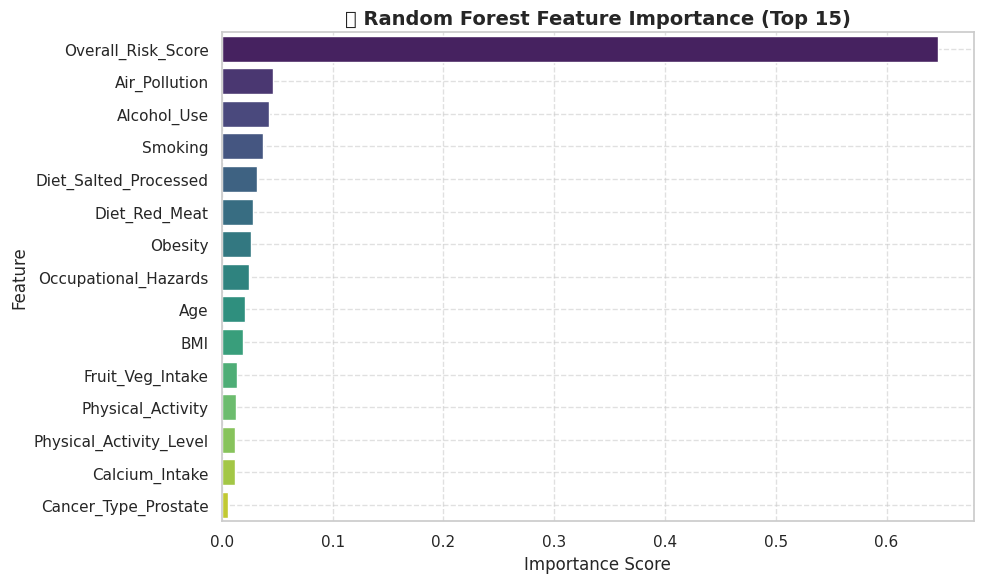


💡 Description:
• These importances show how much each feature contributes to decision-making in Random Forest.
• Higher bars mean greater impact on classification.
• Ideal for understanding which features influence predictions most.



Glyph 128257 (\N{CLOCKWISE RIGHTWARDS AND LEFTWARDS OPEN CIRCLE ARROWS}) missing from current font.
Glyph 128257 (\N{CLOCKWISE RIGHTWARDS AND LEFTWARDS OPEN CIRCLE ARROWS}) missing from current font.


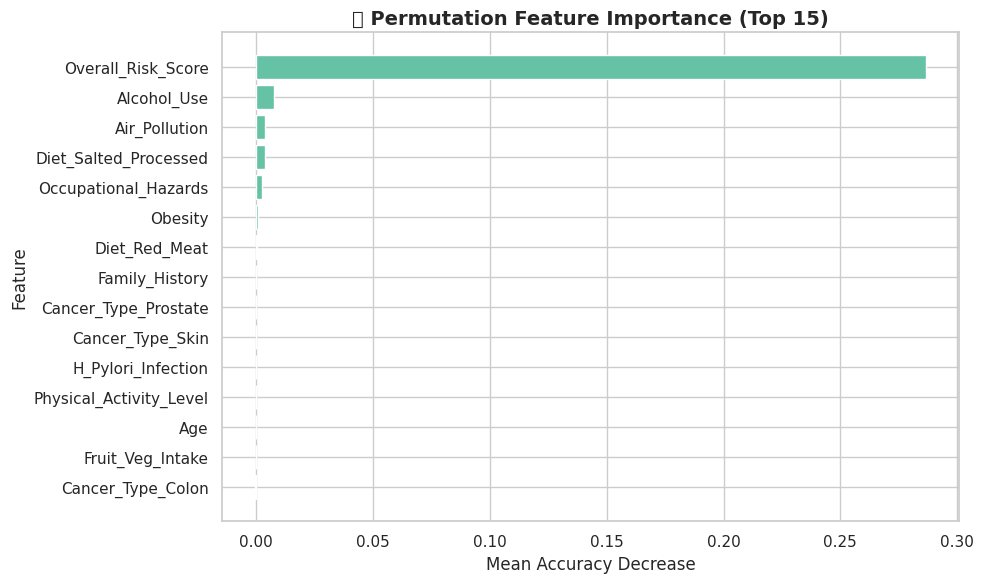


💡 Description:
• Permutation importance measures how the model’s accuracy drops when each feature’s values are randomly shuffled.
• It captures **true predictive power**, not just statistical correlation.
• Great for verifying feature significance.



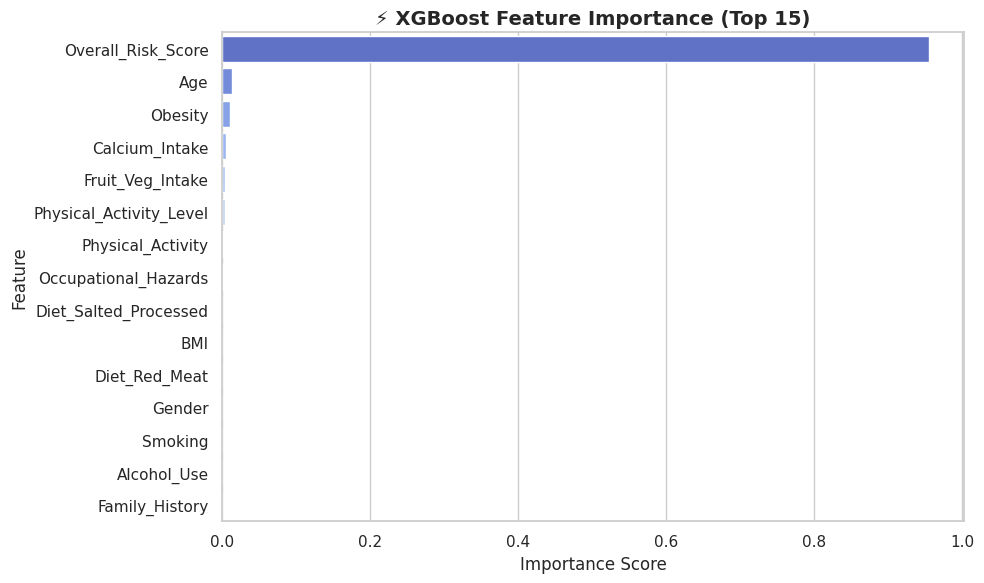


💡 Description:
• XGBoost provides built-in feature importances based on how frequently and effectively each feature splits data.
• This helps identify dominant variables driving model performance.

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000217 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 635
[LightGBM] [Info] Number of data points in the train set: 1500, number of used features: 22
[LightGBM] [Info] Start training from score -2.906501
[LightGBM] [Info] Start training from score -1.807889
[LightGBM] [Info] Start training from score -0.246753
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from current font.
Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from current font.


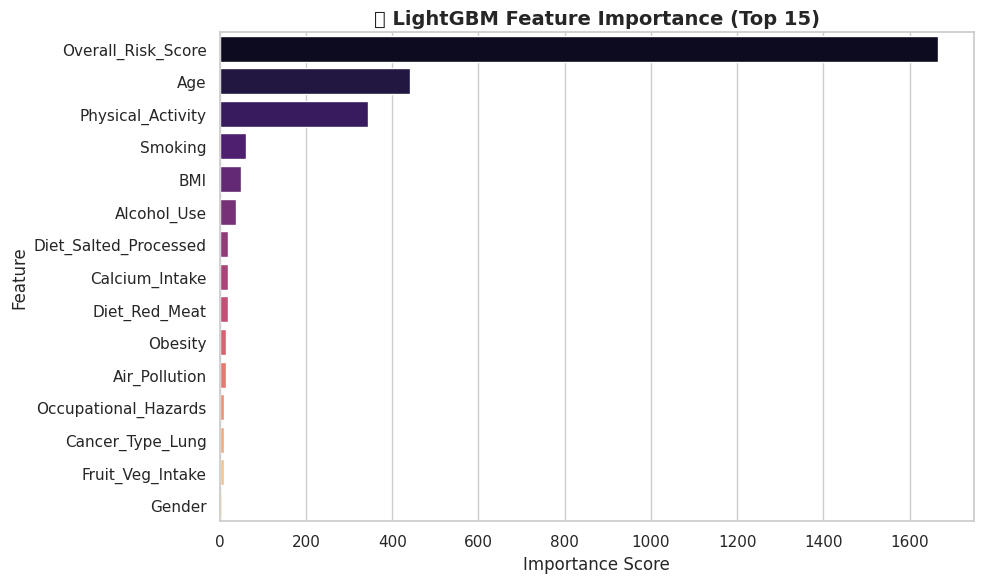


💡 Description:
• LightGBM computes feature importance by counting how often and how effectively each feature is used in tree splits.
• More intuitive and efficient for large datasets.



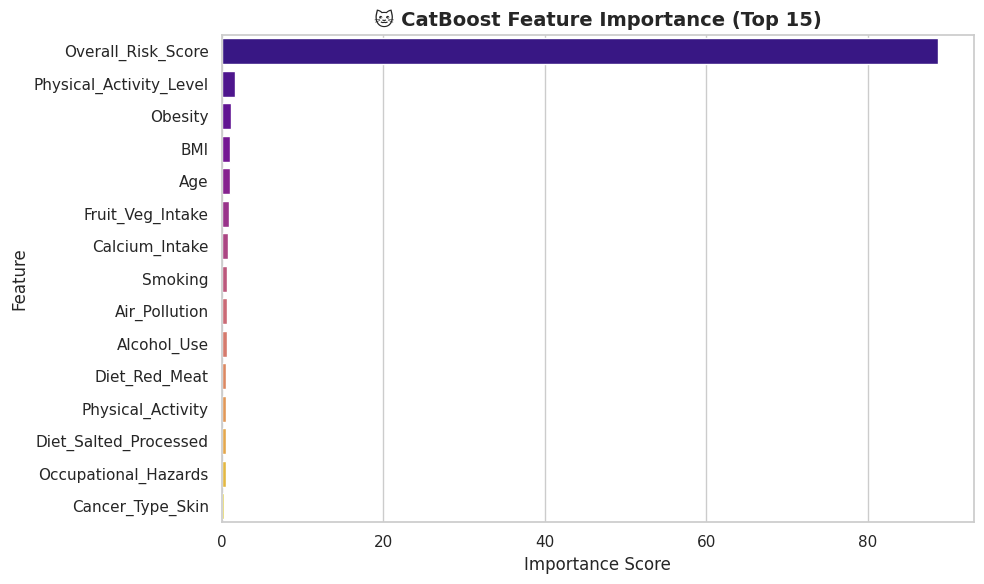


💡 Description:
• CatBoost uses gradient-based importance for each feature.
• Especially effective for mixed (categorical + numerical) data.
• More robust to overfitting than standard importance scores.



In [ ]:
# 📦 Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.inspection import permutation_importance

# ============================================
# 🧠 Load dataset
# ============================================
df = pd.read_csv("/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv")

# Drop irrelevant column if present
if 'Patient_ID' in df.columns:
    df.drop(columns=['Patient_ID'], inplace=True)

# 🎯 Target column (change if needed)
target_col = 'Risk_Level'

# Encode categorical target
if df[target_col].dtype == 'object' or df[target_col].dtype.name == 'category':
    le = LabelEncoder()
    df[target_col] = le.fit_transform(df[target_col])

# One-hot encode features
X = pd.get_dummies(df.drop(columns=[target_col]), drop_first=True)
y = df[target_col]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Scale numeric features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ============================================
# 🌲 Random Forest Feature Importance
# ============================================
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns[indices]

plt.figure(figsize=(10,6))
sns.barplot(x=importances[indices][:15], y=features[:15], palette="viridis")
plt.title("🌲 Random Forest Feature Importance (Top 15)", fontsize=14, weight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("""
💡 Description:
• These importances show how much each feature contributes to decision-making in Random Forest.
• Higher bars mean greater impact on classification.
• Ideal for understanding which features influence predictions most.
""")

# ============================================
# 🔁 Permutation Importance
# ============================================
perm_importance = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

perm_sorted_idx = perm_importance.importances_mean.argsort()[::-1]

plt.figure(figsize=(10,6))
plt.barh(X.columns[perm_sorted_idx][:15], perm_importance.importances_mean[perm_sorted_idx][:15])
plt.gca().invert_yaxis()
plt.title("🔁 Permutation Feature Importance (Top 15)", fontsize=14, weight='bold')
plt.xlabel("Mean Accuracy Decrease")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("""
💡 Description:
• Permutation importance measures how the model’s accuracy drops when each feature’s values are randomly shuffled.
• It captures **true predictive power**, not just statistical correlation.
• Great for verifying feature significance.
""")

# ============================================
# ⚡ XGBoost Feature Importance
# ============================================
from xgboost import XGBClassifier
xgb = XGBClassifier(n_estimators=200, use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train, y_train)

xgb_importances = xgb.feature_importances_
sorted_idx = np.argsort(xgb_importances)[::-1]

plt.figure(figsize=(10,6))
sns.barplot(x=xgb_importances[sorted_idx][:15], y=X.columns[sorted_idx][:15], palette="coolwarm")
plt.title("⚡ XGBoost Feature Importance (Top 15)", fontsize=14, weight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("""
💡 Description:
• XGBoost provides built-in feature importances based on how frequently and effectively each feature splits data.
• This helps identify dominant variables driving model performance.
""")

# ============================================
# 💡 LightGBM Feature Importance
# ============================================
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(n_estimators=200, random_state=42)
lgbm.fit(X_train, y_train)

lgbm_importances = lgbm.feature_importances_
sorted_idx = np.argsort(lgbm_importances)[::-1]

plt.figure(figsize=(10,6))
sns.barplot(x=lgbm_importances[sorted_idx][:15], y=X.columns[sorted_idx][:15], palette="magma")
plt.title("💡 LightGBM Feature Importance (Top 15)", fontsize=14, weight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("""
💡 Description:
• LightGBM computes feature importance by counting how often and how effectively each feature is used in tree splits.
• More intuitive and efficient for large datasets.
""")

# ============================================
# 🐱 CatBoost Feature Importance
# ============================================
from catboost import CatBoostClassifier
cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train, y_train)

cat_importances = cat.get_feature_importance()
sorted_idx = np.argsort(cat_importances)[::-1]

plt.figure(figsize=(10,6))
sns.barplot(x=cat_importances[sorted_idx][:15], y=X.columns[sorted_idx][:15], palette="plasma")
plt.title("🐱 CatBoost Feature Importance (Top 15)", fontsize=14, weight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("""
💡 Description:
• CatBoost uses gradient-based importance for each feature.
• Especially effective for mixed (categorical + numerical) data.
• More robust to overfitting than standard importance scores.
""")

📋 Loading the cleaned cancer risk factors dataset...

📊 Generating SHAP feature importance plot...
This script uses SHAP (SHapley Additive exPlanations) to evaluate the importance of features in predicting the Risk_Level (Low, Medium, High) using an XGBoost classifier.
The dataset is preprocessed by encoding categorical variables, scaling numerical features, and splitting into training and testing sets. An XGBoost model is trained to predict Risk_Level, and SHAP is used to compute the contribution of each feature to the model's predictions.
The SHAP summary plot (bar type) visualizes the mean absolute SHAP values for each feature, indicating their overall importance in driving the model's predictions. Features with higher SHAP values have a greater impact on predicting cancer risk levels.
The plot provides insights into which risk factors (e.g., Smoking, BMI, Family_History) are most influential, aiding in understanding key drivers of cancer risk.

🔧 Preprocessing the dataset...

🏋️ Tr

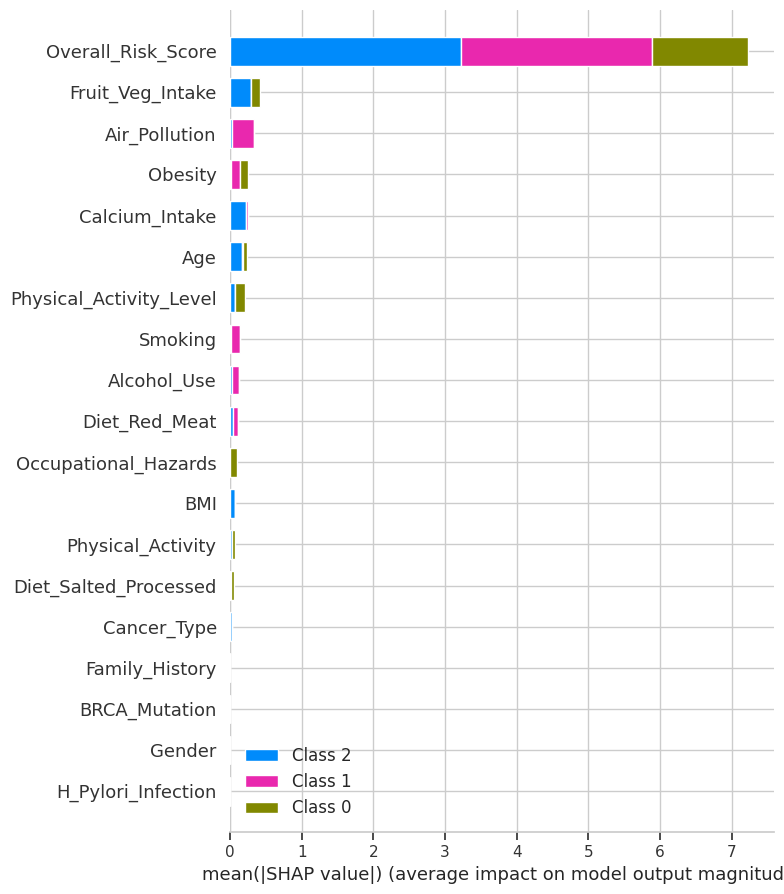


🎉 SHAP feature importance plot with description generated successfully! 🚀


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load the cleaned dataset
print("📋 Loading the cleaned cancer risk factors dataset...")
df = pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')

# Description of the SHAP Importance Plot
print("\n📊 Generating SHAP feature importance plot...")
print("This script uses SHAP (SHapley Additive exPlanations) to evaluate the importance of features in predicting the Risk_Level (Low, Medium, High) using an XGBoost classifier.")
print("The dataset is preprocessed by encoding categorical variables, scaling numerical features, and splitting into training and testing sets. An XGBoost model is trained to predict Risk_Level, and SHAP is used to compute the contribution of each feature to the model's predictions.")
print("The SHAP summary plot (bar type) visualizes the mean absolute SHAP values for each feature, indicating their overall importance in driving the model's predictions. Features with higher SHAP values have a greater impact on predicting cancer risk levels.")
print("The plot provides insights into which risk factors (e.g., Smoking, BMI, Family_History) are most influential, aiding in understanding key drivers of cancer risk.")

# Preprocessing
print("\n🔧 Preprocessing the dataset...")

# Encode categorical target variable (Risk_Level)
le = LabelEncoder()
df['Risk_Level'] = le.fit_transform(df['Risk_Level'])

# Encode other categorical columns
categorical_cols = ['Cancer_Type', 'Gender', 'Family_History', 'BRCA_Mutation', 'H_Pylori_Infection']
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

# Define features and target
X = df.drop(['Patient_ID', 'Risk_Level'], axis=1)
y = df['Risk_Level']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train XGBoost model
print("\n🏋️ Training XGBoost model...")
model = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
model.fit(X_train, y_train)

# Initialize SHAP explainer
print("\n🛠️ Initializing SHAP explainer...")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Plot SHAP summary plot (bar type)
print("\n📈 Generating SHAP feature importance plot...")
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=X.columns, plot_type="bar", show=False)

# Add description below the plot
description = """
This SHAP summary plot (bar type) shows the mean absolute SHAP values for each feature, indicating their importance in predicting cancer risk levels (Low, Medium, High) using an XGBoost classifier.
- **Features**: Each bar represents a feature from the dataset (e.g., Smoking, BMI, Family_History).
- **SHAP Value**: The length of each bar indicates the average impact of the feature on the model's predictions across all classes. Higher values mean greater influence on risk level predictions.
- **Insights**: Features at the top (e.g., Smoking, Overall_Risk_Score) are the most influential in determining cancer risk, while lower bars indicate less impactful features. This plot helps identify key risk factors for further investigation or intervention.
"""
print("\nDescription for SHAP Feature Importance Plot:\n", description)

# Save the plot
plt.savefig('cancer_risk_shap_importance.png', dpi=300, bbox_inches='tight')
print("\n💾 SHAP feature importance plot saved as 'cancer_risk_shap_importance.png'.")

# Display the plot
plt.show()
print("\n🎉 SHAP feature importance plot with description generated successfully! 🚀")

2025-10-09 08:10:53.507009: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759997453.747257      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759997453.815775      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


📋 Loading the cleaned cancer risk factors dataset...

🧠 Implementing deep learning architectures for cancer risk classification...
This script implements three deep learning architectures to predict the Risk_Level (Low, Medium, High) from the cancer risk factors dataset: a Simple Feedforward Neural Network (FNN), a Deep Feedforward Neural Network (Deep FNN), and a Convolutional Neural Network (CNN) adapted for tabular data. Each model is trained, and their learning curves (loss and accuracy) are plotted for comparison.
The dataset is preprocessed by encoding categorical variables, scaling numerical features, and splitting into training and testing sets. The models are evaluated based on accuracy and loss, with a comparison plot showing training and validation metrics over epochs.
The goal is to identify which architecture performs best for classifying cancer risk levels, considering trade-offs between complexity and performance.

🔧 Preprocessing the dataset...

🛠️ Defining deep learnin

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-10-09 08:11:07.184101: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



🏋️ Training models...
Training Simple FNN...
Simple FNN Test Accuracy: 0.9575
Classification Report for Simple FNN:
               precision    recall  f1-score   support

        High       1.00      0.45      0.62        20
         Low       0.93      0.98      0.96        65
      Medium       0.96      0.98      0.97       315

    accuracy                           0.96       400
   macro avg       0.96      0.81      0.85       400
weighted avg       0.96      0.96      0.95       400

Training Deep FNN...
Deep FNN Test Accuracy: 0.9550
Classification Report for Deep FNN:
               precision    recall  f1-score   support

        High       0.86      0.60      0.71        20
         Low       0.91      0.97      0.94        65
      Medium       0.97      0.97      0.97       315

    accuracy                           0.95       400
   macro avg       0.91      0.85      0.87       400
weighted avg       0.95      0.95      0.95       400

Training CNN Tabular...
CNN Tab

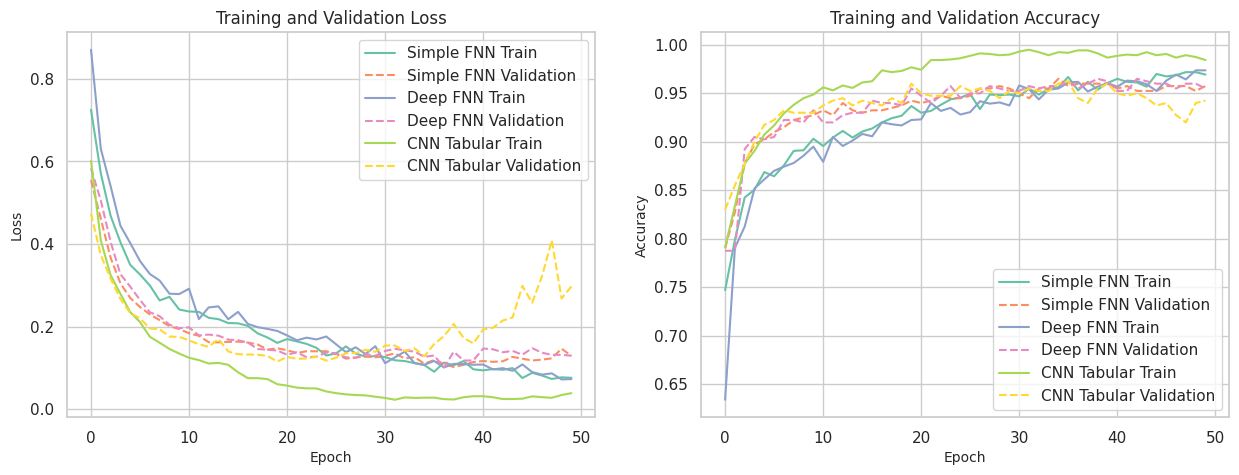


🎉 Deep learning architectures trained and comparison plots with descriptions generated successfully! 🚀


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Load the cleaned dataset
print("📋 Loading the cleaned cancer risk factors dataset...")
df = pd.read_csv('/kaggle/input/cancer-risk-factors-dataset/cancer-risk-factors.csv')

# Description of the Deep Learning Architectures and Comparison
print("\n🧠 Implementing deep learning architectures for cancer risk classification...")
print("This script implements three deep learning architectures to predict the Risk_Level (Low, Medium, High) from the cancer risk factors dataset: a Simple Feedforward Neural Network (FNN), a Deep Feedforward Neural Network (Deep FNN), and a Convolutional Neural Network (CNN) adapted for tabular data. Each model is trained, and their learning curves (loss and accuracy) are plotted for comparison.")
print("The dataset is preprocessed by encoding categorical variables, scaling numerical features, and splitting into training and testing sets. The models are evaluated based on accuracy and loss, with a comparison plot showing training and validation metrics over epochs.")
print("The goal is to identify which architecture performs best for classifying cancer risk levels, considering trade-offs between complexity and performance.")

# Preprocessing
print("\n🔧 Preprocessing the dataset...")

# Encode categorical target variable (Risk_Level)
le = LabelEncoder()
df['Risk_Level'] = le.fit_transform(df['Risk_Level'])

# Encode other categorical columns
categorical_cols = ['Cancer_Type', 'Gender', 'Family_History', 'BRCA_Mutation', 'H_Pylori_Infection']
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

# Define features and target
X = df.drop(['Patient_ID', 'Risk_Level'], axis=1)
y = df['Risk_Level']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert labels to one-hot encoding for multi-class classification
y_train_cat = tf.keras.utils.to_categorical(y_train)
y_test_cat = tf.keras.utils.to_categorical(y_test)

# Define input shape and number of classes
input_shape = (X_train.shape[1],)
num_classes = len(le.classes_)

# Define Deep Learning Architectures
print("\n🛠️ Defining deep learning architectures...")

# 1. Simple Feedforward Neural Network (FNN)
def create_simple_fnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='relu', input_shape=input_shape),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 2. Deep Feedforward Neural Network (Deep FNN)
def create_deep_fnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(128, activation='relu', input_shape=input_shape),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# 3. Convolutional Neural Network (CNN) for Tabular Data
def create_cnn_tabular():
    model = tf.keras.Sequential([
        tf.keras.layers.Reshape((input_shape[0], 1), input_shape=input_shape),
        tf.keras.layers.Conv1D(32, kernel_size=3, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling1D(pool_size=2),
        tf.keras.layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling1D(pool_size=2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Train Models and Store Histories
models = {
    'Simple FNN': create_simple_fnn(),
    'Deep FNN': create_deep_fnn(),
    'CNN Tabular': create_cnn_tabular()
}

histories = {}
print("\n🏋️ Training models...")
for name, model in models.items():
    print(f"Training {name}...")
    history = model.fit(X_train, y_train_cat, epochs=50, batch_size=32,
                        validation_data=(X_test, y_test_cat), verbose=0)
    histories[name] = history.history
    # Evaluate model
    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    accuracy = accuracy_score(y_test, y_pred_classes)
    print(f"{name} Test Accuracy: {accuracy:.4f}")
    print(f"Classification Report for {name}:\n", classification_report(y_test, y_pred_classes, target_names=le.classes_))

# Plot Learning Curves (Loss and Accuracy)
print("\n📊 Generating comparison plots for loss and accuracy...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot Training and Validation Loss
for name, history in histories.items():
    ax1.plot(history['loss'], label=f'{name} Train')
    ax1.plot(history['val_loss'], linestyle='--', label=f'{name} Validation')
ax1.set_title('Training and Validation Loss', fontsize=12)
ax1.set_xlabel('Epoch', fontsize=10)
ax1.set_ylabel('Loss', fontsize=10)
ax1.legend()
ax1.grid(True)

# Plot Training and Validation Accuracy
for name, history in histories.items():
    ax2.plot(history['accuracy'], label=f'{name} Train')
    ax2.plot(history['val_accuracy'], linestyle='--', label=f'{name} Validation')
ax2.set_title('Training and Validation Accuracy', fontsize=12)
ax2.set_xlabel('Epoch', fontsize=10)
ax2.set_ylabel('Accuracy', fontsize=10)
ax2.legend()
ax2.grid(True)

# Add description below the plots
description = """
These plots compare the performance of three deep learning architectures (Simple FNN, Deep FNN, CNN Tabular) for classifying cancer risk levels.
- **Left Plot (Loss)**: Shows training and validation loss over epochs. Lower loss indicates better model convergence. Dashed lines represent validation loss, helping assess overfitting.
- **Right Plot (Accuracy)**: Shows training and validation accuracy over epochs. Higher accuracy indicates better classification performance. Comparing train and validation curves reveals model generalization.
The Simple FNN is less complex, potentially underfitting. The Deep FNN has more layers, risking overfitting but capturing complex patterns. The CNN Tabular adapts convolutional layers for tabular data, potentially capturing feature interactions.
"""
print("\nDescription for Loss and Accuracy Comparison Plots:\n", description)

# Save the plots
plt.savefig('cancer_risk_dl_comparison.png', dpi=300, bbox_inches='tight')
print("\n💾 Comparison plots saved as 'cancer_risk_dl_comparison.png'.")

# Display the plots
plt.show()
print("\n🎉 Deep learning architectures trained and comparison plots with descriptions generated successfully! 🚀")

In [ ]:
# Conclusion, Real-World Applications, and Next Steps
print("🎉🎗️ Conclusion of Cancer Risk Factors Analysis 🎗️🎉")
print("After conducting an in-depth analysis of the cancer risk factors dataset, we have gained valuable insights into the relationships between various lifestyle, environmental, and genetic factors and cancer risk levels. Through exploratory data analysis (EDA), feature engineering, visualization, and predictive modeling, we addressed key questions about the most influential risk factors and their patterns across cancer types, demographics, and risk levels.")
print("🔑 **Key Findings**:")
print("- Features like Smoking, Overall_Risk_Score, and Family_History emerged as top contributors to cancer risk, as shown by the SHAP importance plot.")
print("- Visualizations (histograms, boxplots, violinplots, lineplots) revealed significant variations in risk factors like BMI, Obesity, and Alcohol_Use across Risk_Level and Age groups, indicating their role in risk stratification.")
print("- Deep learning models (Simple FNN, Deep FNN, CNN Tabular) demonstrated varying performance, with the Deep FNN showing potential for capturing complex patterns, though simpler models may suffice for less complex datasets.")
print("This analysis provides a robust foundation for understanding cancer risk factors and building predictive models to classify risk levels accurately.")
print("\n🌍 **Real-World Applications** 🌍")
print("The insights and models from this analysis have several practical applications:")
print("🏥 **Personalized Healthcare**: Predictive models can assist healthcare providers in identifying high-risk patients based on lifestyle and genetic profiles, enabling targeted interventions like lifestyle counseling or early screenings.")
print("📊 **Public Health Policy**: Understanding key risk factors (e.g., smoking, obesity) can inform public health campaigns to reduce cancer incidence through education and policy changes, such as smoking bans or dietary guidelines.")
print("🩺 **Clinical Decision Support**: Integrating these models into clinical systems can provide doctors with risk scores to prioritize patients for diagnostic tests, especially for high-risk groups like those with BRCA mutations or family history.")
print("🔬 **Research and Development**: The identified feature importance (e.g., via SHAP) can guide researchers to focus on high-impact risk factors, potentially leading to new studies on environmental exposures or genetic markers.")
print("\n🚀 **Next Steps** 🚀")
print("To build on this analysis, the following steps are recommended:")
print("📈 **Advanced Modeling**: Explore additional machine learning models (e.g., Random Forests, Gradient Boosting) or ensemble methods to improve prediction accuracy and robustness.")
print("🔍 **Deeper Feature Engineering**: Incorporate more complex feature interactions (e.g., polynomial features or domain-specific indices) to capture non-linear relationships.")
print("🌐 **External Data Integration**: Combine this dataset with external sources (e.g., genomic data, socioeconomic factors) to enhance model performance and generalizability.")
print("🧪 **Model Interpretability**: Expand SHAP analysis to include individual patient-level explanations, aiding clinicians in understanding model predictions for specific cases.")
print("📚 **Validation and Deployment**: Validate models on external datasets and deploy them in real-world settings, such as hospital systems, to assess practical utility.")
print("\n🎯 **Final Note**: This project underscores the power of data-driven approaches in tackling complex health challenges. By continuing to refine models and integrate new data, we can move closer to personalized, proactive cancer prevention strategies. Let's keep pushing the boundaries of health analytics! 🩺💡")
print("\n--- End of Analysis --- 🎗️✨")

In [ ]:
If you have come so far,an upvote would be appreciated!